# README

This notebook is organised as follows:

1.   **Recover** section contains recovery setup with an example of saving and loading data to google drive. This was used for longer experiments where the instance could timeout, such as LIME evaluation on Imagenet.
2.   **Setup** section contains commands for installing dependencies and defines functions to initialise datasets and models.
3.   **Metrics** section contains the implementations of the five metrics that we used to evaluate the explainability techniques.
4.   **Explainers** section contains wrappers/adapters for the different explainers to provide a unified interface to execute the experiments.
5.   **Experiments** section contains executions of all the experiments we conducted. Sections 2-4 should be expecuted prior to running anything in this section, and, optionally Section 1, as well as the Utils subsection, containing helper functions for visualization.
The comparative evaluation of the XAI techniques itself is organised by dataset, by model, then by method. Prior to running an experiment for a particular technique, initialisation for the dataset and model have to be executed.
Finally, this section also contains the code used to generate images included in the paper.

Known issues:

1.   GradCAM and GradCAM++ explainers seem to have a memory leak. This is not really perceptible in small-scale experiments, but running fidelity evaluation for 1000 Imagenet images using GradCAM or GradCAM++ explainers crashes the instance. A workaround for this is to re-initialise the model before running fidelity calculation.



# Recover

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# np.save("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_shap.npy", exps)
# exps = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_shap.npy", exps)

# Setup

In [ ]:
%%capture
%pip install shap grad-cam captum detectors tqdm
%pip install git+https://github.com/marcotcr/lime

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn as nn
import numpy as np
import os, json
import itertools
import sklearn
import sklearn.cluster
from functools import partial
import random
from statistics import mean
import time
from tqdm import tqdm
from functools import partial

import torch
from torchvision import models, transforms
from torch.autograd import Variable
import torch.nn.functional as F

import timm

from skimage.segmentation import slic, mark_boundaries, quickshift
from skimage.util import img_as_float32 as img_as_float
from skimage.util import random_noise

In [ ]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
# When running on the CuDNN backend, two further options must be set
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tqdm = partial(tqdm, position=0, leave=True)

## Utils

In [ ]:
def clean_axis(ax):
    ax.xaxis.set_ticklabels([])
    ax.yaxis.set_ticklabels([])
    ax.xaxis.set_ticks([])
    ax.yaxis.set_ticks([])
    ax.spines['bottom'].set_color(None)
    ax.spines['top'].set_color(None)
    ax.spines['right'].set_color(None)
    ax.spines['left'].set_color(None)

## Dataset

In [ ]:
N_IMAGES_PER_CLASS = 10

In [ ]:
imagenet_idx_to_imagenette = {
    0: 0,    # tench
    217: 1,  # English springer
    482: 2,  # cassette player
    491: 3,  # chain saw
    497: 4,  # church
    566: 5,  # French horn
    569: 6,  # garbage truck
    571: 7,  # gas pump
    574: 8,  # golf ball
    701: 9,  # parachute
}

In [ ]:
def get_sample_images(dataset, classes, n_images_per_class=N_IMAGES_PER_CLASS):
    images_by_class = [[] for c in classes]

    for image, cls in dataset:
        if len(images_by_class[cls]) == n_images_per_class:
            continue
        images_by_class[cls].append(image)
        if all(len(v) == n_images_per_class for v in images_by_class):
            break

    images = [j for i in images_by_class for j in i]
    labels = [c for c, i in enumerate(images_by_class) for j in i]
    return images, labels, images_by_class


def show_images_by_class(images_by_class):
    plt.figure()
    nrow = len(images_by_class)
    ncol = min(max([len(x) for x in images_by_class]), 10)
    _, axarr = plt.subplots(nrow, ncol, figsize=(ncol, nrow))
    for i, cls_images in enumerate(images_by_class):
        for j, img in enumerate(cls_images[:10]):
            axarr[i,j].imshow(img.convert('RGB'))
            axarr[i,j].axis("off")


def get_random_images_of_each_class(images_by_class, n_img=1):
    res = []
    for cls_images in images_by_class:
        res.extend(random.sample(cls_images, n_img))
    return res


In [ ]:
from torchvision.datasets import CIFAR100, CIFAR10, Imagenette, SVHN


def init_dataset(dataset_name):
    if dataset_name == "cifar100":
        dataset = CIFAR100(root="./data", download=True, train=False)
        classes = dataset.classes
        size, high_width, channels = 32, 32 * 32, 3
    elif dataset_name == "cifar10":
        dataset = CIFAR10(root="./data", download=True, train=False)
        classes = dataset.classes
        size, high_width, channels = 32, 32 * 32, 3
    elif dataset_name == "imagenet":
        dataset = Imagenette(
            root="./data",
            # download=True,
            split="val",
            transform=transforms.Compose(
                [
                    transforms.Resize((256, 256)),
                    transforms.CenterCrop(224)
                ]
            )
        )
        classes = dataset.classes
        size, high_width, channels = 224, 224 * 224, 3
    elif dataset_name == "svhn":
        dataset = SVHN(root="./data", download=True, split="test")
        classes = list(range(10))
        size, high_width, channels = 32, 32 * 32, 3
    else:
        raise Exception("Unsupported dataset")

    return dataset, classes, size, high_width, channels


## Model

In [ ]:
from detectors.data import CIFAR100_DEFAULT_MEAN, CIFAR100_DEFAULT_STD
from detectors.data import CIFAR10_DEFAULT_MEAN, CIFAR10_DEFAULT_STD
from detectors.data import IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD
from detectors.data import SVHN_DEFAULT_MEAN, SVHN_DEFAULT_STD


def get_preprocess_transform(dataset_name):
    if dataset_name == "cifar100":
        mean, std = CIFAR100_DEFAULT_MEAN, CIFAR100_DEFAULT_STD
    elif dataset_name == "cifar10":
        mean, std = CIFAR10_DEFAULT_MEAN, CIFAR10_DEFAULT_STD
    elif dataset_name == "imagenet":
        mean, std = IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD
    elif dataset_name == "svhn":
        mean, std = SVHN_DEFAULT_MEAN, SVHN_DEFAULT_STD
    else:
        raise Exception("Unsupported dataset")

    return transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ]
    )


def get_model(architecture_name, dataset_name):
    if architecture_name not in ("vgg16_bn", "resnet50", "densenet121"):
        raise Exception("Unsupported architecture")
    if dataset_name not in ("cifar100", "cifar10", "imagenet", "svhn"):
        raise Exception("Unsupported dataset")

    if dataset_name == "imagenet":
        weights = {
            "vgg16_bn": models.VGG16_BN_Weights,
            "resnet50": models.ResNet50_Weights,
            "densenet121": models.DenseNet121_Weights,
        }[architecture_name]
        model = getattr(models, architecture_name)(weights=weights)
    else:
        model = timm.create_model(f"{architecture_name}_{dataset_name}", pretrained=True)

    if architecture_name == "resnet50":
        target_layers = [model.layer4[-1]]
    elif architecture_name == "vgg16_bn":
        target_layers = [model.features[-2]]
    elif architecture_name == "densenet121":
        target_layers = [model.features[-1]]
    return model, target_layers


def get_batch_predict(model, preprocess_transform):

    def batch_predict(images):
        model.eval()
        batch = torch.stack(tuple(preprocess_transform(i) for i in images), dim=0)

        model.to(device)
        batch = batch.to(device)

        logits = model(batch)
        probs = F.softmax(logits, dim=1)
        return probs.detach().cpu().numpy()

    return batch_predict

# **Metrics**

In [ ]:
# UTILS

def dist(img1, img2):
    return np.sqrt(np.sum((img2 - img1)**2))


def auc(arr):
    """Returns normalized Area Under Curve of the array."""
    return (arr.sum() - arr[0] / 2 - arr[-1] / 2) / (arr.shape[0] - 1)


def minmax_scale(img):
    if np.min(img) == np.max(img):
        return img
    return (img - np.min(img)) / (np.max(img) - np.min(img))

In [ ]:
def calculate_identity(exps1, exps2):
    dis = np.array([np.array_equal(exps1[i],exps2[i]) for i in range(len(exps1))])
    total = dis.shape[0]
    true = np.sum(dis)
    score = (total-true)/total
    print('true:', true, 'wrong:', total-true, 'total:', total)
    return score*100, true, total


def calculate_separability(exps):
    wrong = 0
    for i in range(exps.shape[0]):
        for j in range(exps.shape[0]):
            if i == j:
                continue
            eq = np.array_equal(exps[i],exps[j])
            if eq:
                wrong += 1
    total = exps.shape[0]
    score = 100*abs(wrong)/(total**2-total)
    print('true:', total**2-total-wrong, 'wrong:', wrong, 'total:', total**2-total)
    return wrong, total, total**2-total, score


def calculate_stability_v2(images, explanations, explain_func):
    noise_technique = ("gaussian", "poisson", "speckle", "s&p")
    noise_technique = ("gaussian", "gaussian", "gaussian", "gaussian", "gaussian")
    n = len(noise_technique)
    score = []
    for image, explanation in zip(images, explanations):
        image = img_as_float(image)
        noisy_images = [random_noise(image, nt).astype(np.float32) for nt in noise_technique]
        noisy_explanations = [explain_func(ni) for ni in noisy_images]

        plt.figure(figsize=(15, 15))

        plt.subplot(1, 2 + 2*n, 1)
        plt.axis('off')
        plt.imshow(image)
        plt.subplot(1, 2 + 2*n, 2)
        plt.axis('off')
        plt.imshow(explanation)

        l_score = []
        for j, (s_i, s_e) in enumerate(zip(noisy_images, noisy_explanations)):
            plt.subplot(1, 2 + 2*n, 3+j*2)
            plt.axis('off')
            plt.imshow(s_i)
            plt.subplot(1, 2 + 2*n, 4+j*2)
            plt.axis('off')
            plt.imshow(s_e)

            exp_diff = explanation - s_e
            exp_diff_norm = np.linalg.norm(exp_diff)
            im_diff = img_as_float(image) - img_as_float(s_i)
            im_diff_norm = np.linalg.norm(im_diff)
            s = exp_diff_norm / im_diff_norm
            l_score.append(s)

        score.append(max(l_score))

    return score

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


# ----------------------------------------------------------------------
# Deletion curve for ONE image (also returns the occluded images for plotting)
# ----------------------------------------------------------------------
def deletion_curve(image, explanation, model, preprocess_transform, step,
                   method, sigma=2, dataset_mean=None, radius=2):
    img = to_float_image(image)
    h, w, _ = img.shape
    hw = h * w
    n_steps = math.ceil(hw / step)

    order = get_pixel_order(explanation, h, w)
    background = make_background(img, method, sigma, dataset_mean)

    imgs = []
    for i in range(n_steps + 1):
        mask = np.zeros(hw, dtype=bool)
        mask[order[:min(i * step, hw)]] = True
        imgs.append(occlude(img, mask.reshape(h, w), method, background, radius))

    probs = predict_probs(model, preprocess_transform, imgs)
    c = int(probs[0].argmax())                          # class of the intact image
    return probs[:, c], imgs, c


def auc(curve):
    """Area under the curve, x normalised to [0, 1] (trapezoid rule)."""
    curve = np.asarray(curve, dtype=np.float64)
    return float(((curve[:-1] + curve[1:]) / 2).sum() / (len(curve) - 1))


# ----------------------------------------------------------------------
# Visualisation of ONE image (same layout as before)
# ----------------------------------------------------------------------
def _explanation_2d(explanation, h, w):
    if torch.is_tensor(explanation):
        explanation = explanation.detach().cpu().numpy()
    e = np.squeeze(np.asarray(explanation, dtype=np.float32))
    if e.ndim == 3:
        e = e.mean(axis=0) if e.shape[0] in (1, 3) else e.mean(axis=-1)
    if e.shape != (h, w):
        e = cv2.resize(e, (w, h))
    return e


def plot_deletion(explanation, imgs, curve, c, step, score, method, get_class=None):
    n_steps = len(imgs) - 1
    h, w, ch = imgs[0].shape
    hw = h * w
    show_inds = sorted({min(int((n_steps + 1) * p), n_steps) for p in (0, 0.25, 0.5, 0.75)})
    n_cols = len(show_inds) + 2
    size = 4  # inches

    fig = plt.figure(figsize=(size * n_cols, size))

    # 1) explanation
    plt.subplot(1, n_cols, 1)
    plt.title(f"Explanation ({method})", fontsize=14)
    plt.imshow(_explanation_2d(explanation, h, w))
    if get_class is None:
        plt.axis('off')
    else:
        ax = plt.gca()
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_ylabel(str(get_class(c)), fontsize=14)

    # 2) occluded snapshots
    for k, i in enumerate(show_inds):
        plt.subplot(1, n_cols, k + 2)
        pct = 100 * min(i * step, hw) / hw
        plt.title('Pixels deleted {:.1f}%, P={:.4f}'.format(pct, curve[i]), fontsize=14)
        plt.axis('off')
        im = imgs[i]
        plt.imshow(im[..., 0], cmap='gray', vmin=0, vmax=1) if ch == 1 \
            else plt.imshow(np.clip(im, 0, 1))

    # 3) deletion curve
    plt.subplot(1, n_cols, n_cols)
    plt.xlim(-0.1, 1.1)
    plt.ylim(0, 1.05)
    plt.fill_between(np.arange(n_steps + 1) / n_steps, 0, curve, alpha=0.4)
    plt.title(f"Score: {round(score, 4)}", fontsize=14)
    plt.xlabel("Pixels deleted", fontsize=14)
    plt.ylabel("Prediction score", fontsize=14)

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# Shared loop over the dataset
# ----------------------------------------------------------------------
def _fidelity(images, explanations, model, preprocess_transform, step, method,
              print_every=None, get_class=None, return_curves=False, **kwargs):
    scores, all_curves = [], []
    pairs = list(zip(images, explanations))
    for idx, (im, ex) in enumerate(tqdm(pairs, desc=method)):
        curve, imgs, c = deletion_curve(im, ex, model, preprocess_transform,
                                        step, method, **kwargs)
        score = auc(curve)
        scores.append(score)
        all_curves.append(curve)
        if print_every and idx % print_every == 0:
            h, w, _ = imgs[0].shape
            plot_deletion(ex, imgs, curve, c, step, score, method, get_class)
    return (scores, all_curves) if return_curves else scores


# ----------------------------------------------------------------------
# The four public functions
# ----------------------------------------------------------------------
def calculate_fidelity1(images, explanations, model, preprocess_transform, step,
                        print_every=None, get_class=None, return_curves=False):
    """Black-pixel replacement."""
    return _fidelity(images, explanations, model, preprocess_transform, step, "black",
                     print_every, get_class, return_curves)


def calculate_fidelity2(images, explanations, model, preprocess_transform, step,
                        sigma=2, print_every=None, get_class=None, return_curves=False):
    """Gaussian-blur replacement."""
    return _fidelity(images, explanations, model, preprocess_transform, step, "blur",
                     print_every, get_class, return_curves, sigma=sigma)


def calculate_fidelity3(images, explanations, model, preprocess_transform, step,
                        dataset_mean=None, print_every=None, get_class=None,
                        return_curves=False):
    """Mean-value replacement."""
    return _fidelity(images, explanations, model, preprocess_transform, step, "mean",
                     print_every, get_class, return_curves, dataset_mean=dataset_mean)


def calculate_fidelity4(images, explanations, model, preprocess_transform, step,
                        radius=2, print_every=None, get_class=None, return_curves=False):
    """Inpainting-based replacement (OpenCV Telea)."""
    return _fidelity(images, explanations, model, preprocess_transform, step, "inpaint",
                     print_every, get_class, return_curves, radius=radius)

# Explainers

In [ ]:
class ExplainerAdapter(object):
    def __init__(self, model, target_layers, preprocess_transform, img_size, img_channels):
        self.model = model
        self.target_layers = target_layers
        self.preprocess_transform = preprocess_transform
        self.batch_predict = get_batch_predict(model, preprocess_transform)

        self.img_size = img_size
        self.img_channels = img_channels

        self.explainer = self.init_explainer()

    def init_explainer(self):
        raise NotImplementedError

    def pre_explain(self):
        pass

    def get_extra_from_image(self, image):
        return {}

    def get_input_from_image(self, image):
        return image

    def explain(self, input, **kwargs):
        raise NotImplementedError

    def postprocess_explanation(self, explanation):
        raise NotImplementedError

    def timed_single_explain(self, image):
        self.pre_explain()

        input = self.get_input_from_image(image)
        extra = self.get_extra_from_image(image)

        t = time.time()
        exp = self.explain(input, **extra)
        t = time.time() - t

        return self.postprocess_explanation(exp), t

    def timed_batch_explain(self, images):
        exps = []
        times = []

        for image in tqdm(images):
            exp, t = self.timed_single_explain(image)
            exps.append(exp)
            times.append(t)

        return np.array(exps), np.mean(times)

### LIME

In [ ]:
from lime.lime_image import LimeImageExplainer
from lime.wrappers.scikit_image import SegmentationAlgorithm

In [ ]:
class LimeExplainerAdapter(ExplainerAdapter):
    def init_explainer(self):
        return LimeImageExplainer()

    def get_input_from_image(self, image):
        return np.array(image)

    def explain(self, input):
        return self.explainer.explain_instance(
            input,
            self.batch_predict, # classification function
            top_labels=5,
            # hide_color=0,
            num_samples=1000,
            # segmentation_fn=SegmentationAlgorithm(
            #     'quickshift', kernel_size=1, max_dist=16, ratio=0.2, random_seed=1
            # )
            progress_bar=False,
        )

    def postprocess_explanation(self, exp):
        exp = exp.get_image_and_mask(
            exp.top_labels[0],
            positive_only=True,
            num_features=5,
            hide_rest=True
        )[1]
        exp = minmax_scale(exp)
        return exp

### SHAP

In [ ]:
import shap

In [ ]:
class ShapExplainerAdapter(ExplainerAdapter):
    def init_explainer(self):
        return shap.Explainer(
            self.batch_predict,
            shap.maskers.Image(
                f"blur({self.img_size},{self.img_size})",
                (self.img_size, self.img_size, self.img_channels)
            )
        )

    def get_input_from_image(self, image):
        return np.array([image])

    def explain(self, input):
        return self.explainer(input, outputs=shap.Explanation.argsort.flip[:1], silent=True)

    def postprocess_explanation(self, exp):
        exp = exp[0][:,:,:,0].values
        exp = np.mean(exp, axis=2)
        exp[exp < 0] = 0
        exp = minmax_scale(exp)
        return exp

### GradCam/GradCam++

In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus, GradCAM, FullGrad, EigenCAM, EigenGradCAM, AblationCAM, ScoreCAM, HiResCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus, GradCAM, FullGrad, EigenCAM, EigenGradCAM, AblationCAM, ScoreCAM, HiResCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

class GradExplainerAdapter(ExplainerAdapter):
    def pre_explain(self):
        self.model.eval()
        self.model.to(device)

    def get_input_from_image(self, image):
        input = self.preprocess_transform(image).unsqueeze(0).to(device)
        input.requires_grad = True
        return input

    def postprocess_explanation(self, exp):
        return exp[0]

class CAMExplainerAdapter(GradExplainerAdapter):
    def explain(self, input):
        # Get the predicted class to use as target for GradCAM
        # Move to CPU and remove batch dimension for inverse transform
        single_image_tensor_cpu = input.detach().cpu().squeeze(0)

        # Get mean and std from the Normalize transform in preprocess_transform
        normalize_transform = self.preprocess_transform.transforms[1]
        mean_val = torch.tensor(normalize_transform.mean, device=single_image_tensor_cpu.device).view(-1, 1, 1)
        std_val = torch.tensor(normalize_transform.std, device=single_image_tensor_cpu.device).view(-1, 1, 1)

        # Un-normalize the tensor
        unnormalized_tensor = single_image_tensor_cpu * std_val + mean_val

        # Clamp values to [0, 1] as ToPILImage expects this range for float tensors
        # Then convert the tensor to a PIL Image
        image_for_predict = transforms.ToPILImage()(unnormalized_tensor.clamp(0, 1))

        # Perform prediction on the PIL image
        predictions = self.batch_predict([image_for_predict])
        target_category = np.argmax(predictions[0])

        # Call the explainer with the original preprocessed input and the target
        return self.explainer(input_tensor=input, targets=[ClassifierOutputTarget(target_category)])


class GradCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return GradCAM(model=self.model, target_layers=self.target_layers)


class GradCAMPlusPlusExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return GradCAMPlusPlus(model=self.model, target_layers=self.target_layers)


class AblationCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return AblationCAM(model=self.model, target_layers=self.target_layers)


class ScoreCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return ScoreCAM(model=self.model, target_layers=self.target_layers)


class EigenCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return EigenCAM(model=self.model, target_layers=self.target_layers)


class EigenGradCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return EigenGradCAM(model=self.model, target_layers=self.target_layers)


class FullGradExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return FullGrad(model=self.model, target_layers=self.target_layers)


class HiResCAMExplainerAdapter(CAMExplainerAdapter):
    def init_explainer(self):
        return HiResCAM(model=self.model, target_layers=self.target_layers)

### Intgrad, SmoothGrad

In [ ]:
from captum.attr import IntegratedGradients, NoiseTunnel

In [ ]:
class IntGradExplainerAdapter(GradExplainerAdapter):
    def pre_explain(self):
        super().pre_explain()
        # self.model.zero_grad()

    def init_explainer(self):
        return IntegratedGradients(self.model)

    def get_extra_from_image(self, image):
        return {"target": int(np.argmax(self.batch_predict([image]), axis=1)[0])}

    def postprocess_explanation(self, exp):
        exp = exp.squeeze(0).cpu().detach().numpy()
        exp = np.transpose(exp, (1, 2, 0))
        exp = np.mean(exp, axis=2)
        exp[exp < 0] = 0
        exp = minmax_scale(exp)
        return exp

    def explain(self, input, **kwargs):
        return self.explainer.attribute(
            inputs=input,
            baselines=input * 0,
            target=kwargs["target"],
            return_convergence_delta=False,
        )


class SmoothGradExplainerAdapter(IntGradExplainerAdapter):
    def init_explainer(self):
        return NoiseTunnel(super().init_explainer())

    def explain(self, input, **kwargs):
        return self.explainer.attribute(
            inputs=input,
            nt_type='smoothgrad',
            stdevs=0.2,
            nt_samples_batch_size=1,
            baselines=input * 0,
            target=kwargs["target"],
            return_convergence_delta=False,
            # internal_batch_size=1,
        )

# Experiments

## Utils

In [ ]:
# def evaluate_explainer(expr_name):
#     expr_class = {
#         "LIME": LimeExplainerAdapter,
#         "SHAP": ShapExplainerAdapter,
#         "GradCAM": GradCAMExplainerAdapter,
#         "GradCAM++": GradCAMPlusPlusExplainerAdapter,
#         "IntGrad": IntGradExplainerAdapter,
#         "SmoothGrad": SmoothGradExplainerAdapter,
#     }[expr_name]
#     print(f"Starting for {expr_name}, {model.pretrained_cfg['architecture']}")

#     expr = expr_class(model, target_layers, preprocess_transform, SIZE, CH)

#     exps, t = expr.timed_batch_explain(imgs)
#     exps_, t = expr.timed_batch_explain(imgs)
#     print(f"Mean time for {len(imgs)} explanations: {t}")

#     nrow, ncol = 2, 10
#     plt.figure()
#     _, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
#     for ix, i in enumerate(range(0, len(imgs), print_every_n)):
#         axarr[0, ix].imshow(imgs[i])
#         axarr[0, ix].axis(False)
#         axarr[1, ix].imshow(exps[i])
#         axarr[1, ix].axis(False)

#     scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
#     print(f"Fidelity score: {np.mean(scores)}")

#     scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
#     print(f"Stability score: {np.mean(scores)}")

#     score, _, _ = calculate_identity(exps, exps_)
#     print(f"Identity score: {score}")

#     _, _, _, score = calculate_separability(exps)
#     print(f"Separability score: {score}")

In [ ]:
def show_imgs_exps(imgs, exps, print_every_n):
    nrow, ncol = 2, 10
    plt.figure()
    _, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
    for ix, i in enumerate(range(0, len(imgs), print_every_n)):
        axarr[0, ix].imshow(imgs[i])
        axarr[0, ix].axis(False)
        axarr[1, ix].imshow(exps[i])
        axarr[1, ix].axis(False)

## CIFAR10

In [ ]:
#dataset, classes, SIZE, HW, CH = init_dataset("cifar10")

In [ ]:
#import pickle

#data_to_save = {
 #   "dataset": dataset,
  #  "classes": classes,
   # "SIZE": SIZE,
    #"HW": HW,
    #"CH": CH
#}

#with open('/content/drive/MyDrive/vars.pkl', 'wb') as f:
 #   pickle.dump(data_to_save, f)


In [ ]:
import pickle
with open('/content/drive/MyDrive/vars.pkl', 'rb') as f:
    saved = pickle.load(f)

dataset = saved["dataset"]
classes = saved["classes"]
SIZE = saved["SIZE"]
HW = saved["HW"]
CH = saved["CH"]


In [ ]:
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=100)
imgs = sample_images
print_every_n = int(len(imgs) / 10)

### VGG16_BN

In [ ]:
model, target_layers = get_model("vgg16_bn", "cifar10")
preprocess_transform = get_preprocess_transform("cifar10")
batch_predict = get_batch_predict(model, preprocess_transform)

Downloading: "https://huggingface.co/edadaltocg/vgg16_bn_cifar10/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/vgg16_bn_cifar10.pth


100%|██████████| 56.2M/56.2M [00:00<00:00, 84.4MB/s]


#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [13:14<00:00,  1.26it/s]

Mean time for 1000 explanations: 0.7980230929851532
Mean time for 1000 explanations: 0.7934749081134796


In [ ]:
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

Mean time for 1000 explanations: 0.7980230929851532
Mean time for 1000 explanations: 0.7934749081134796


<Figure size 640x480 with 0 Axes>

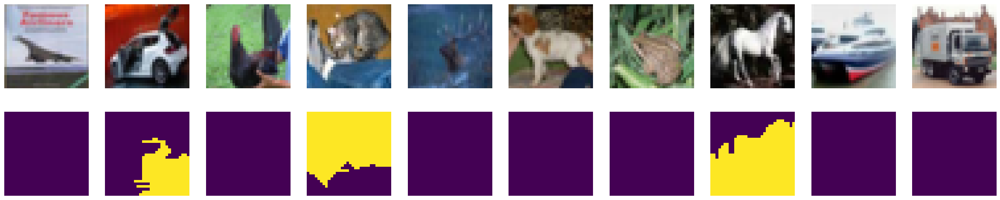

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

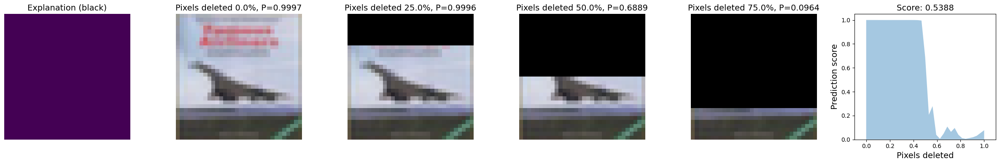

black:  10%|█         | 100/1000 [00:03<00:24, 36.61it/s]

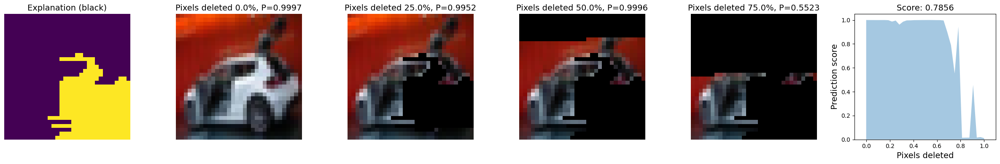

black:  20%|██        | 200/1000 [00:06<00:18, 43.79it/s]

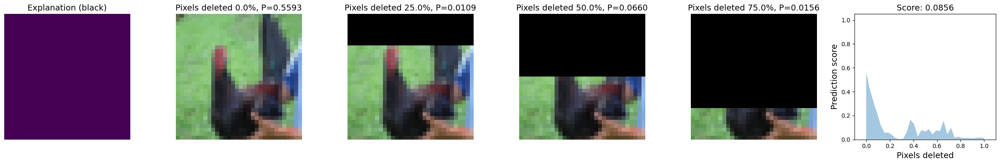

black:  30%|███       | 300/1000 [00:09<00:13, 52.85it/s]

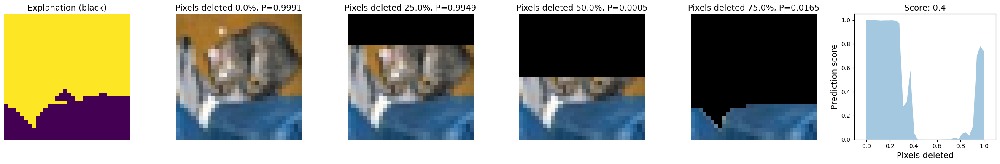

black:  40%|███▉      | 396/1000 [00:11<00:10, 56.11it/s]

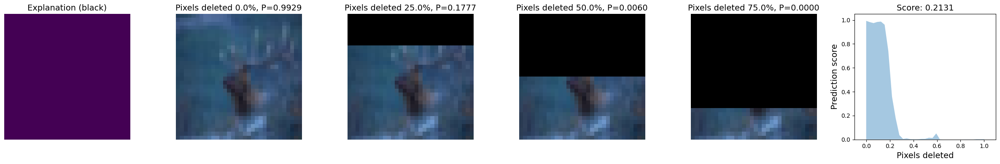

black:  50%|████▉     | 499/1000 [00:13<00:08, 55.76it/s]

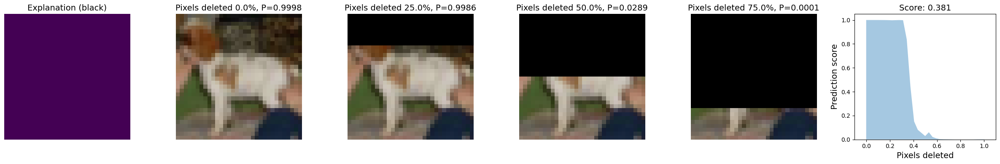

black:  60%|█████▉    | 595/1000 [00:15<00:07, 56.86it/s]

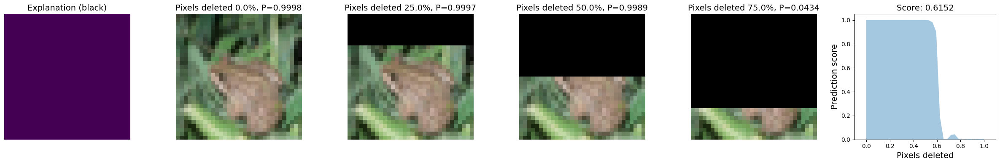

black:  70%|██████▉   | 697/1000 [00:17<00:05, 58.12it/s]

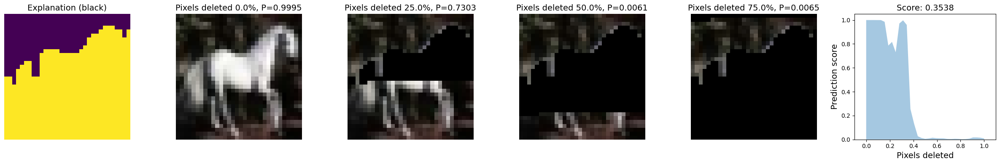

black:  80%|███████▉  | 798/1000 [00:20<00:04, 45.11it/s]

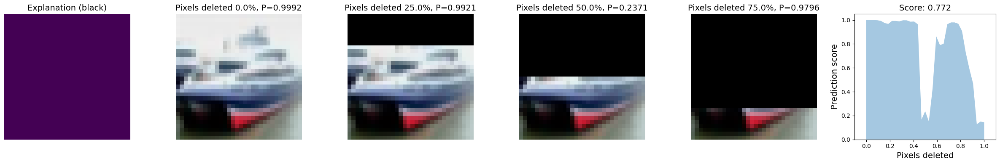

black:  90%|████████▉ | 897/1000 [00:23<00:01, 52.23it/s]

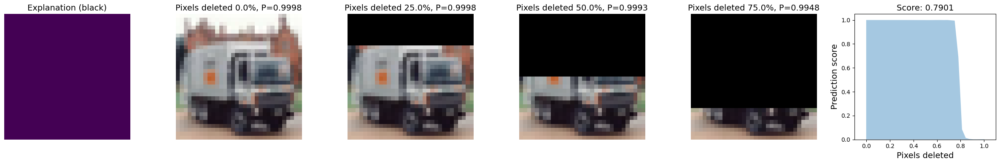

black: 100%|██████████| 1000/1000 [00:25<00:00, 39.24it/s]


np.float64(0.5263948792811499)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

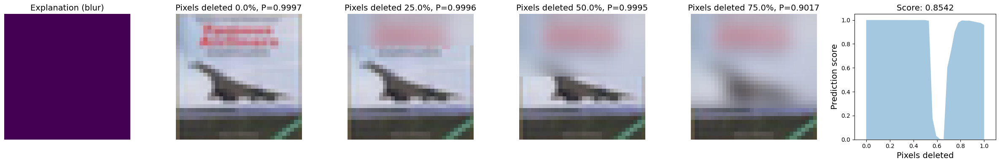

blur:  10%|▉         | 99/1000 [00:03<00:23, 39.01it/s]

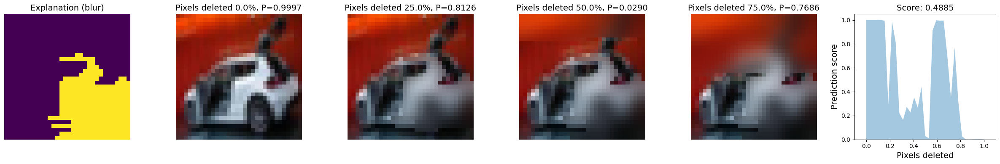

blur:  20%|█▉        | 199/1000 [00:06<00:21, 37.76it/s]

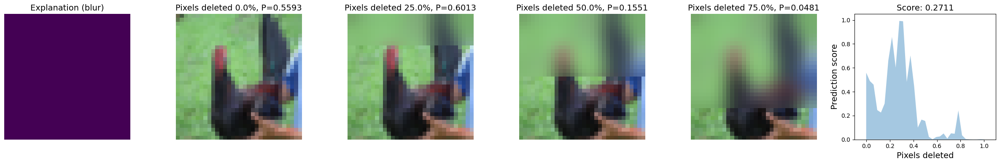

blur:  30%|██▉       | 296/1000 [00:09<00:12, 54.82it/s]

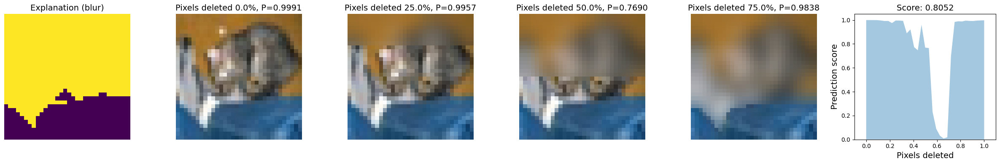

blur:  40%|███▉      | 397/1000 [00:11<00:13, 43.74it/s]

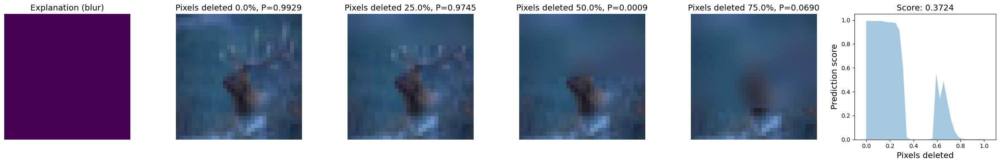

blur:  50%|████▉     | 496/1000 [00:14<00:09, 51.66it/s]

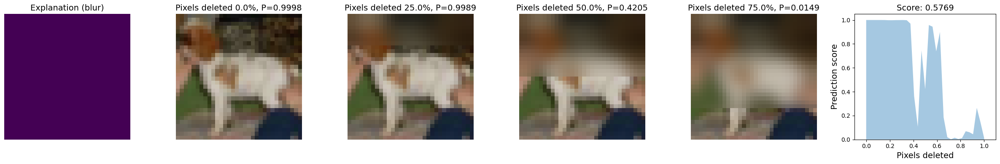

blur:  60%|█████▉    | 597/1000 [00:16<00:07, 55.17it/s]

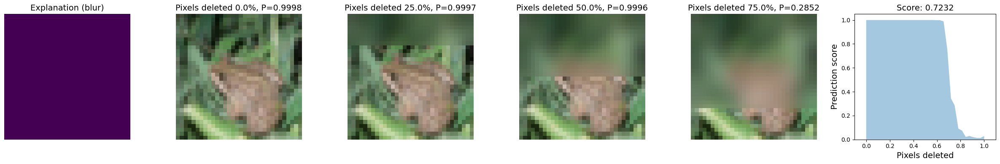

blur:  70%|██████▉   | 699/1000 [00:20<00:05, 54.42it/s]

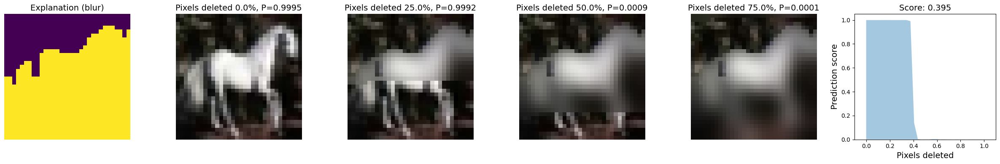

blur:  80%|███████▉  | 795/1000 [00:22<00:03, 54.30it/s]

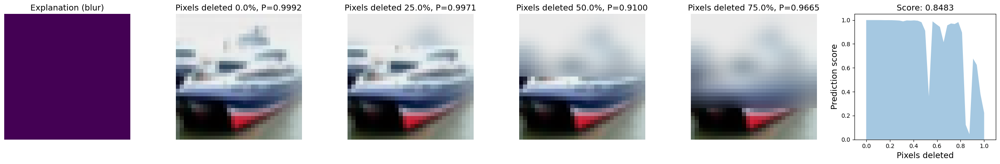

blur:  90%|████████▉ | 896/1000 [00:24<00:02, 48.06it/s]

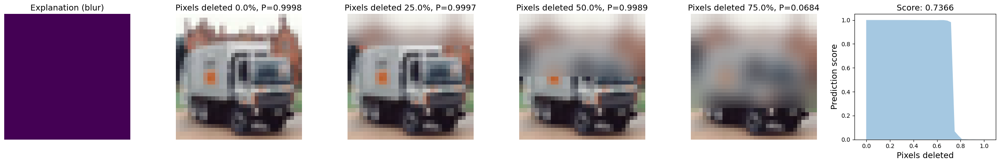

blur: 100%|██████████| 1000/1000 [00:27<00:00, 36.37it/s]


np.float64(0.6079155642888624)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

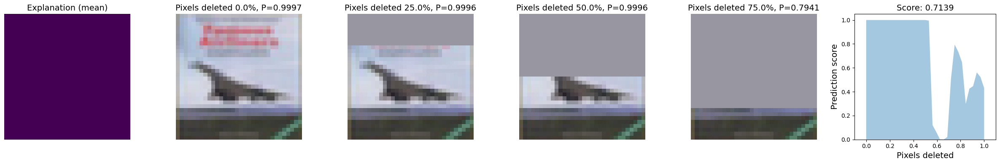

mean:  10%|█         | 100/1000 [00:05<00:28, 31.50it/s]

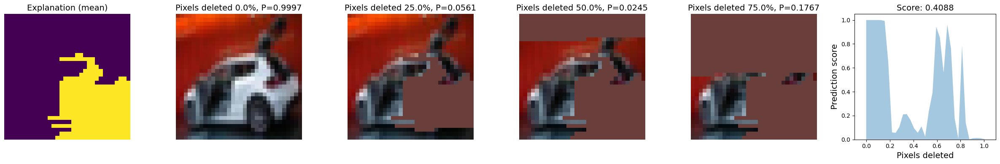

mean:  20%|██        | 200/1000 [00:08<00:20, 38.39it/s]

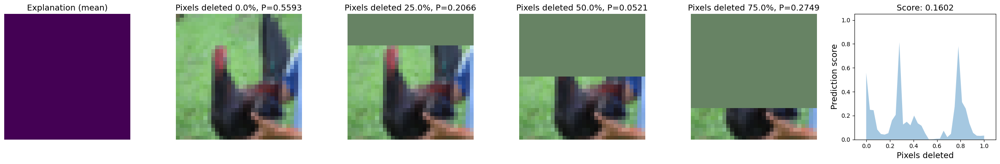

mean:  30%|███       | 300/1000 [00:11<00:12, 54.10it/s]

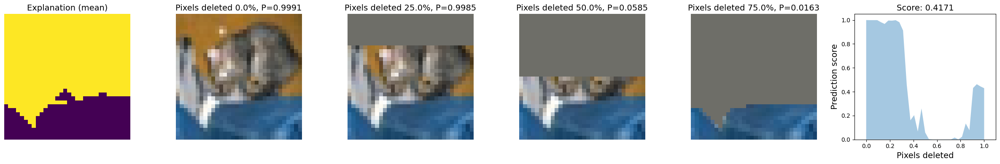

mean:  40%|███▉      | 395/1000 [00:13<00:10, 55.46it/s]

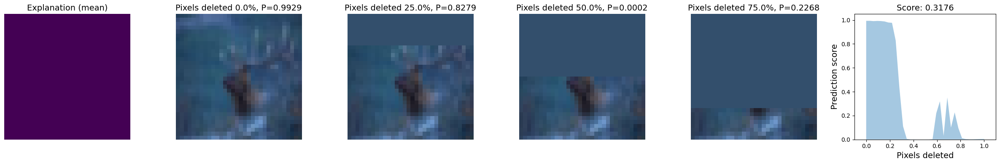

mean:  50%|████▉     | 498/1000 [00:16<00:10, 47.55it/s]

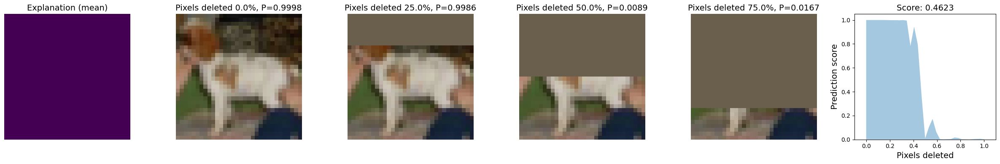

mean:  60%|█████▉    | 598/1000 [00:18<00:09, 41.89it/s]

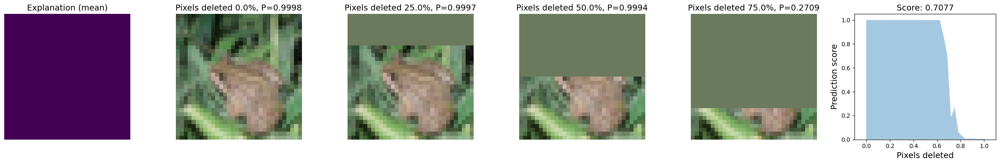

mean:  70%|██████▉   | 696/1000 [00:21<00:05, 54.92it/s]

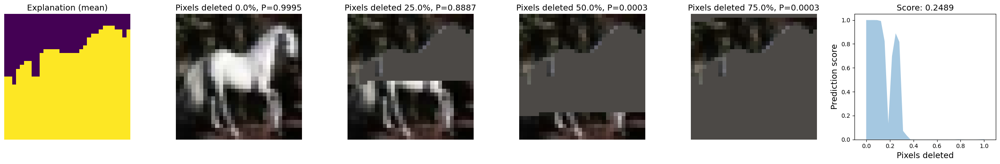

mean:  80%|███████▉  | 798/1000 [00:23<00:03, 55.53it/s]

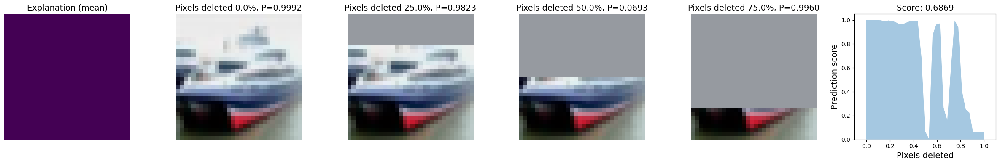

mean:  90%|█████████ | 900/1000 [00:25<00:01, 56.24it/s]

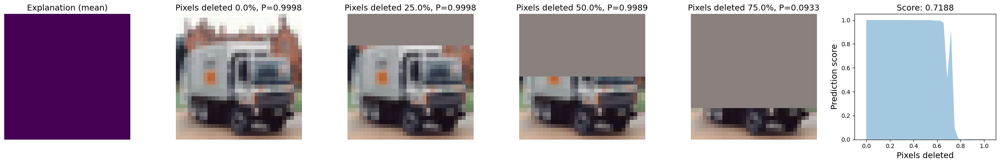

mean: 100%|██████████| 1000/1000 [00:28<00:00, 35.51it/s]


np.float64(0.5417071750338371)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

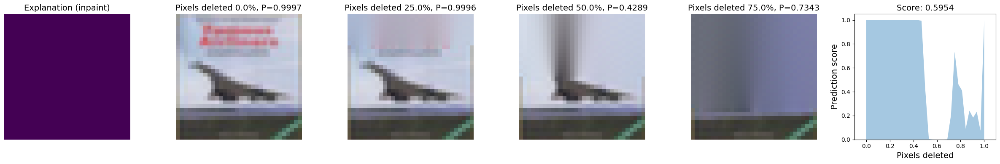

inpaint:  10%|▉         | 98/1000 [00:06<00:38, 23.32it/s]

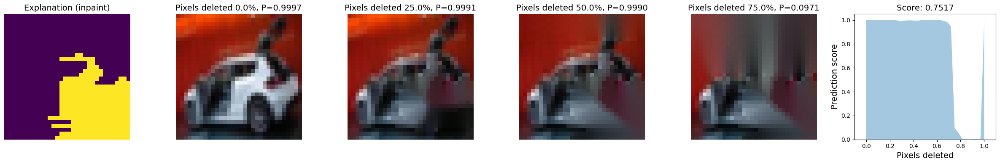

inpaint:  20%|█▉        | 199/1000 [00:11<00:32, 24.69it/s]

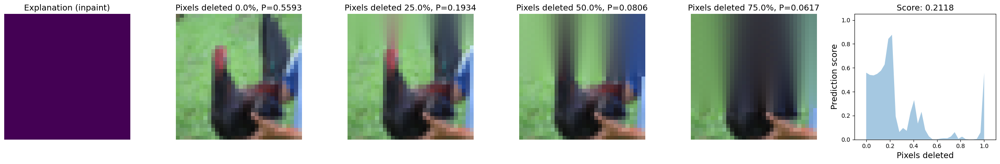

inpaint:  30%|██▉       | 298/1000 [00:15<00:21, 33.20it/s]

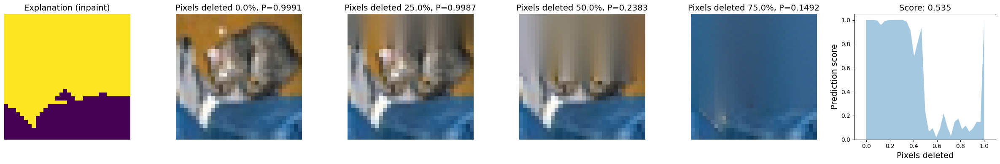

inpaint:  40%|███▉      | 398/1000 [00:19<00:18, 32.79it/s]

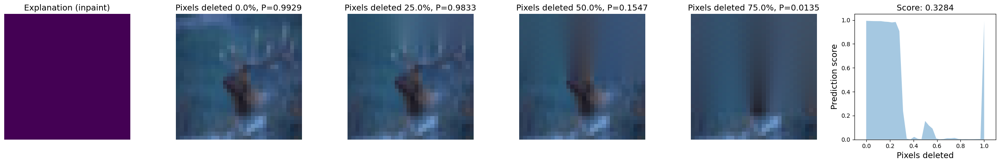

inpaint:  50%|████▉     | 498/1000 [00:23<00:15, 31.61it/s]

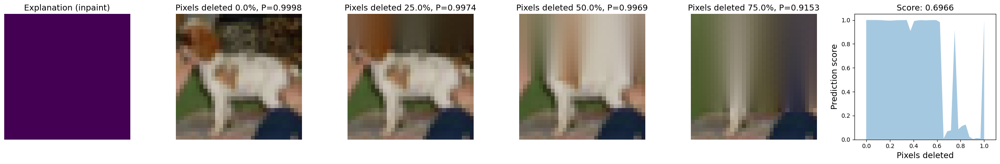

inpaint:  60%|█████▉    | 598/1000 [00:27<00:17, 23.20it/s]

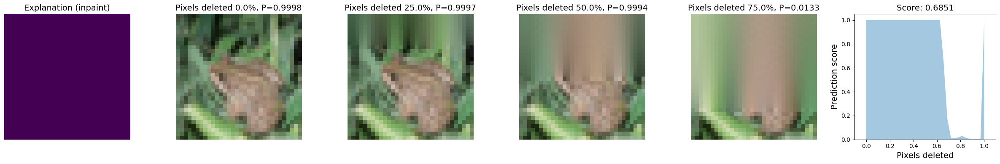

inpaint:  70%|███████   | 700/1000 [00:31<00:09, 32.20it/s]

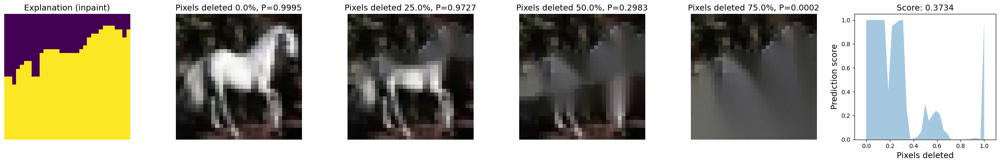

inpaint:  80%|███████▉  | 798/1000 [00:35<00:06, 31.54it/s]

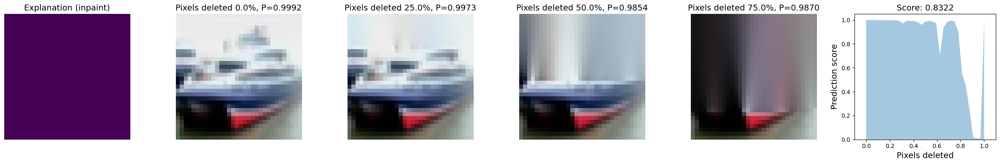

inpaint:  90%|████████▉ | 898/1000 [00:38<00:03, 31.90it/s]

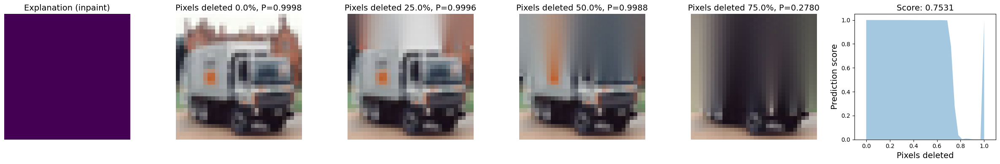

inpaint: 100%|██████████| 1000/1000 [00:43<00:00, 22.87it/s]


np.float64(0.585170071892681)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

1it [00:00,  9.23it/s]

0
100


301it [00:00, 808.45it/s]

200
300


501it [00:00, 884.60it/s]

400
500


... (2 outputs left out)

801it [00:00, 864.76it/s]

800
900


1000it [00:01, 598.80it/s]


np.float64(1.2915960386636973)

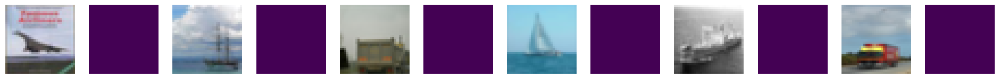

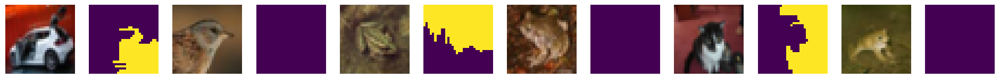

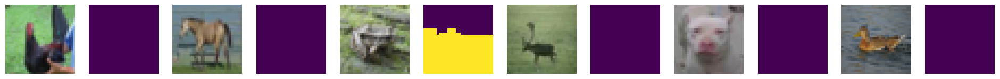

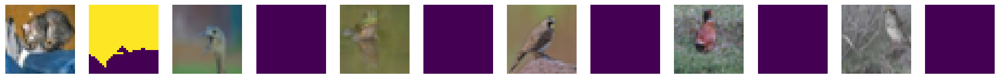

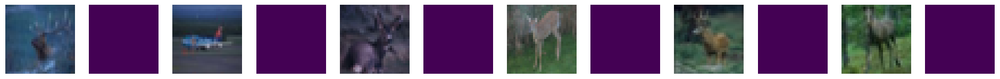

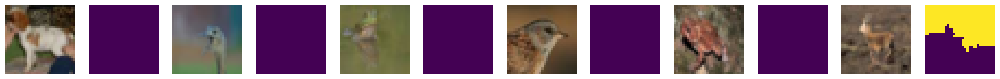

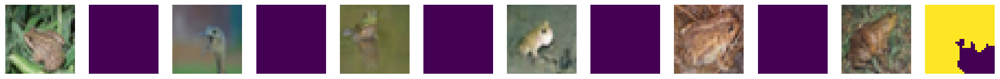

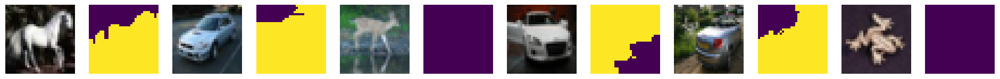

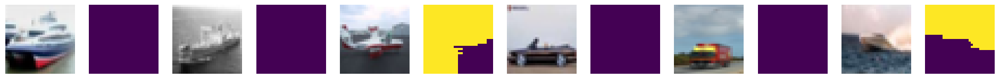

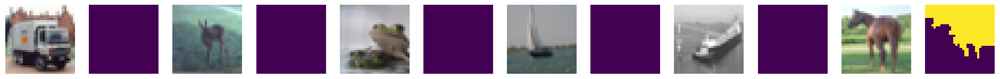

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 998 wrong: 2 total: 1000


np.float64(0.2)

<Figure size 640x480 with 0 Axes>

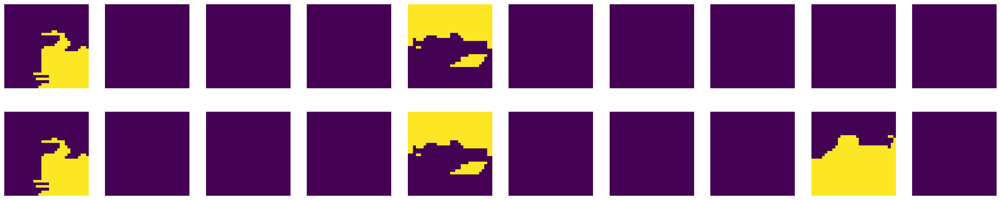

In [ ]:
nrow, ncol = 2, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix, i in enumerate(range(100, 110)):
    axarr[0, ix].imshow(exps[i])
    axarr[0, ix].axis(False)
    axarr[1, ix].imshow(exps_[i])
    axarr[1, ix].axis(False)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 374098 wrong: 624902 total: 999000


62.55275275275275

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [08:28<00:00,  1.97it/s]

Mean time for 1000 explanations: 0.5442029860019684
Mean time for 1000 explanations: 0.48023824882507327


<Figure size 640x480 with 0 Axes>

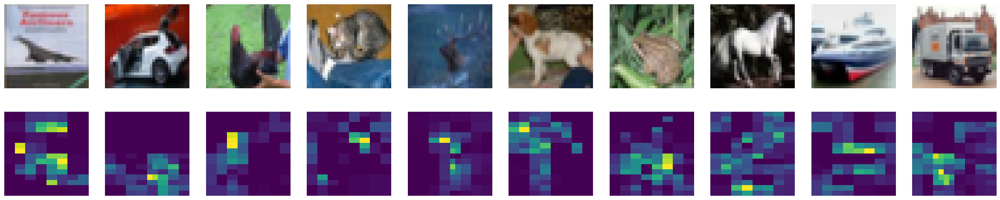

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

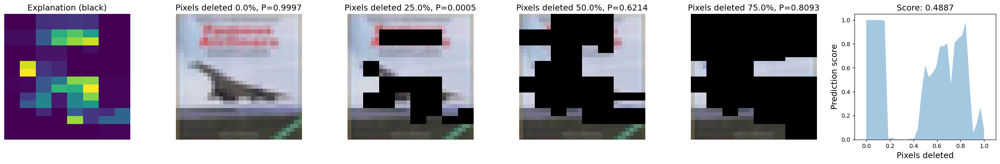

black:  10%|▉         | 96/1000 [00:02<00:18, 47.98it/s]

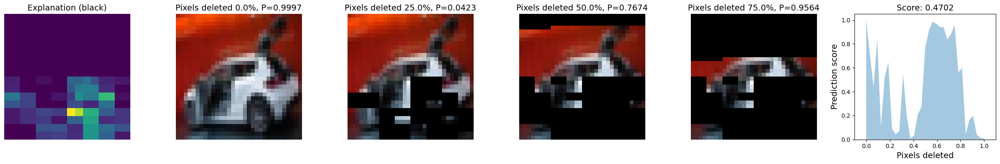

black:  20%|█▉        | 197/1000 [00:05<00:14, 55.98it/s]

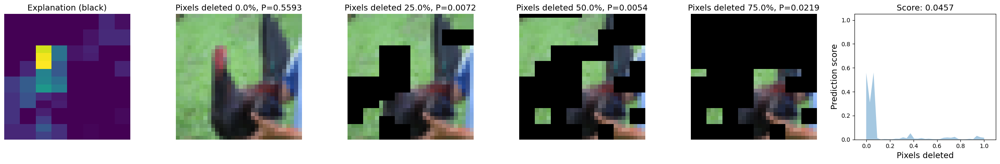

black:  30%|██▉       | 299/1000 [00:07<00:11, 58.48it/s]

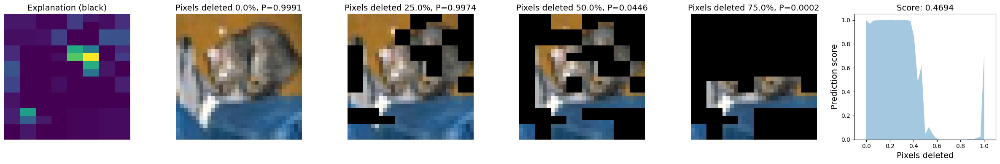

black:  39%|███▉      | 394/1000 [00:09<00:10, 59.71it/s]

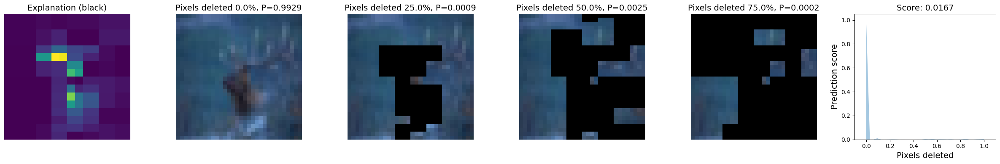

black:  50%|████▉     | 495/1000 [00:11<00:08, 58.78it/s]

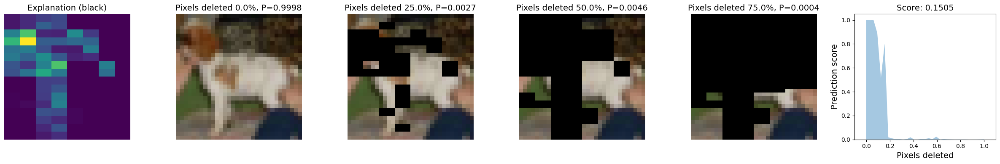

black:  59%|█████▉    | 594/1000 [00:13<00:06, 58.08it/s]

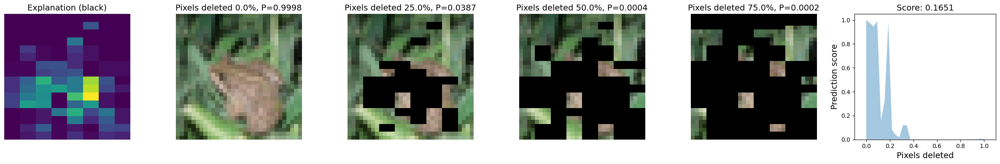

black:  70%|██████▉   | 699/1000 [00:16<00:06, 47.49it/s]

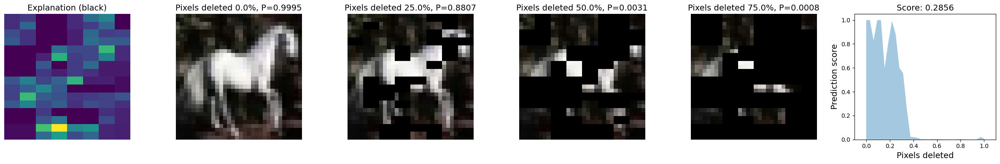

black:  80%|███████▉  | 798/1000 [00:18<00:03, 52.75it/s]

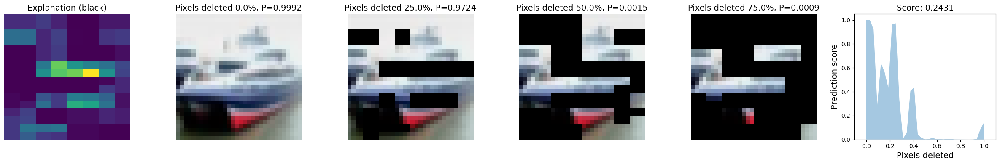

black:  90%|████████▉ | 897/1000 [00:21<00:01, 52.46it/s]

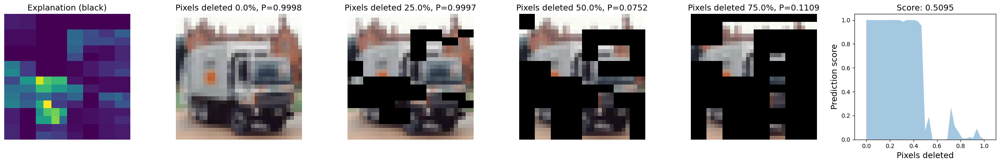

black: 100%|██████████| 1000/1000 [00:23<00:00, 41.86it/s]


np.float64(0.2521217644469285)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

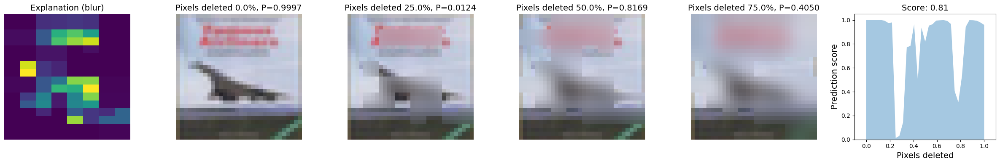

blur:  10%|▉         | 97/1000 [00:02<00:15, 57.61it/s]

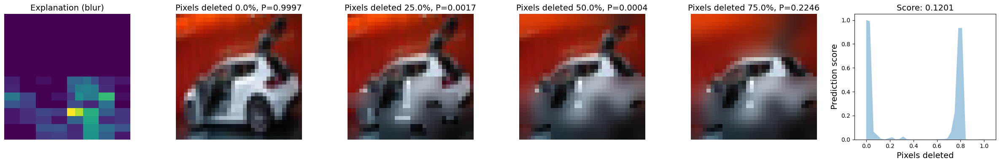

blur:  20%|█▉        | 198/1000 [00:04<00:16, 47.84it/s]

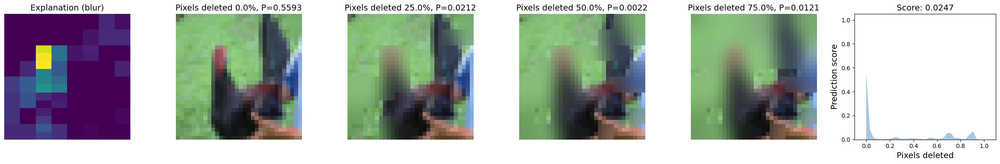

blur:  30%|██▉       | 298/1000 [00:07<00:15, 45.18it/s]

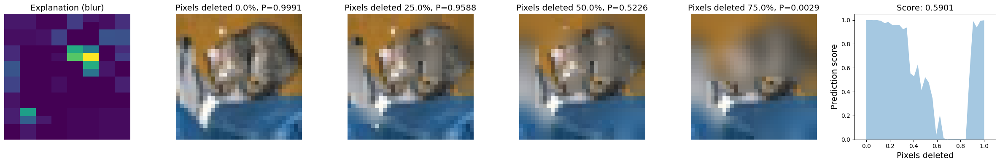

blur:  40%|███▉      | 398/1000 [00:09<00:10, 56.80it/s]

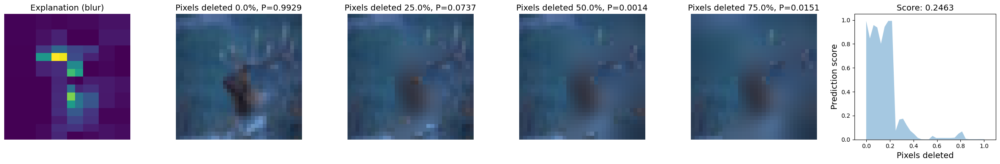

blur:  50%|█████     | 500/1000 [00:11<00:08, 57.33it/s]

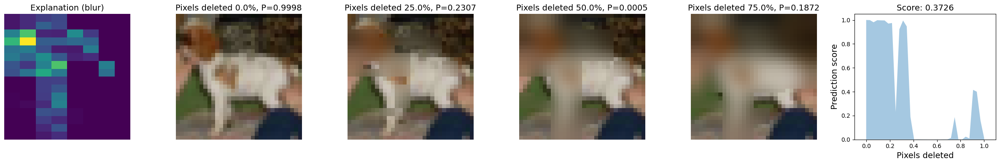

blur:  60%|█████▉    | 596/1000 [00:13<00:07, 57.17it/s]

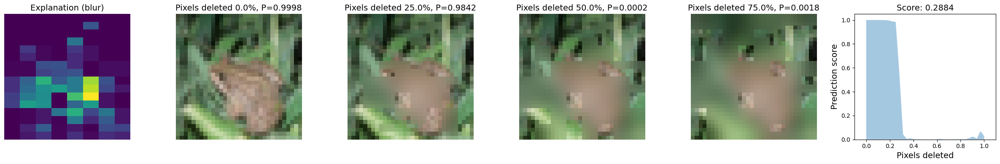

blur:  70%|███████   | 700/1000 [00:16<00:05, 56.42it/s]

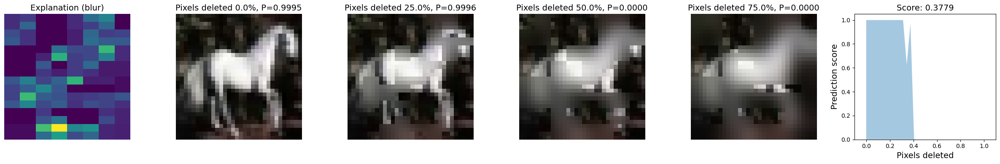

blur:  80%|███████▉  | 796/1000 [00:18<00:04, 49.23it/s]

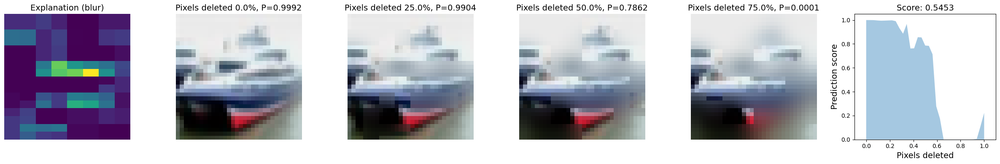

blur:  90%|█████████ | 900/1000 [00:21<00:02, 49.60it/s]

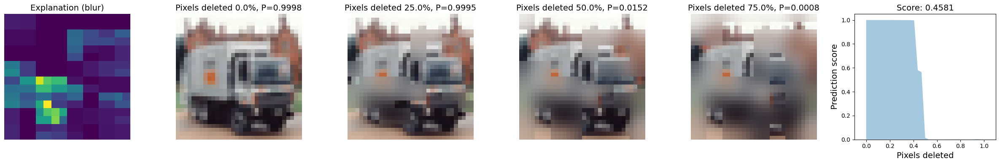

blur: 100%|██████████| 1000/1000 [00:23<00:00, 42.20it/s]


np.float64(0.39952156075556694)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

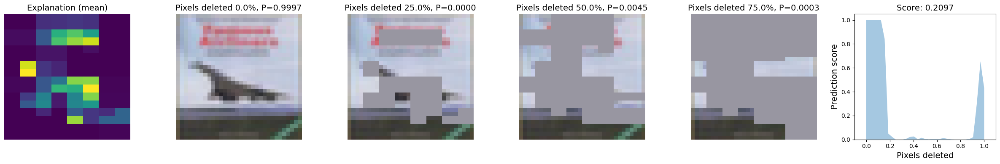

mean:  10%|█         | 100/1000 [00:02<00:15, 57.05it/s]

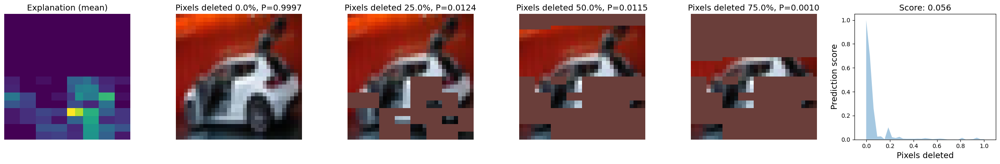

mean:  20%|█▉        | 199/1000 [00:04<00:13, 57.26it/s]

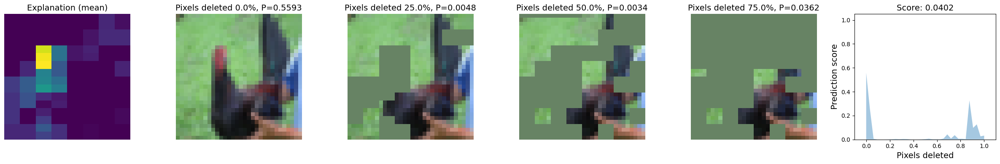

mean:  30%|██▉       | 296/1000 [00:06<00:12, 56.06it/s]

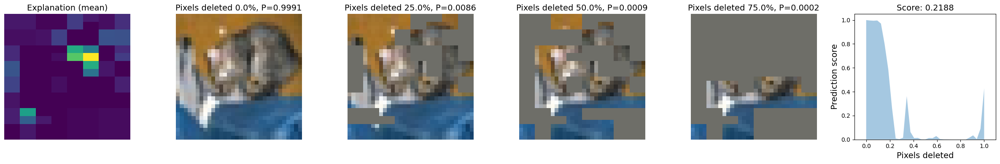

mean:  40%|███▉      | 398/1000 [00:08<00:10, 57.48it/s]

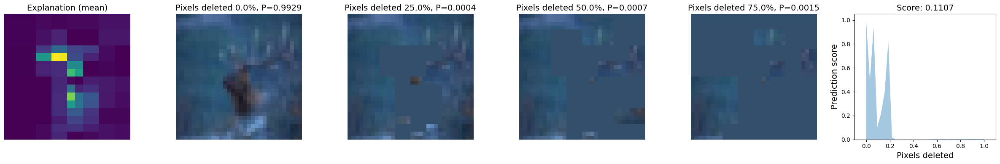

mean:  50%|████▉     | 498/1000 [00:11<00:10, 48.58it/s]

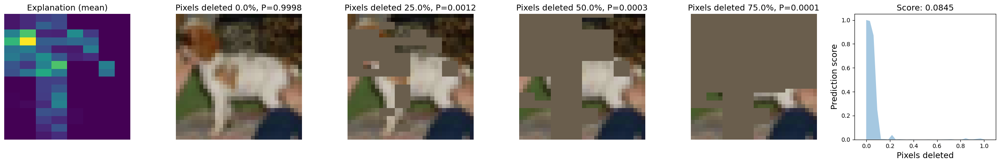

mean:  60%|█████▉    | 597/1000 [00:13<00:07, 54.38it/s]

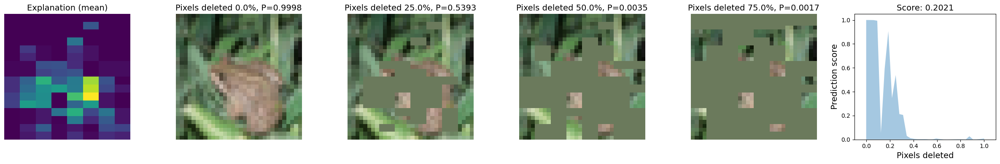

mean:  70%|██████▉   | 699/1000 [00:16<00:05, 54.00it/s]

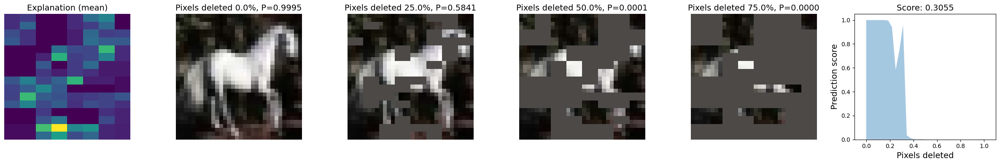

mean:  80%|███████▉  | 795/1000 [00:18<00:03, 52.09it/s]

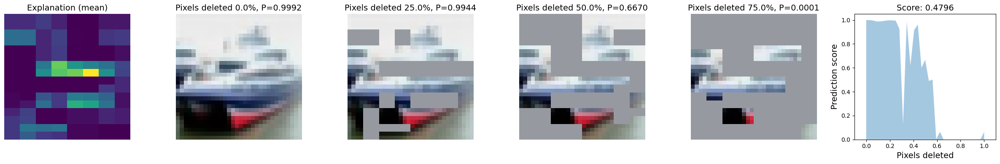

mean:  90%|████████▉ | 896/1000 [00:21<00:01, 53.88it/s]

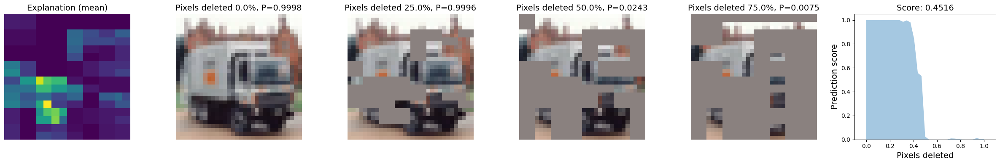

mean: 100%|██████████| 1000/1000 [00:23<00:00, 42.59it/s]


np.float64(0.22548633524867517)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

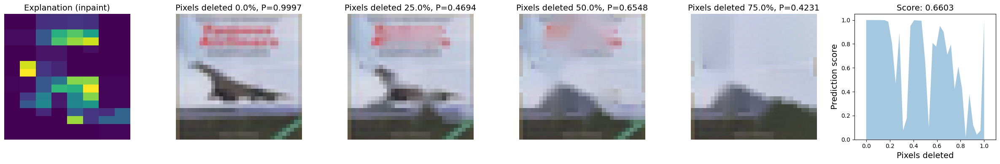

inpaint:  10%|▉         | 99/1000 [00:04<00:30, 29.95it/s]

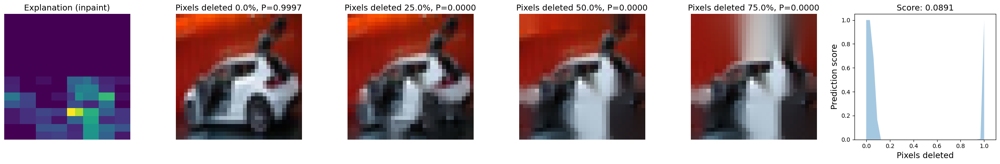

inpaint:  20%|█▉        | 199/1000 [00:08<00:26, 30.21it/s]

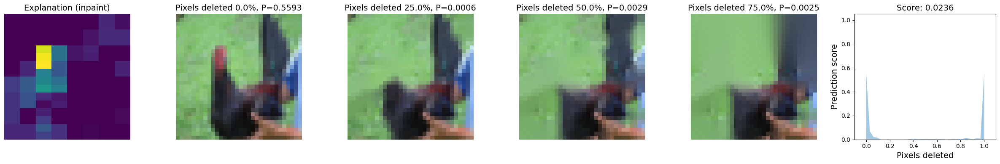

inpaint:  30%|██▉       | 299/1000 [00:11<00:22, 31.07it/s]

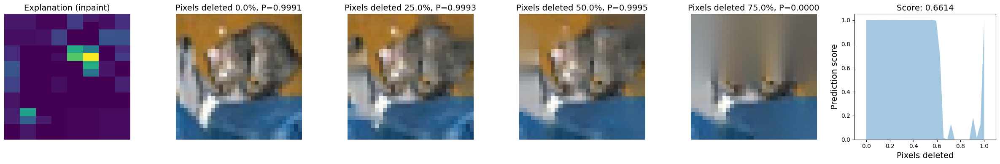

inpaint:  40%|███▉      | 398/1000 [00:16<00:27, 21.94it/s]

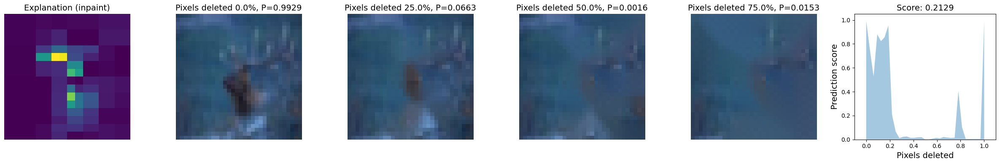

inpaint:  50%|████▉     | 497/1000 [00:20<00:17, 29.01it/s]

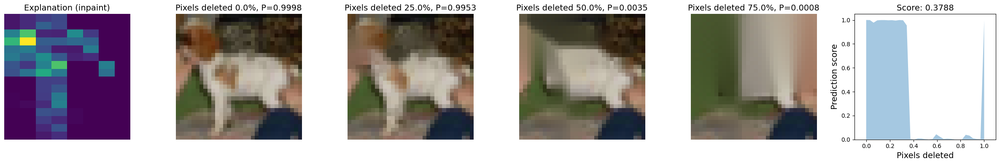

inpaint:  60%|██████    | 600/1000 [00:24<00:13, 30.06it/s]

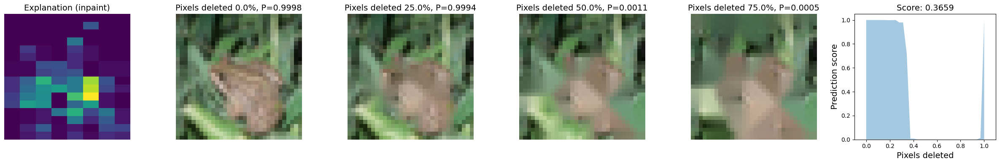

inpaint:  70%|███████   | 700/1000 [00:28<00:12, 23.46it/s]

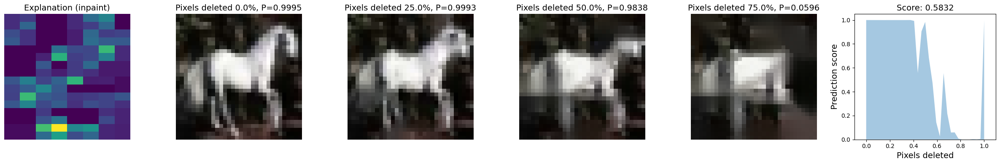

inpaint:  80%|███████▉  | 799/1000 [00:33<00:06, 28.99it/s]

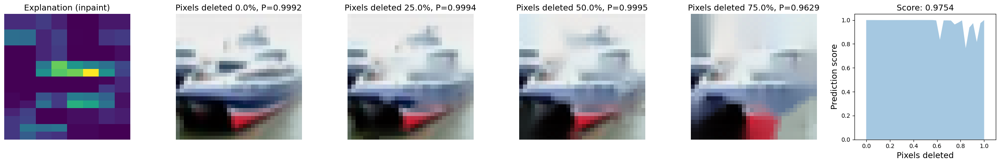

inpaint:  90%|████████▉ | 899/1000 [00:36<00:03, 29.77it/s]

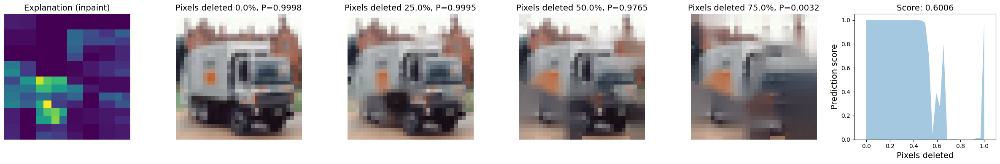

inpaint: 100%|██████████| 1000/1000 [00:40<00:00, 24.48it/s]


np.float64(0.4569945691786178)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

52it [00:00, 519.67it/s]

0
100


348it [00:00, 512.98it/s]

200
300
400


589it [00:01, 809.93it/s]

500
600
700


1000it [00:01, 664.18it/s]

800
900


np.float64(0.7969560002477369)

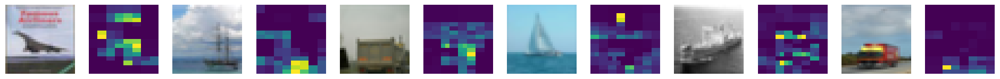

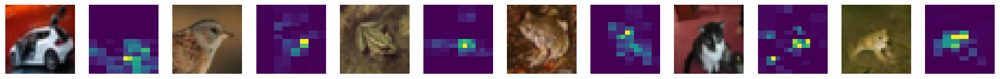

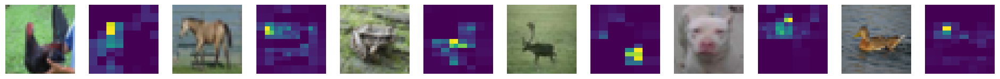

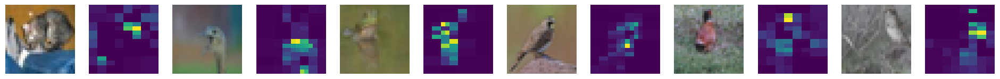

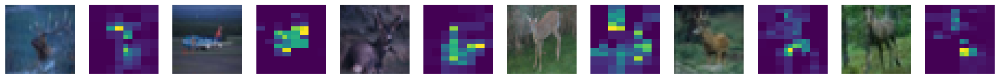

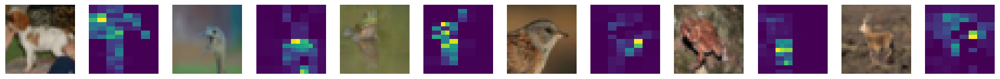

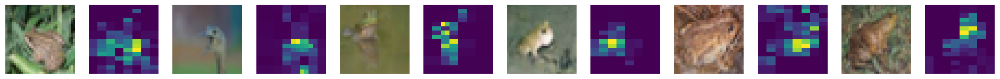

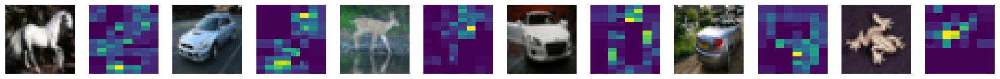

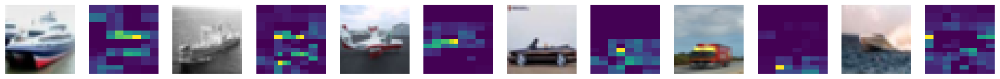

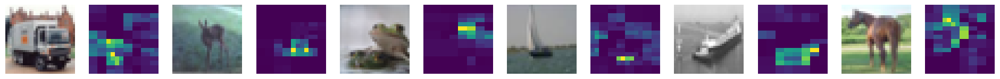

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:14<00:00, 70.08it/s]

Mean time for 1000 explanations: 0.012821871042251586
Mean time for 1000 explanations: 0.012454886674880981


<Figure size 640x480 with 0 Axes>

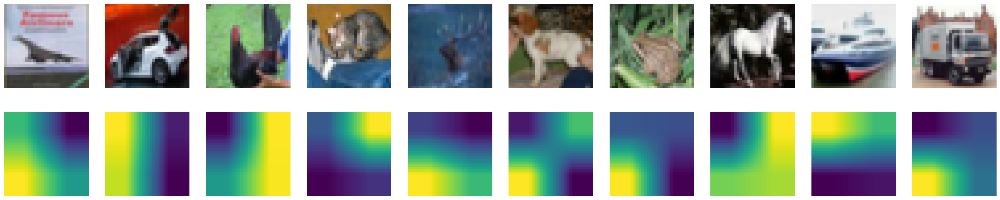

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

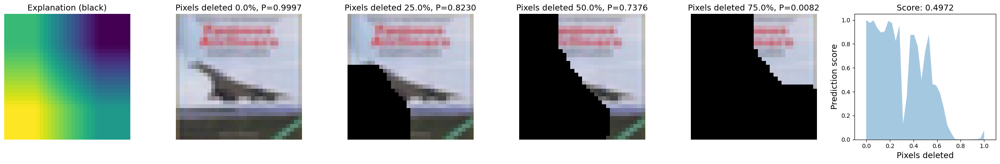

black:  10%|█         | 100/1000 [00:02<00:18, 48.64it/s]

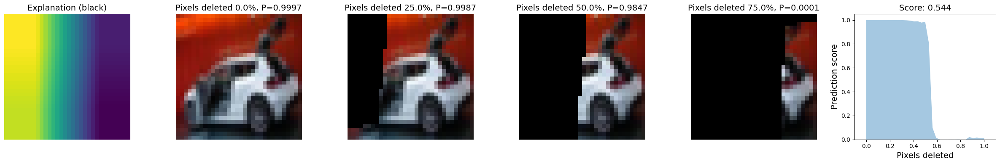

black:  20%|█▉        | 199/1000 [00:05<00:14, 54.41it/s]

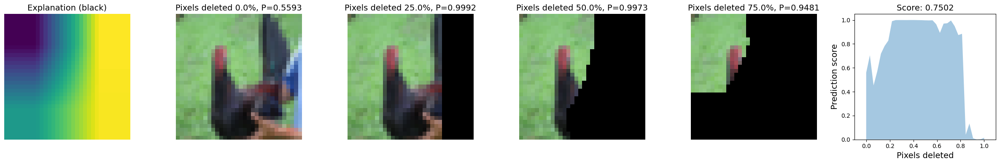

black:  30%|██▉       | 295/1000 [00:07<00:12, 56.19it/s]

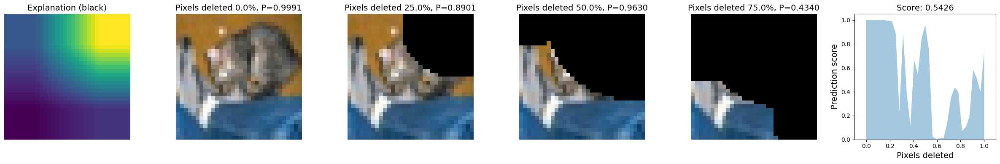

black:  40%|███▉      | 397/1000 [00:10<00:10, 55.36it/s]

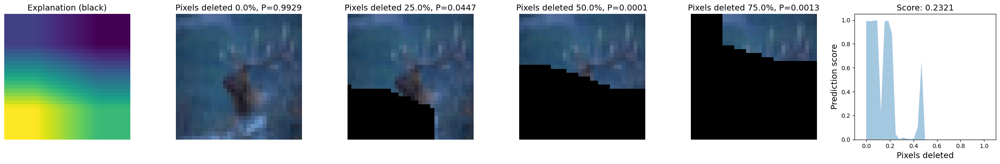

black:  50%|████▉     | 499/1000 [00:12<00:09, 52.56it/s]

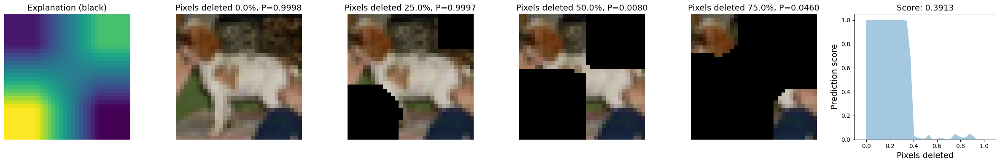

black:  60%|█████▉    | 596/1000 [00:14<00:08, 46.30it/s]

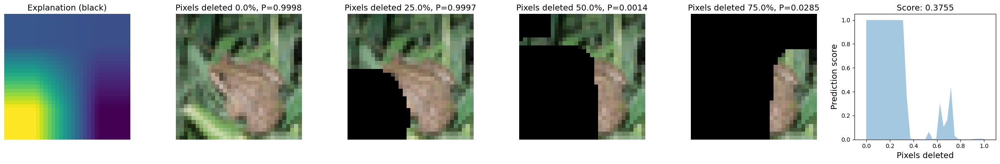

black:  70%|███████   | 700/1000 [00:17<00:07, 42.40it/s]

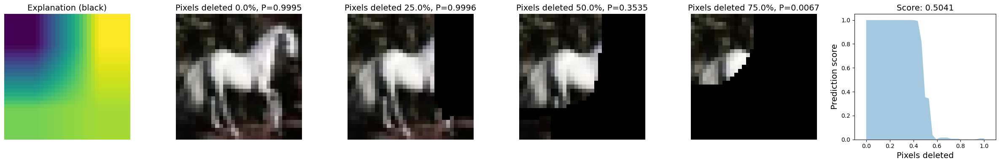

black:  80%|███████▉  | 798/1000 [00:20<00:03, 53.44it/s]

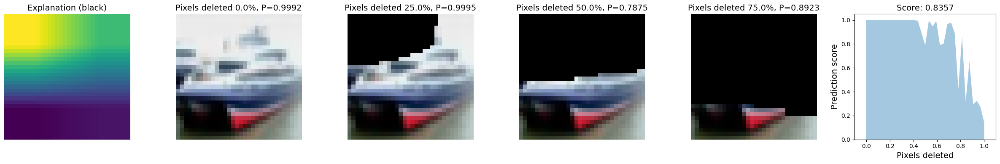

black:  90%|█████████ | 900/1000 [00:22<00:01, 55.40it/s]

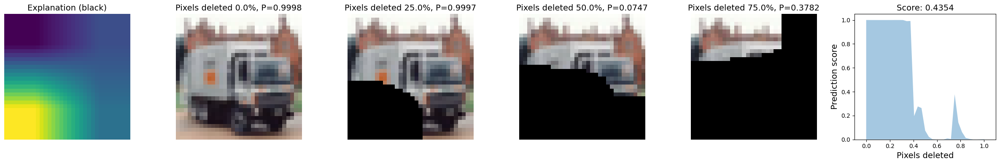

black: 100%|██████████| 1000/1000 [00:24<00:00, 40.56it/s]


np.float64(0.5050131889719816)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

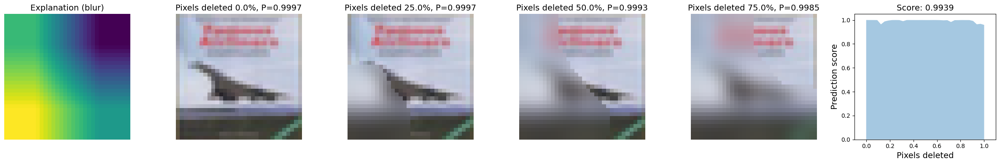

blur:  10%|▉         | 97/1000 [00:02<00:15, 57.35it/s]

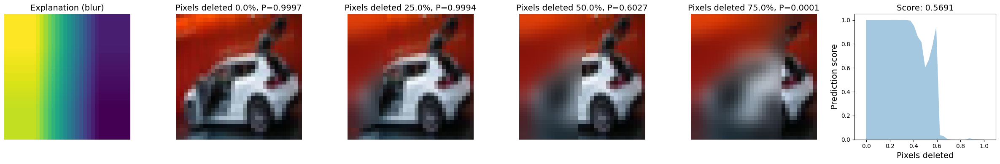

blur:  20%|█▉        | 196/1000 [00:04<00:16, 47.87it/s]

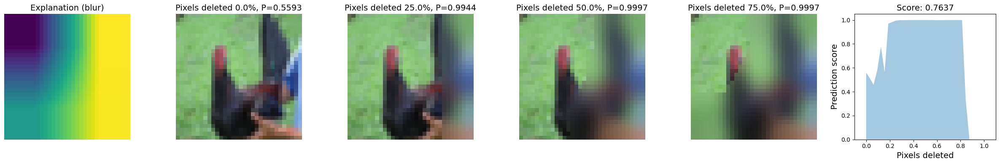

blur:  30%|██▉       | 296/1000 [00:07<00:15, 45.08it/s]

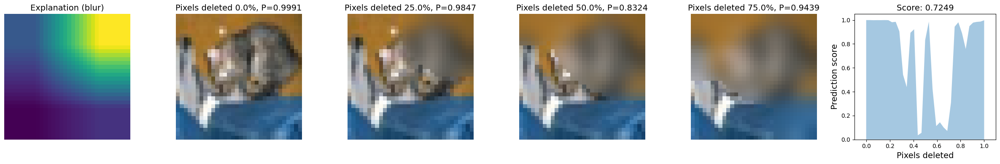

blur:  40%|███▉      | 398/1000 [00:09<00:10, 55.57it/s]

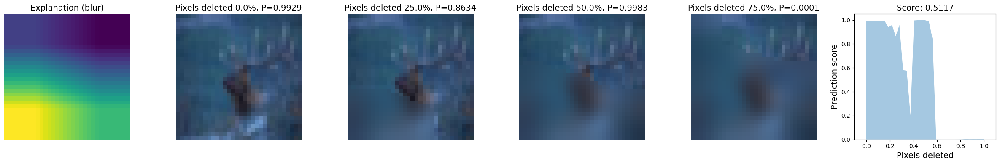

blur:  50%|█████     | 500/1000 [00:11<00:08, 55.72it/s]

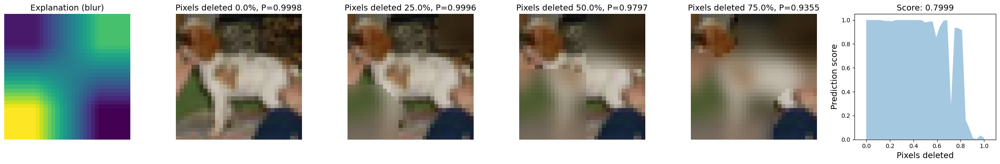

blur:  60%|█████▉    | 596/1000 [00:13<00:07, 54.89it/s]

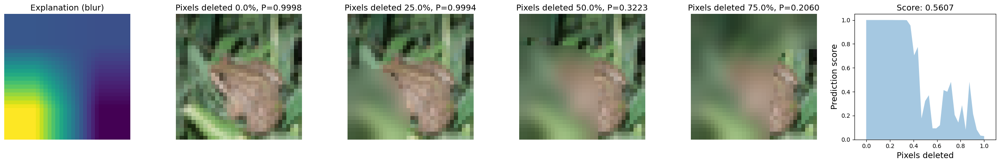

blur:  70%|██████▉   | 698/1000 [00:16<00:05, 56.90it/s]

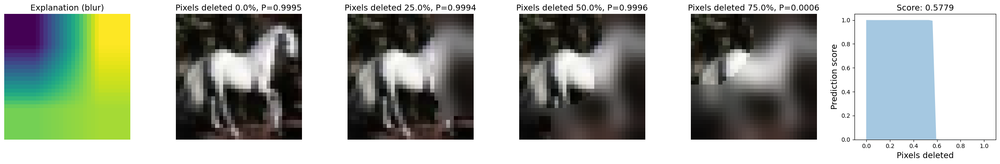

blur:  80%|███████▉  | 797/1000 [00:18<00:04, 47.25it/s]

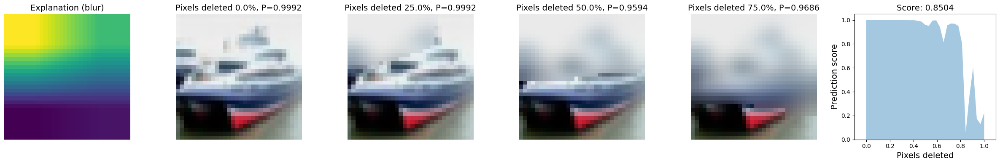

blur:  90%|████████▉ | 896/1000 [00:21<00:02, 42.23it/s]

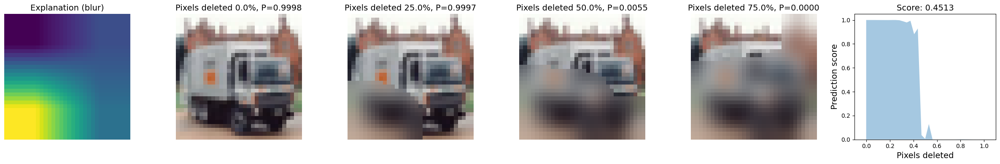

blur: 100%|██████████| 1000/1000 [00:24<00:00, 40.98it/s]


np.float64(0.62084079889074)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

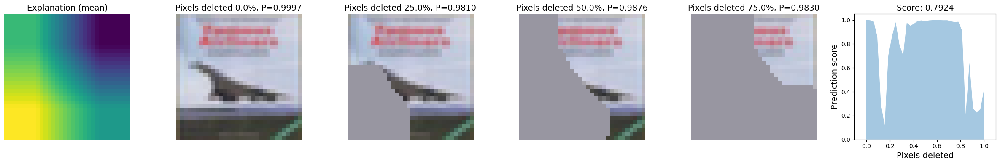

mean:  10%|▉         | 97/1000 [00:02<00:16, 53.14it/s]

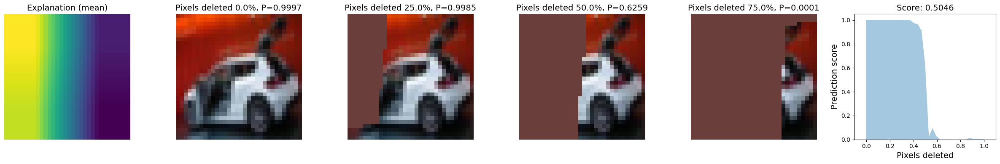

mean:  20%|█▉        | 199/1000 [00:04<00:15, 52.37it/s]

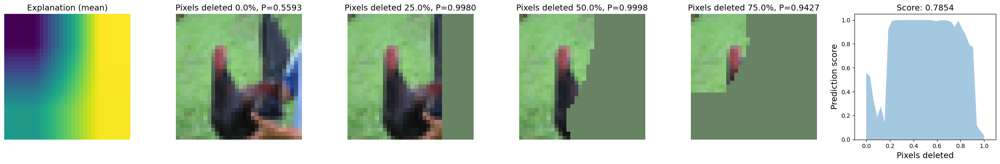

mean:  30%|███       | 300/1000 [00:06<00:12, 55.42it/s]

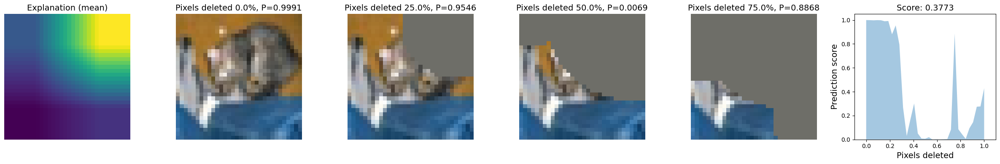

mean:  40%|███▉      | 396/1000 [00:09<00:13, 44.37it/s]

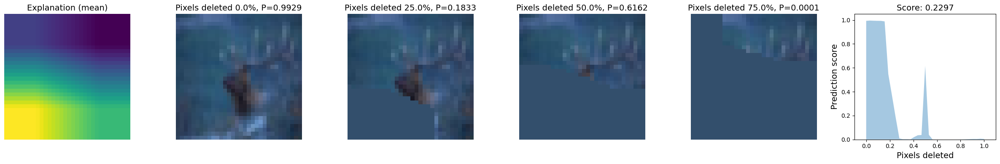

mean:  50%|████▉     | 498/1000 [00:12<00:10, 46.08it/s]

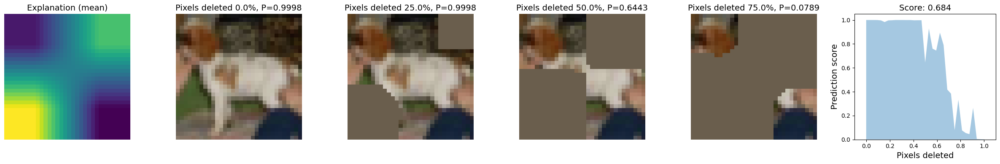

mean:  60%|█████▉    | 598/1000 [00:14<00:07, 53.85it/s]

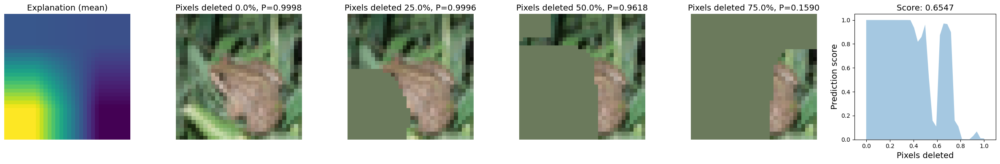

mean:  70%|███████   | 700/1000 [00:16<00:05, 54.75it/s]

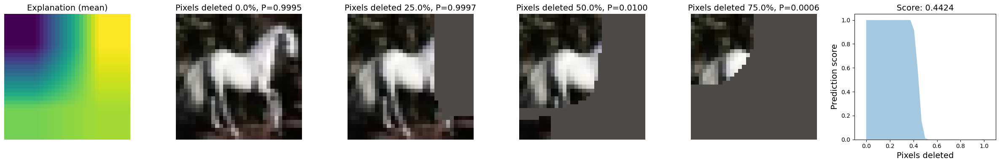

mean:  80%|███████▉  | 796/1000 [00:18<00:03, 55.31it/s]

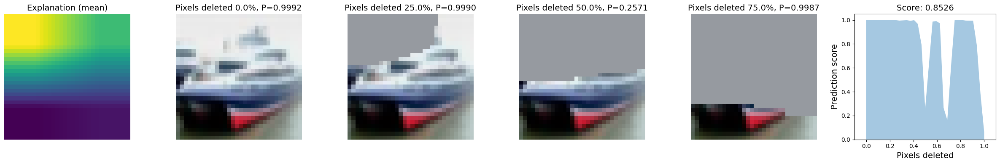

mean:  90%|████████▉ | 898/1000 [00:21<00:01, 54.52it/s]

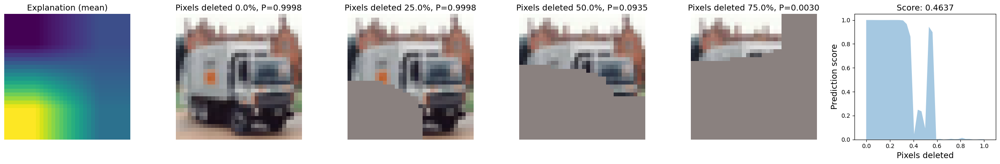

mean: 100%|██████████| 1000/1000 [00:23<00:00, 42.48it/s]


np.float64(0.5506349175395853)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

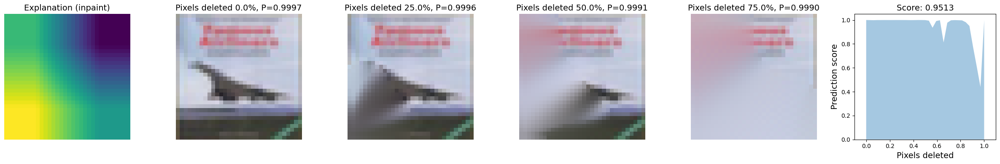

inpaint:  10%|█         | 100/1000 [00:04<00:29, 30.91it/s]

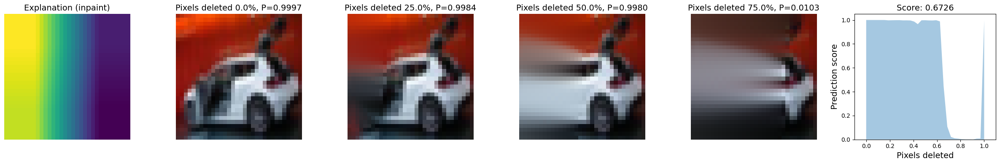

inpaint:  20%|█▉        | 199/1000 [00:07<00:23, 34.00it/s]

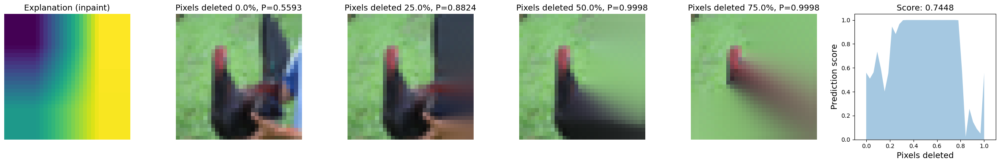

inpaint:  30%|██▉       | 298/1000 [00:10<00:21, 32.72it/s]

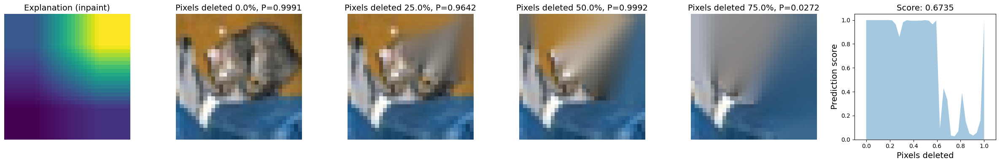

inpaint:  40%|███▉      | 399/1000 [00:15<00:24, 24.76it/s]

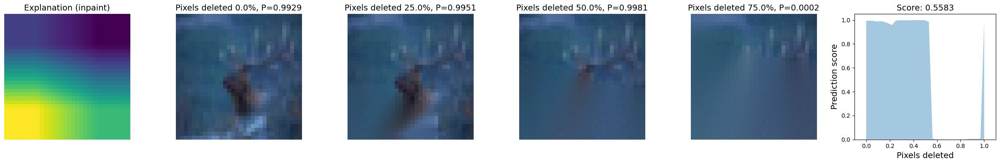

inpaint:  50%|████▉     | 498/1000 [00:19<00:15, 33.42it/s]

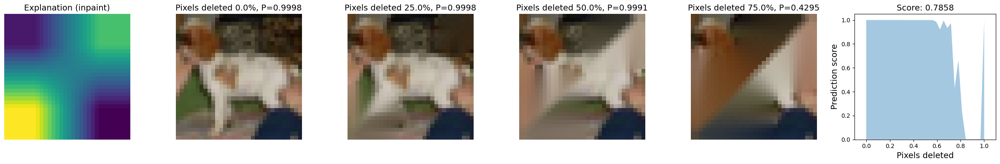

inpaint:  60%|█████▉    | 597/1000 [00:22<00:12, 32.86it/s]

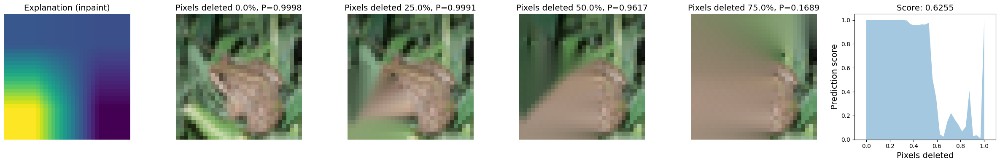

inpaint:  70%|███████   | 700/1000 [00:26<00:09, 32.63it/s]

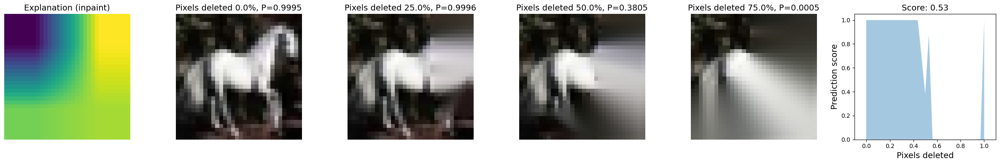

inpaint:  80%|███████▉  | 798/1000 [00:31<00:07, 26.59it/s]

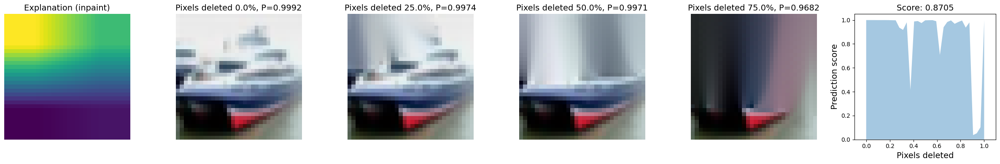

inpaint:  90%|████████▉ | 899/1000 [00:34<00:03, 32.02it/s]

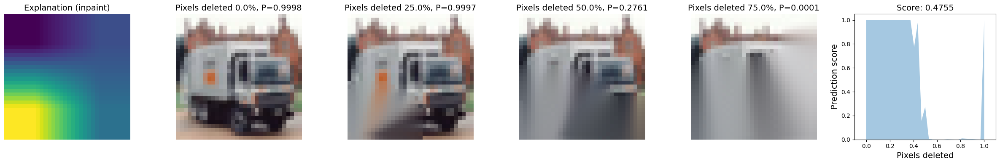

inpaint: 100%|██████████| 1000/1000 [00:38<00:00, 25.88it/s]


np.float64(0.6329495740134524)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

1it [00:00,  7.85it/s]

0
100


201it [00:00, 575.45it/s]

200
300


401it [00:00, 688.41it/s]

400
500


601it [00:01, 325.62it/s]

600
700


1000it [00:01, 503.45it/s]

800
900


np.float32(1.5680073)

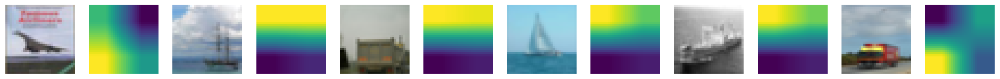

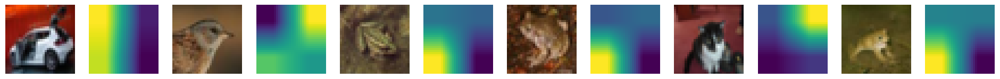

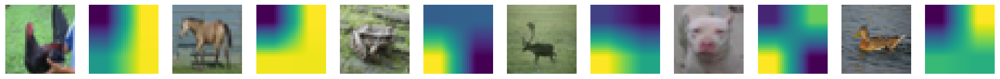

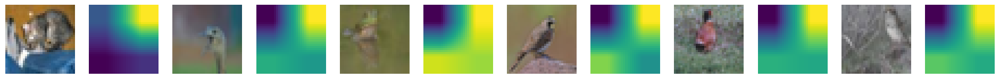

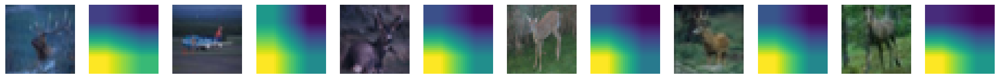

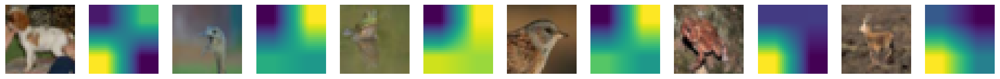

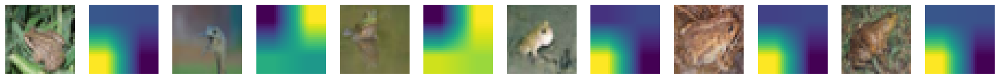

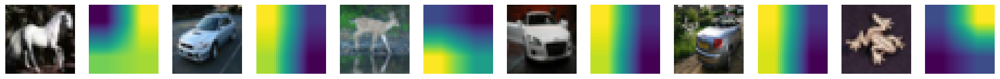

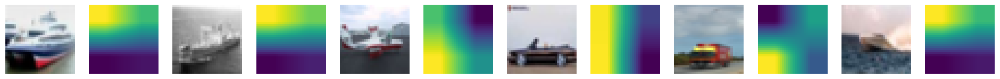

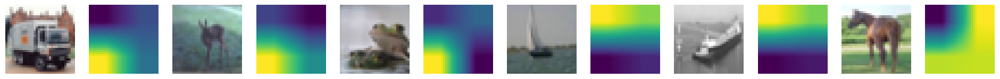

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, [model.features[-2]], preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:14<00:00, 68.88it/s]

Mean time for 1000 explanations: 0.012593701601028443
Mean time for 1000 explanations: 0.012674710750579833


<Figure size 640x480 with 0 Axes>

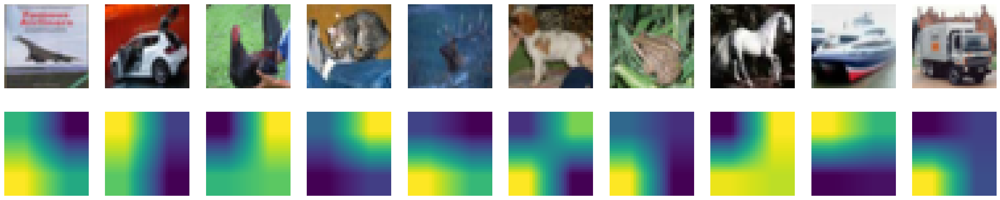

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

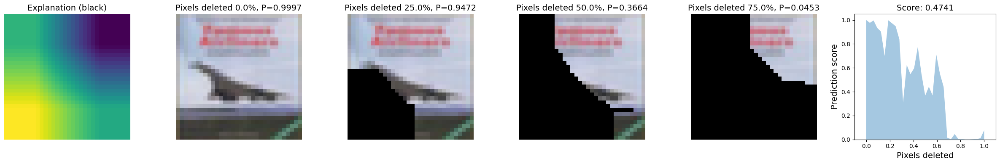

black:  10%|█         | 100/1000 [00:02<00:19, 45.67it/s]

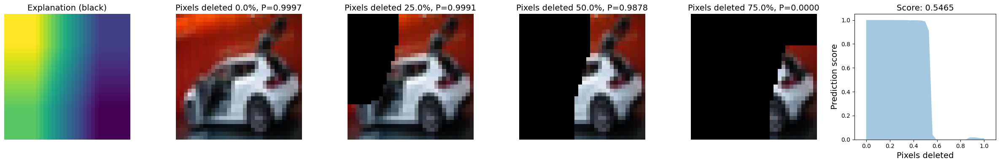

black:  20%|██        | 200/1000 [00:05<00:20, 39.88it/s]

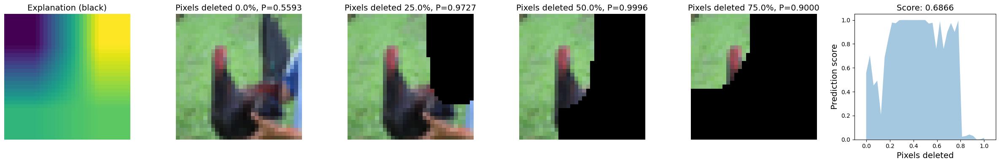

black:  30%|██▉       | 297/1000 [00:07<00:13, 52.77it/s]

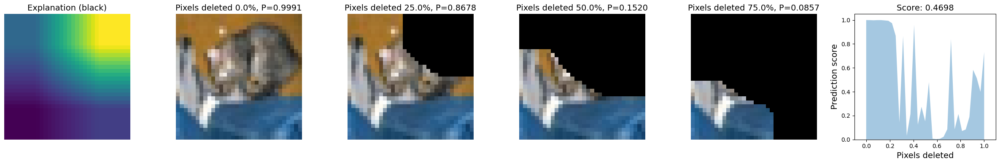

black:  40%|███▉      | 396/1000 [00:09<00:11, 53.50it/s]

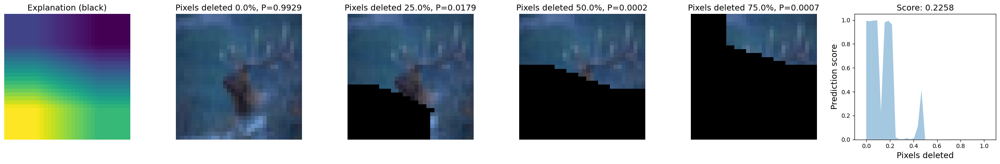

black:  50%|████▉     | 497/1000 [00:12<00:09, 54.09it/s]

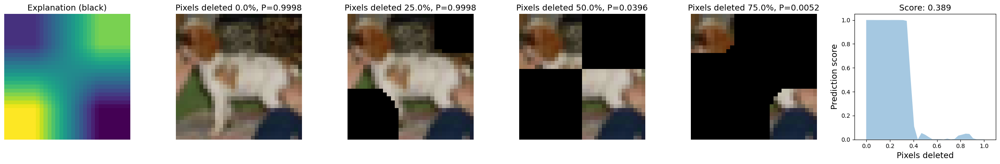

black:  60%|█████▉    | 599/1000 [00:14<00:07, 53.08it/s]

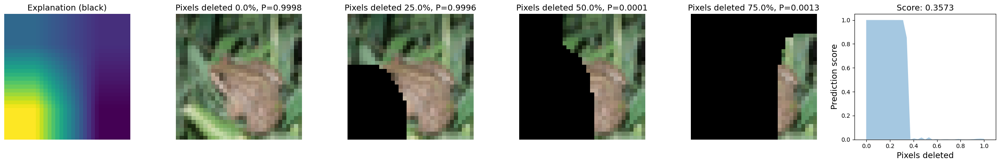

black:  70%|██████▉   | 699/1000 [00:17<00:07, 41.51it/s]

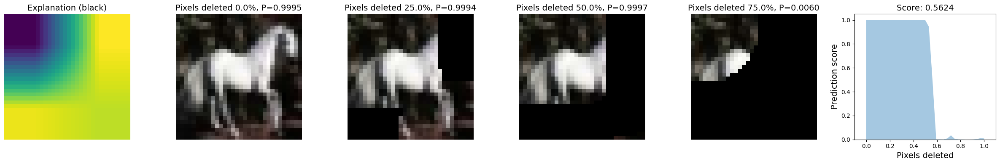

black:  80%|███████▉  | 798/1000 [00:20<00:04, 44.94it/s]

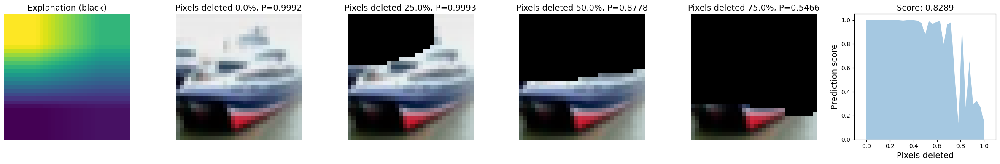

black:  90%|████████▉ | 897/1000 [00:22<00:01, 54.27it/s]

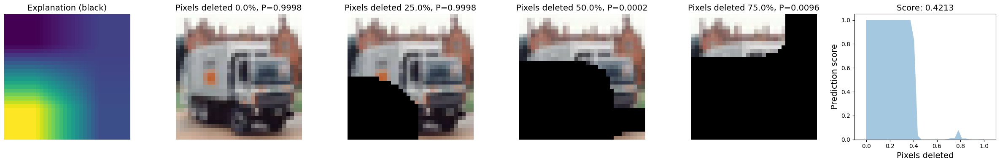

black: 100%|██████████| 1000/1000 [00:24<00:00, 40.78it/s]


np.float64(0.5057984044175219)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

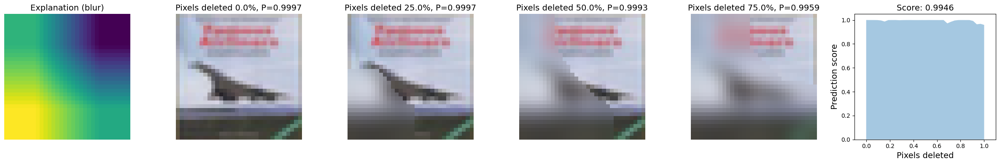

blur:  10%|▉         | 97/1000 [00:02<00:15, 57.40it/s]

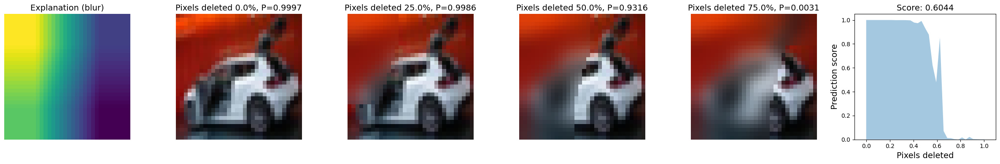

blur:  20%|█▉        | 199/1000 [00:04<00:14, 56.73it/s]

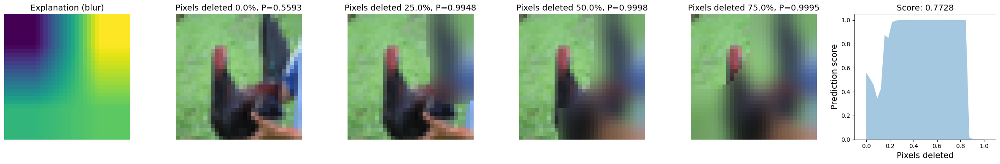

blur:  30%|██▉       | 299/1000 [00:06<00:15, 43.92it/s]

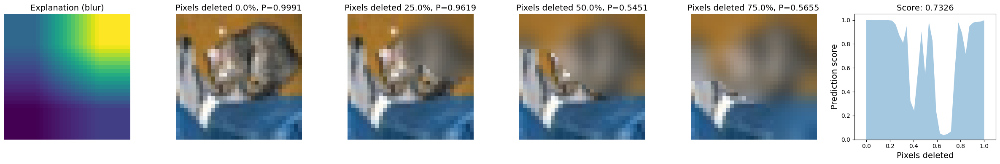

blur:  40%|███▉      | 397/1000 [00:10<00:12, 48.61it/s]

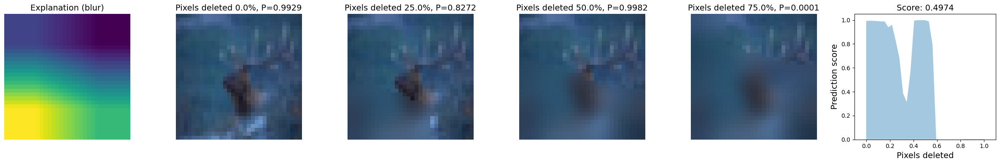

blur:  50%|████▉     | 497/1000 [00:12<00:09, 53.10it/s]

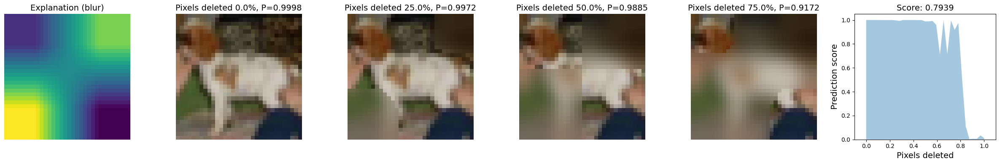

blur:  60%|█████▉    | 597/1000 [00:14<00:07, 51.96it/s]

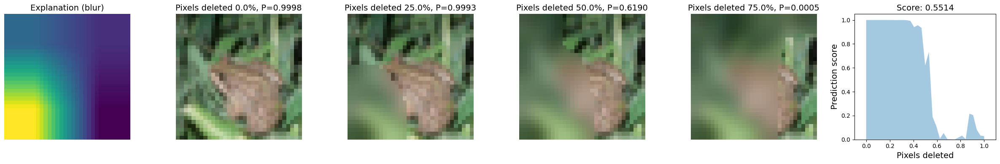

blur:  70%|██████▉   | 698/1000 [00:17<00:05, 52.18it/s]

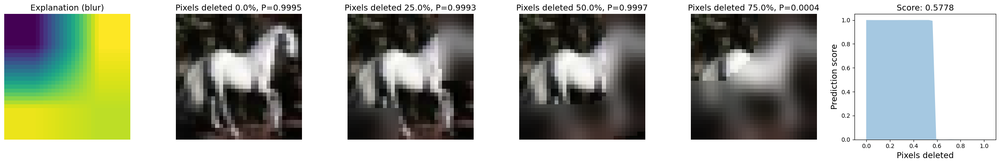

blur:  80%|███████▉  | 799/1000 [00:19<00:04, 45.35it/s]

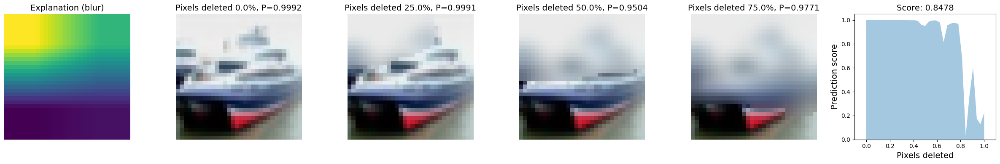

blur:  90%|████████▉ | 899/1000 [00:22<00:02, 44.17it/s]

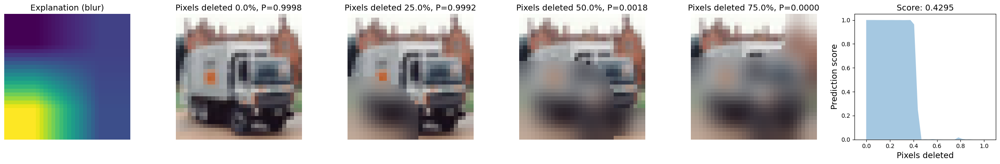

blur: 100%|██████████| 1000/1000 [00:25<00:00, 39.64it/s]


np.float64(0.6223070121599208)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

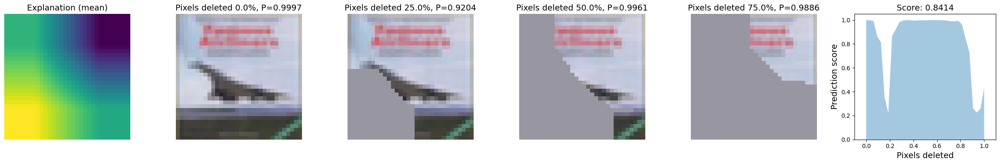

mean:  10%|▉         | 96/1000 [00:02<00:15, 56.60it/s]

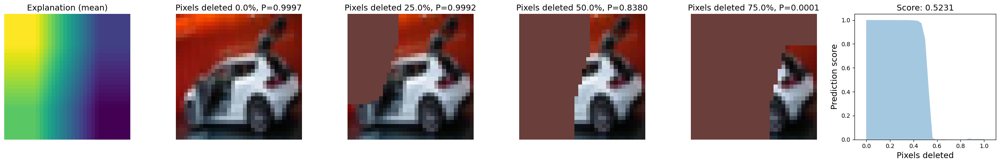

mean:  20%|█▉        | 198/1000 [00:04<00:14, 55.62it/s]

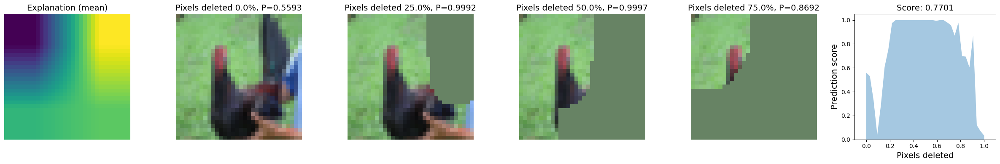

mean:  30%|███       | 300/1000 [00:06<00:12, 57.70it/s]

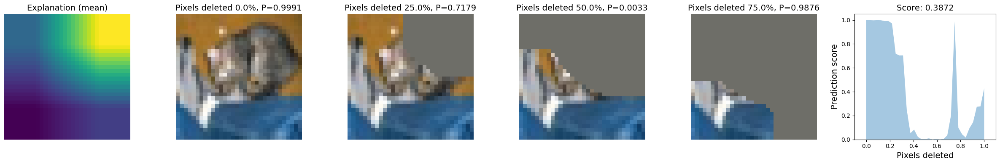

mean:  40%|███▉      | 396/1000 [00:08<00:12, 47.06it/s]

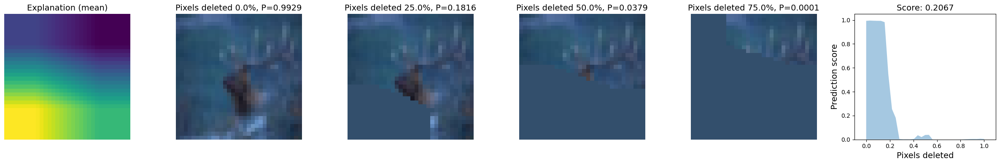

mean:  50%|████▉     | 496/1000 [00:11<00:10, 47.77it/s]

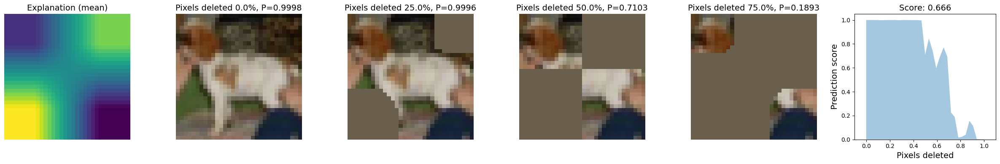

mean:  60%|██████    | 600/1000 [00:14<00:07, 54.55it/s]

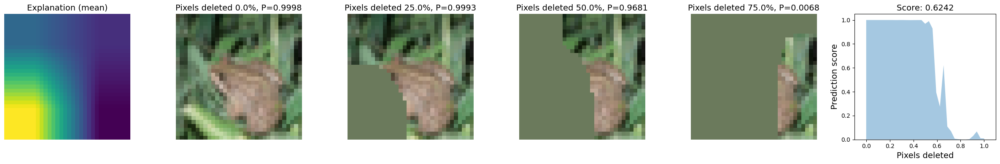

mean:  70%|██████▉   | 696/1000 [00:16<00:05, 52.32it/s]

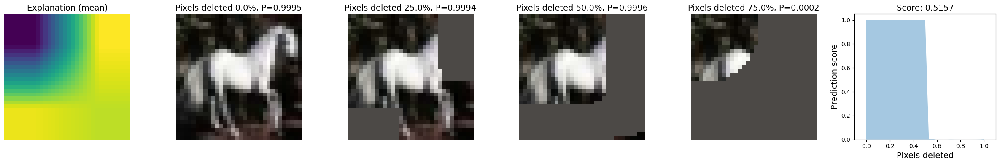

mean:  80%|███████▉  | 797/1000 [00:18<00:03, 52.68it/s]

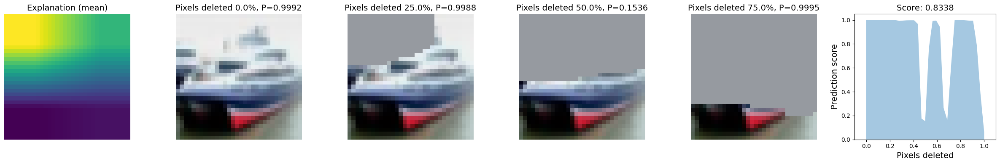

mean:  90%|████████▉ | 898/1000 [00:21<00:01, 53.30it/s]

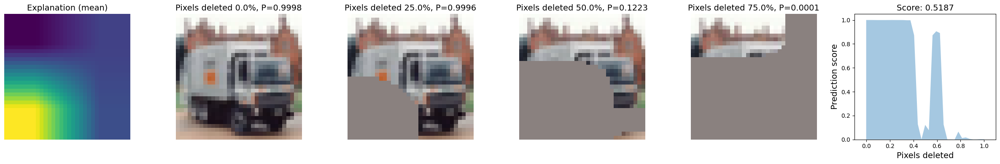

mean: 100%|██████████| 1000/1000 [00:23<00:00, 42.56it/s]


np.float64(0.5497928466081057)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

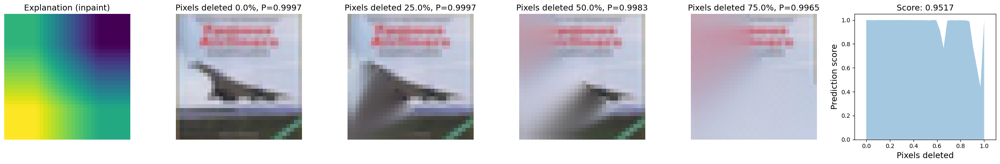

inpaint:  10%|▉         | 98/1000 [00:04<00:27, 32.39it/s]

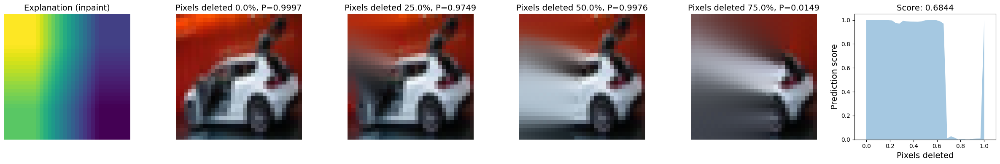

inpaint:  20%|█▉        | 197/1000 [00:08<00:25, 31.73it/s]

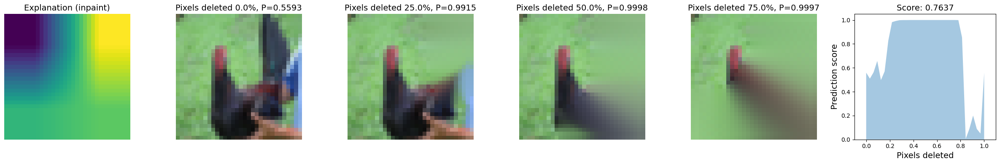

inpaint:  30%|██▉       | 297/1000 [00:11<00:22, 31.28it/s]

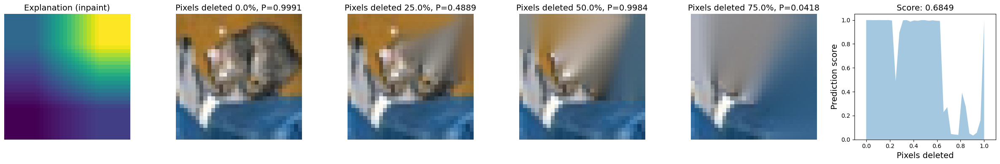

inpaint:  40%|███▉      | 398/1000 [00:16<00:25, 23.36it/s]

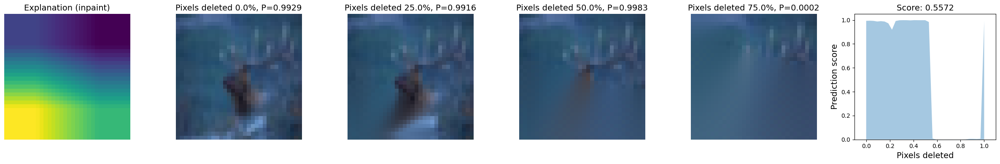

inpaint:  50%|█████     | 500/1000 [00:20<00:16, 30.74it/s]

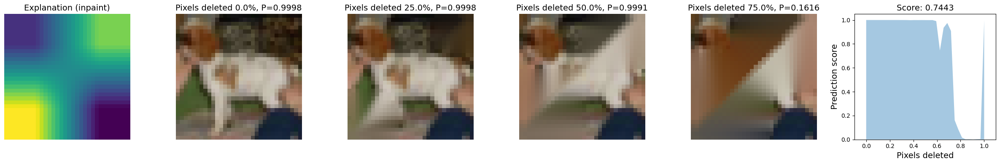

inpaint:  60%|█████▉    | 599/1000 [00:24<00:12, 30.87it/s]

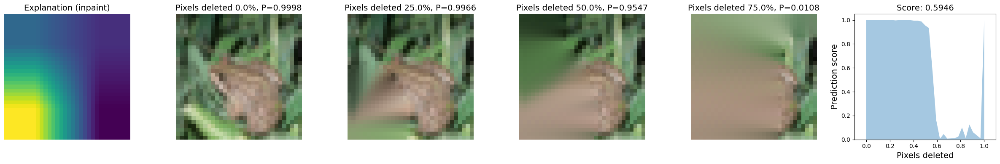

inpaint:  70%|██████▉   | 697/1000 [00:27<00:10, 30.25it/s]

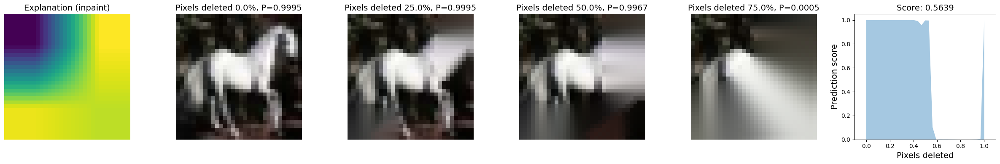

inpaint:  80%|███████▉  | 798/1000 [00:33<00:08, 25.20it/s]

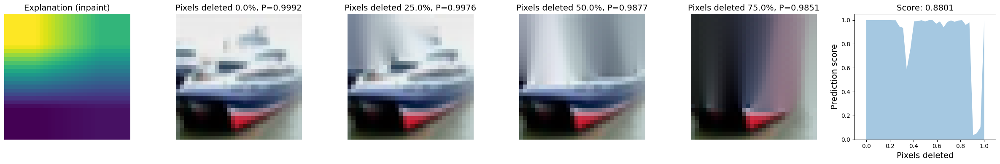

inpaint:  90%|████████▉ | 899/1000 [00:36<00:03, 31.32it/s]

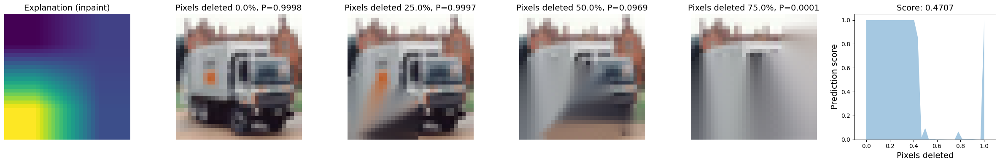

inpaint: 100%|██████████| 1000/1000 [00:40<00:00, 24.49it/s]


np.float64(0.6330470083932487)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 559.53it/s]

0
100
200


490it [00:00, 1088.11it/s]

300
400
500


778it [00:00, 1111.87it/s]

600
700
800


1000it [00:00, 1035.75it/s]

900


np.float32(1.561492)

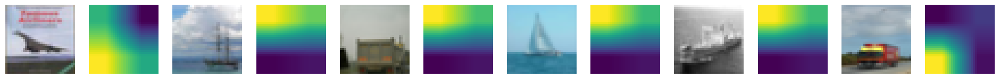

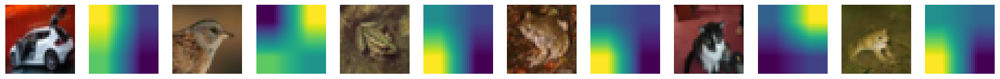

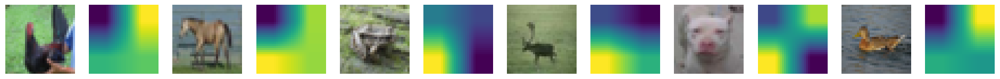

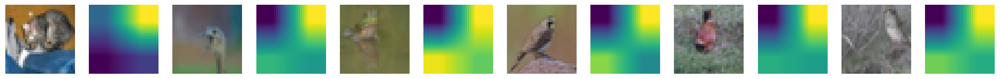

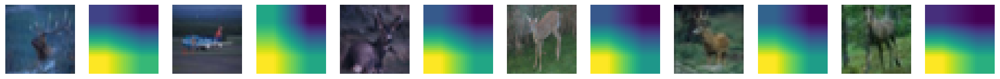

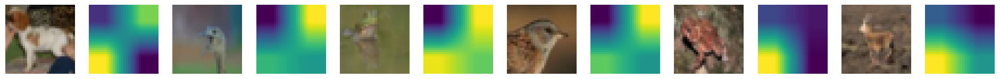

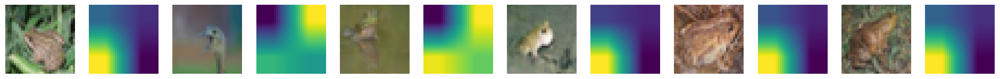

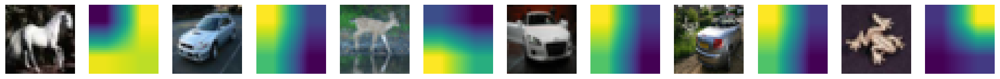

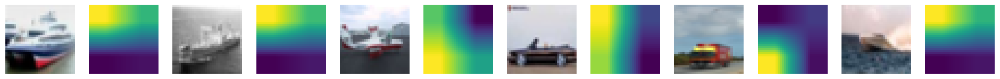

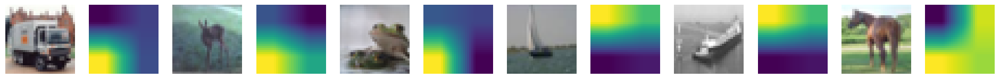

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:32<00:00, 31.17it/s]

Mean time for 1000 explanations: 0.024057022094726564
Mean time for 1000 explanations: 0.02388463735580444


<Figure size 640x480 with 0 Axes>

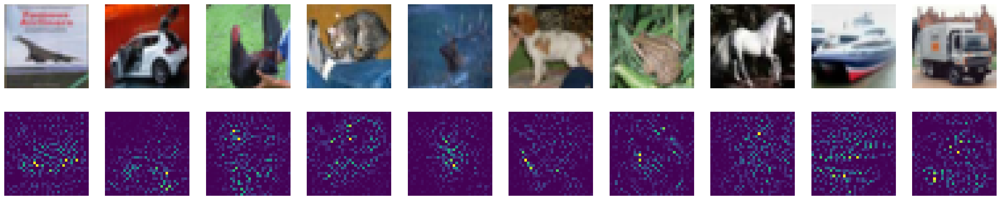

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

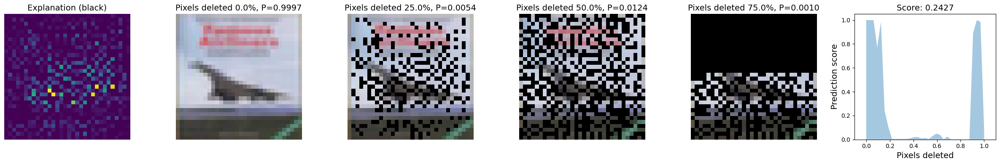

black:  10%|▉         | 97/1000 [00:02<00:15, 57.03it/s]

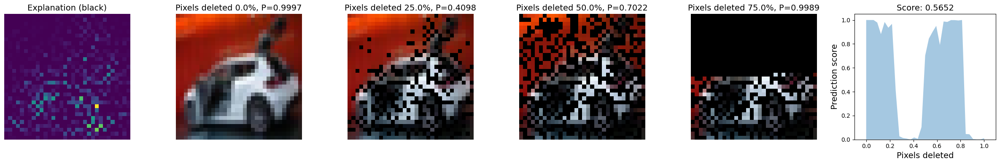

black:  20%|█▉        | 199/1000 [00:04<00:14, 56.21it/s]

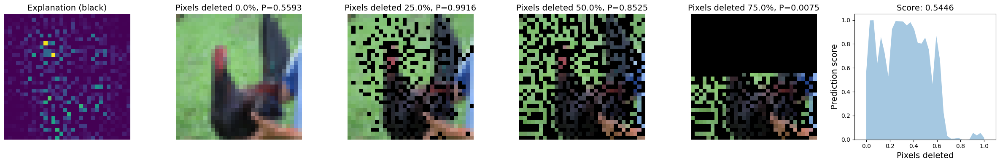

black:  30%|██▉       | 295/1000 [00:06<00:12, 56.39it/s]

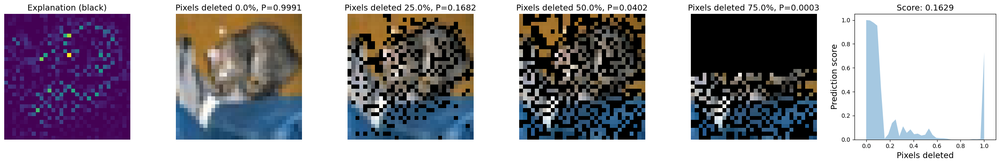

black:  40%|███▉      | 396/1000 [00:08<00:10, 55.57it/s]

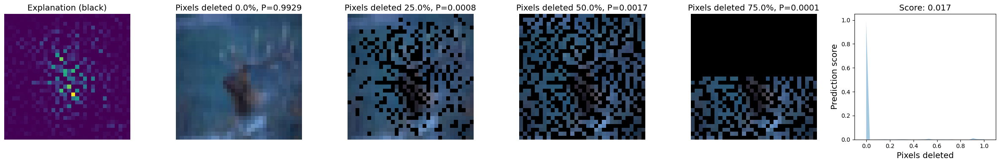

black:  50%|████▉     | 497/1000 [00:11<00:11, 43.12it/s]

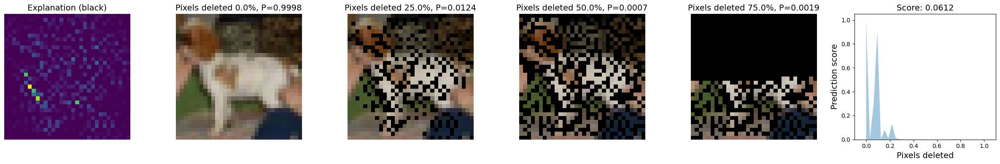

black:  60%|█████▉    | 596/1000 [00:14<00:08, 47.63it/s]

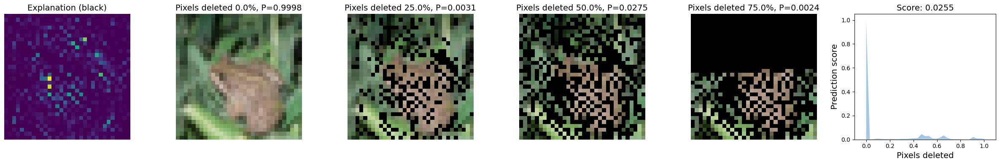

black:  70%|██████▉   | 695/1000 [00:17<00:05, 52.57it/s]

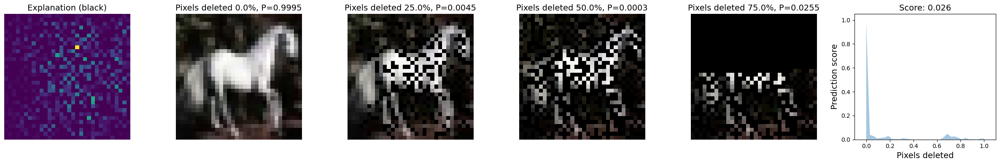

black:  80%|███████▉  | 796/1000 [00:19<00:03, 52.50it/s]

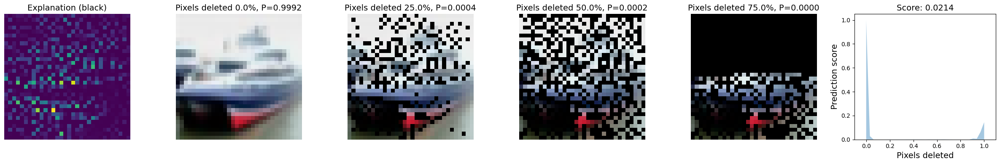

black:  90%|████████▉ | 898/1000 [00:21<00:02, 49.99it/s]

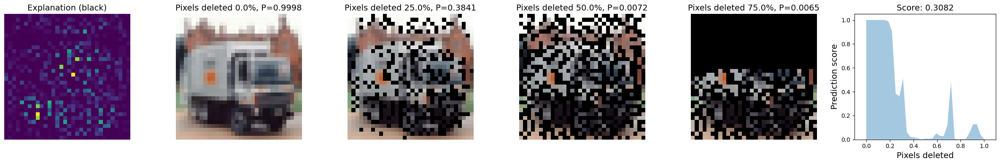

black: 100%|██████████| 1000/1000 [00:24<00:00, 40.84it/s]


np.float64(0.1923068774819922)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

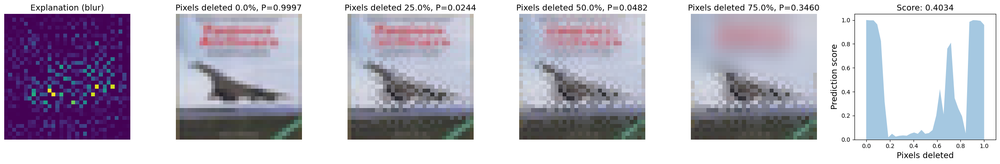

blur:  10%|▉         | 96/1000 [00:03<00:22, 40.60it/s]

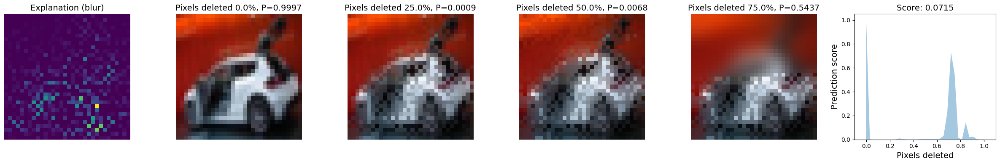

blur:  20%|█▉        | 199/1000 [00:05<00:14, 54.78it/s]

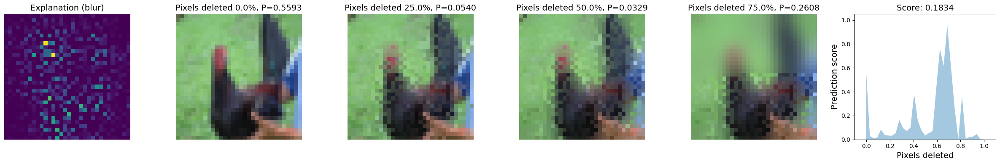

blur:  30%|██▉       | 295/1000 [00:07<00:12, 54.50it/s]

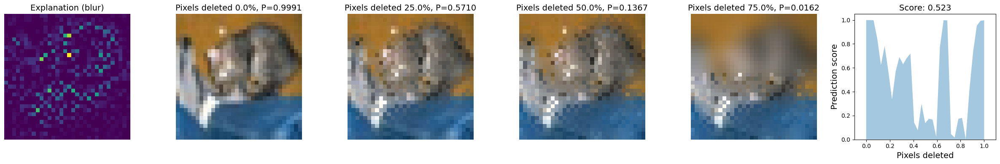

blur:  40%|███▉      | 396/1000 [00:10<00:11, 53.35it/s]

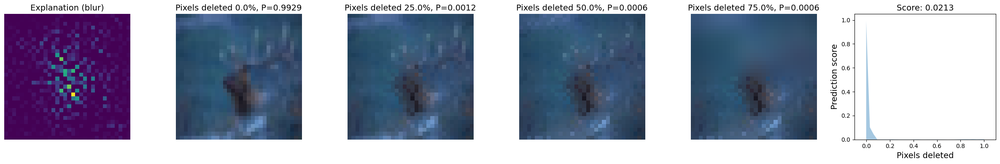

blur:  50%|████▉     | 496/1000 [00:12<00:09, 53.37it/s]

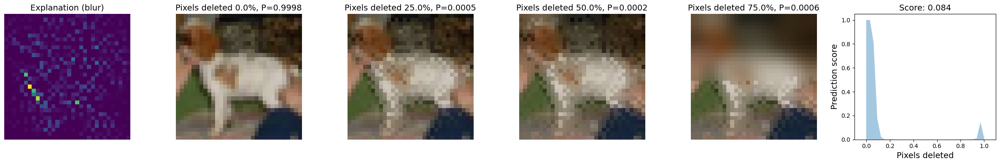

blur:  60%|█████▉    | 598/1000 [00:15<00:09, 44.33it/s]

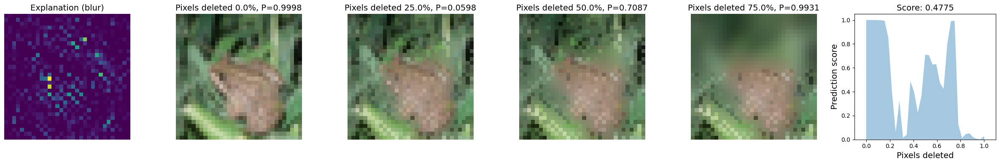

blur:  70%|██████▉   | 698/1000 [00:18<00:07, 39.53it/s]

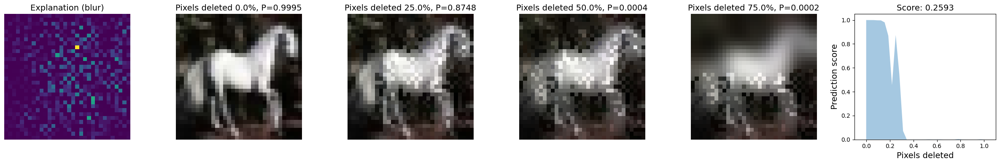

blur:  80%|███████▉  | 798/1000 [00:20<00:03, 54.10it/s]

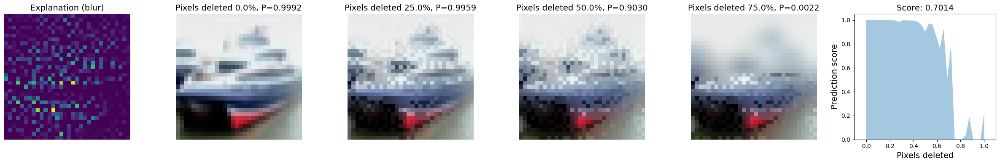

blur:  90%|█████████ | 900/1000 [00:22<00:01, 52.93it/s]

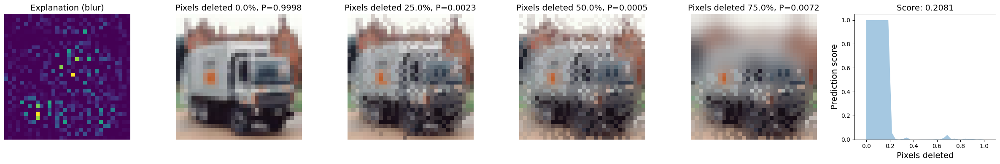

blur: 100%|██████████| 1000/1000 [00:25<00:00, 39.95it/s]


np.float64(0.3646657826810722)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

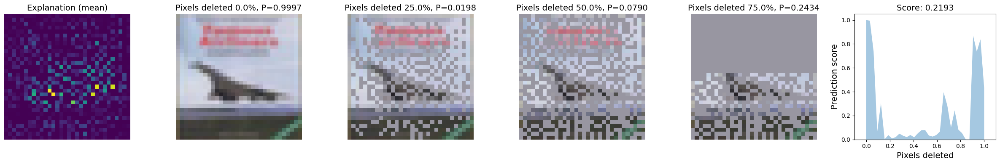

mean:  10%|█         | 100/1000 [00:02<00:15, 58.51it/s]

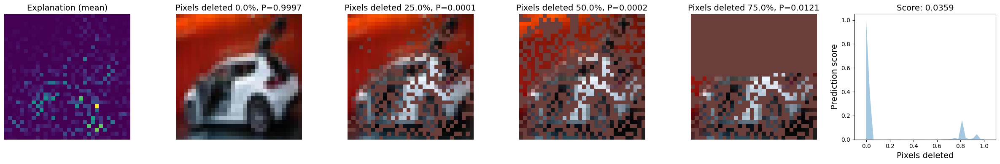

mean:  20%|██        | 200/1000 [00:04<00:16, 48.42it/s]

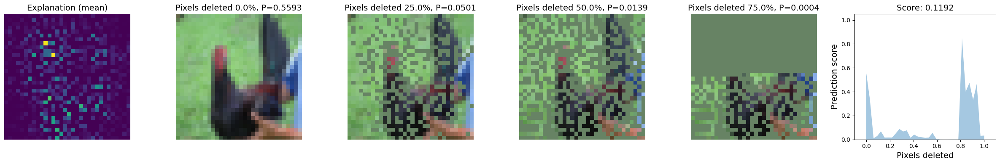

mean:  30%|███       | 300/1000 [00:07<00:16, 41.61it/s]

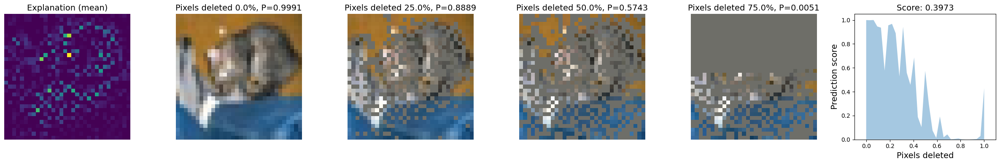

mean:  40%|████      | 400/1000 [00:09<00:10, 57.32it/s]

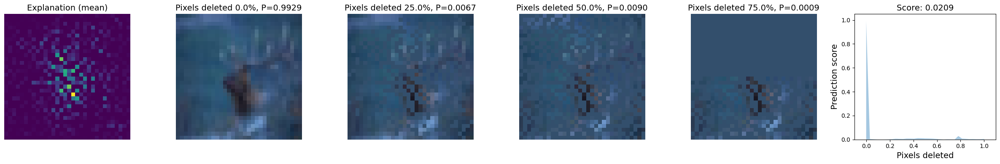

mean:  50%|████▉     | 496/1000 [00:12<00:08, 56.93it/s]

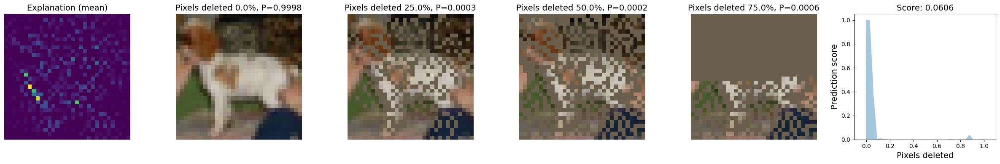

mean:  60%|█████▉    | 598/1000 [00:14<00:07, 57.11it/s]

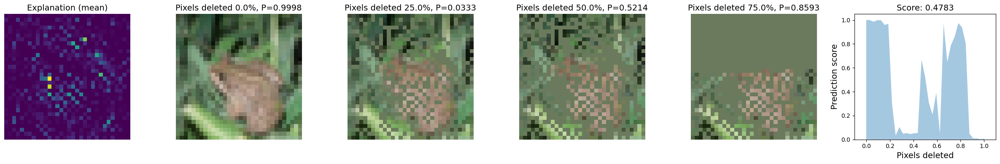

mean:  70%|███████   | 700/1000 [00:16<00:05, 54.99it/s]

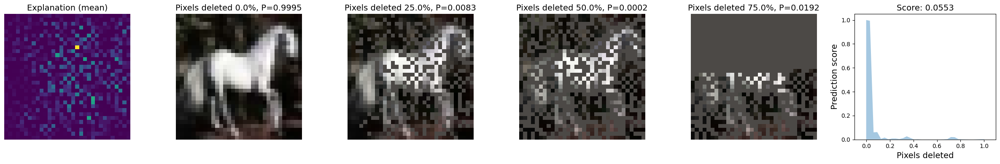

mean:  80%|███████▉  | 798/1000 [00:19<00:04, 42.10it/s]

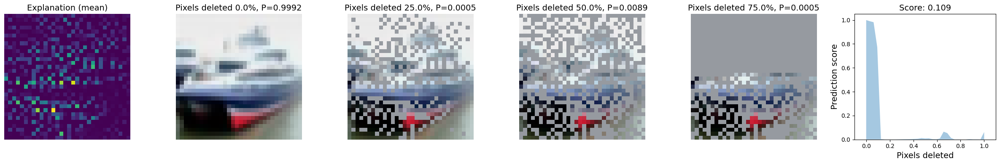

mean:  90%|█████████ | 900/1000 [00:22<00:02, 46.57it/s]

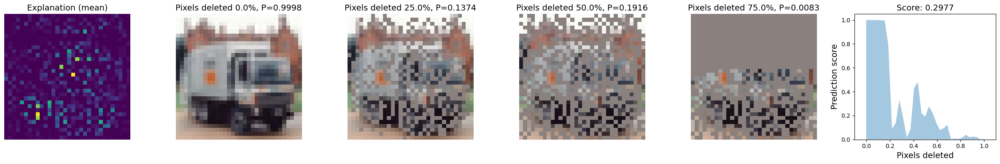

mean: 100%|██████████| 1000/1000 [00:24<00:00, 40.42it/s]


np.float64(0.252077367766852)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

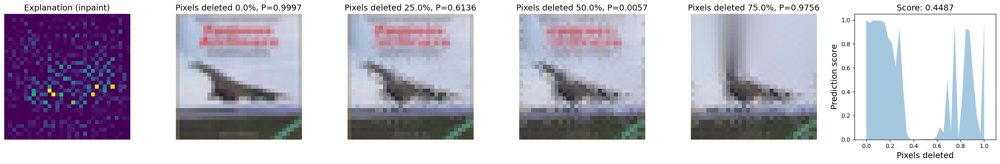

inpaint:  10%|█         | 100/1000 [00:04<00:33, 26.65it/s]

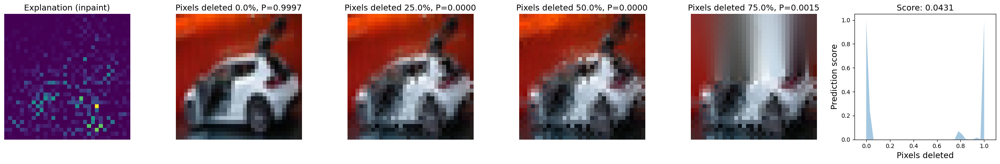

inpaint:  20%|█▉        | 199/1000 [00:08<00:42, 18.75it/s]

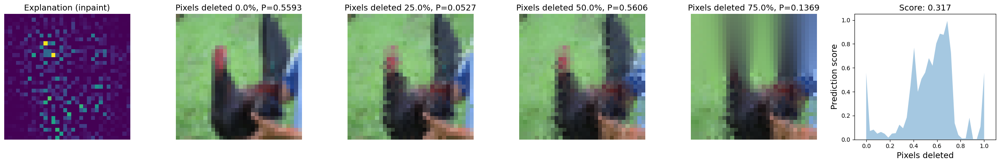

inpaint:  30%|██▉       | 298/1000 [00:13<00:26, 26.64it/s]

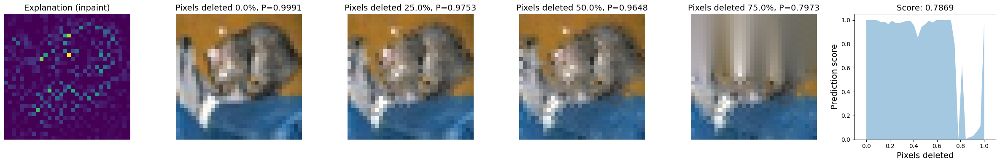

inpaint:  40%|████      | 400/1000 [00:18<00:23, 25.76it/s]

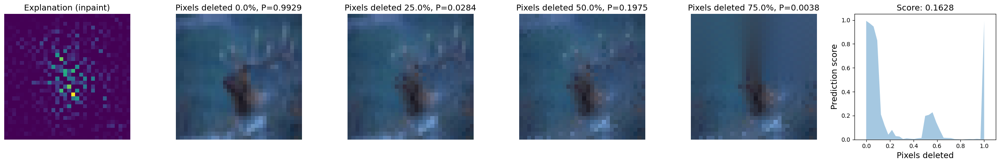

inpaint:  50%|█████     | 500/1000 [00:22<00:26, 18.83it/s]

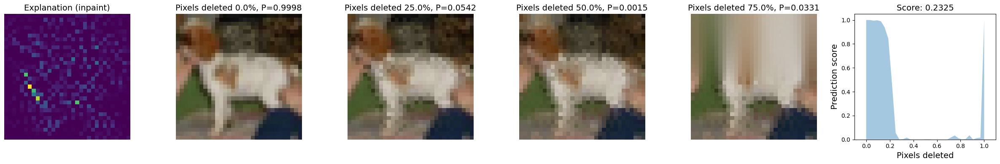

inpaint:  60%|█████▉    | 599/1000 [00:28<00:15, 25.89it/s]

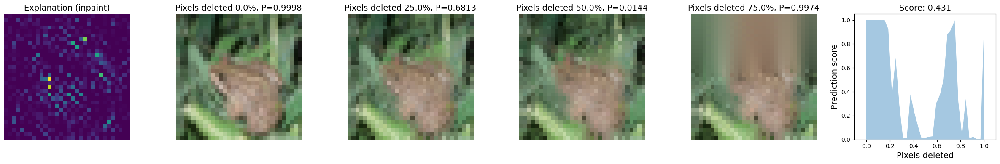

inpaint:  70%|██████▉   | 698/1000 [00:32<00:12, 25.16it/s]

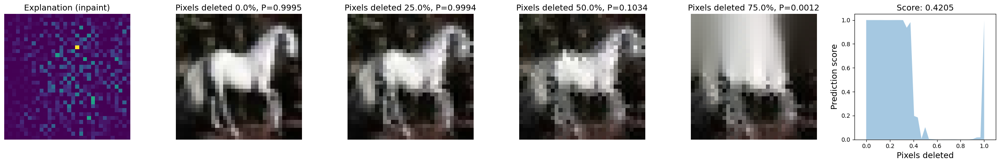

inpaint:  80%|███████▉  | 799/1000 [00:37<00:10, 18.96it/s]

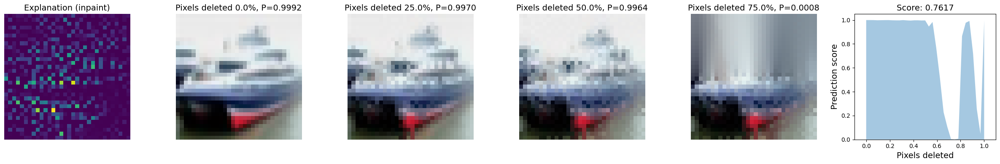

inpaint:  90%|████████▉ | 899/1000 [00:42<00:03, 25.49it/s]

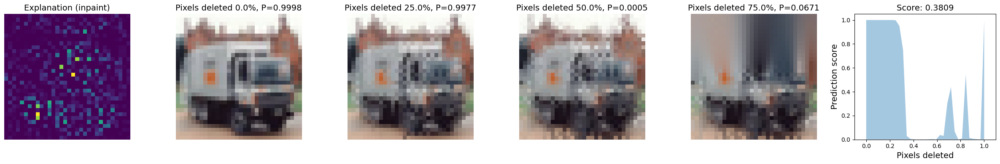

inpaint: 100%|██████████| 1000/1000 [00:46<00:00, 21.31it/s]


np.float64(0.44728018165436934)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 579.45it/s]

0
100
200


201it [00:00, 758.22it/s]

300


492it [00:00, 553.01it/s]

400
500
600


858it [00:01, 803.69it/s]

700
800
900


1000it [00:01, 682.64it/s]


np.float32(0.4503916)

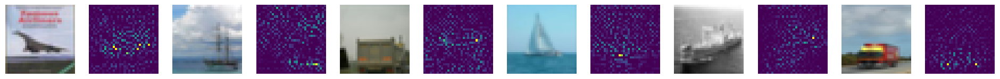

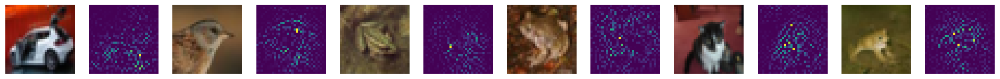

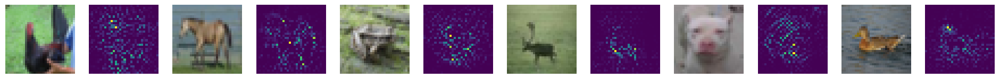

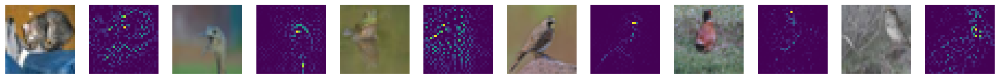

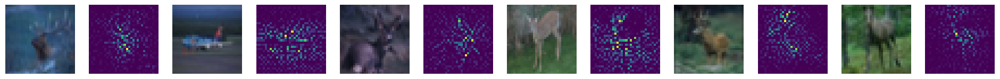

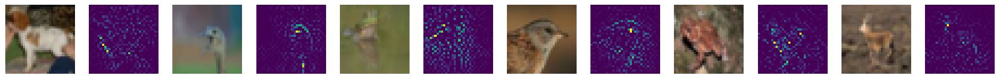

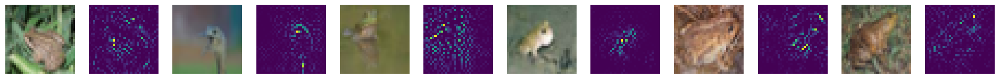

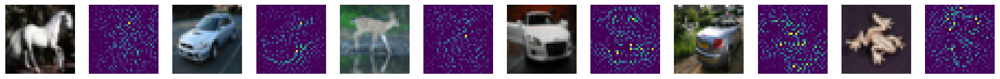

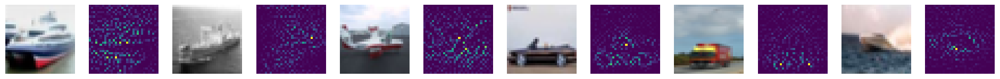

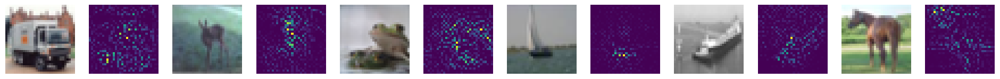

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [02:08<00:00,  7.79it/s]

Mean time for 1000 explanations: 0.1310511417388916
Mean time for 1000 explanations: 0.11859665155410766


<Figure size 640x480 with 0 Axes>

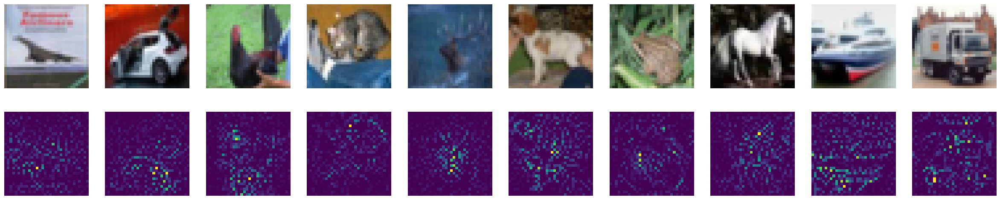

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

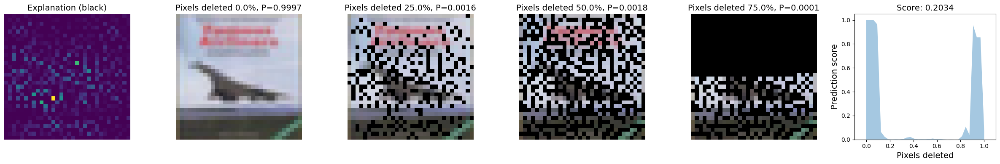

black:  10%|▉         | 97/1000 [00:02<00:15, 57.76it/s]

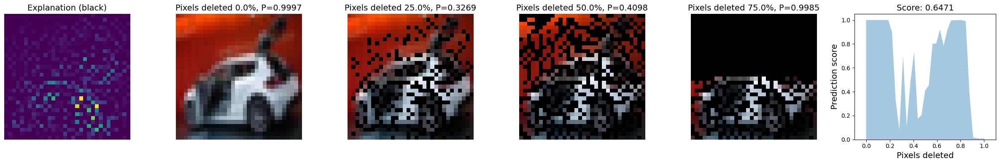

black:  20%|█▉        | 199/1000 [00:04<00:14, 56.51it/s]

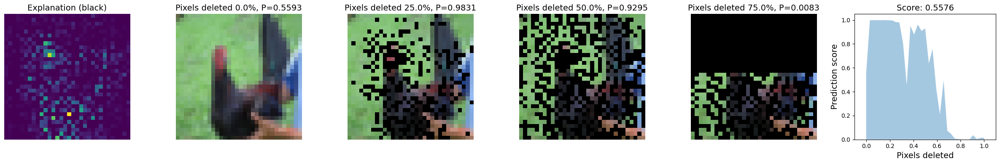

black:  30%|██▉       | 295/1000 [00:06<00:12, 56.80it/s]

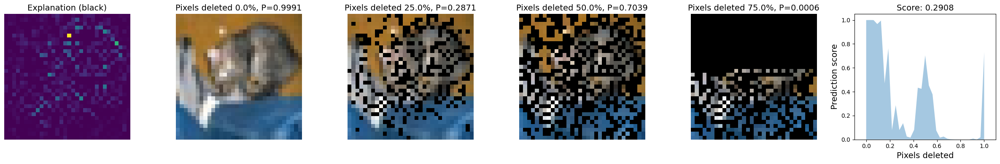

black:  40%|███▉      | 397/1000 [00:08<00:12, 47.45it/s]

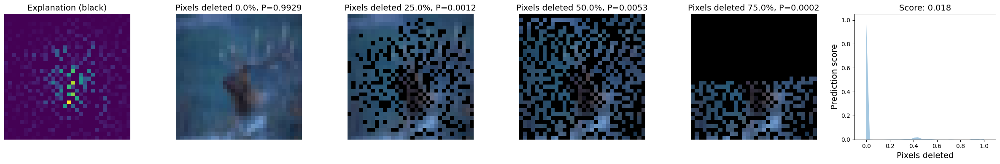

black:  50%|████▉     | 496/1000 [00:11<00:11, 43.05it/s]

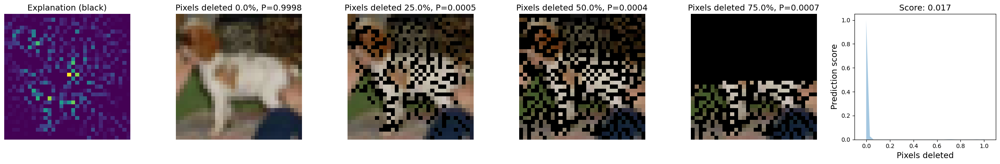

black:  60%|█████▉    | 597/1000 [00:14<00:07, 54.74it/s]

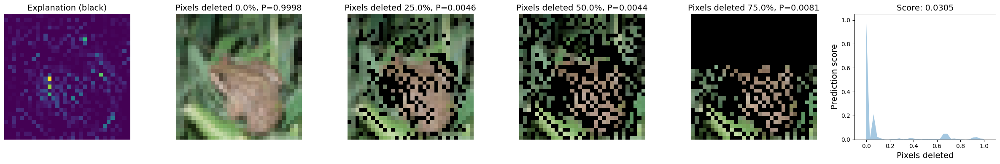

black:  70%|██████▉   | 699/1000 [00:16<00:05, 54.66it/s]

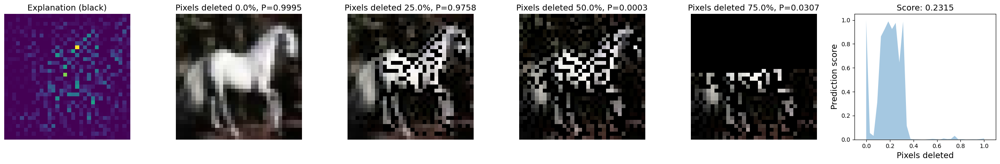

black:  80%|███████▉  | 795/1000 [00:18<00:03, 55.38it/s]

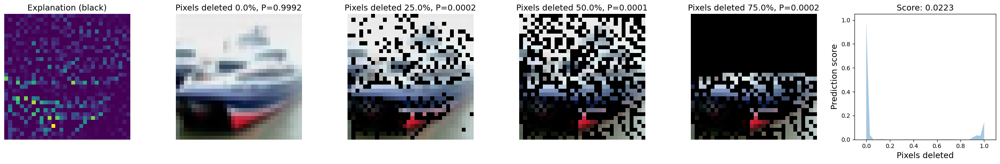

black:  90%|████████▉ | 897/1000 [00:20<00:01, 55.36it/s]

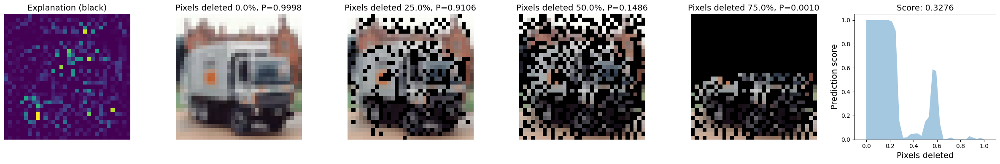

black: 100%|██████████| 1000/1000 [00:23<00:00, 43.04it/s]


np.float64(0.20240686692074641)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

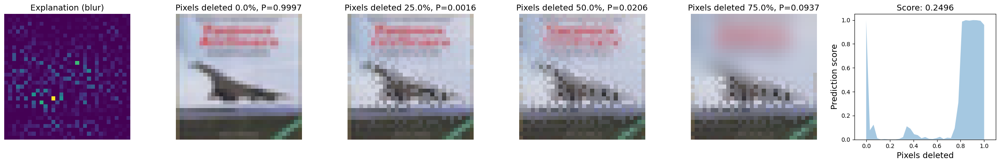

blur:  10%|▉         | 99/1000 [00:02<00:18, 49.66it/s]

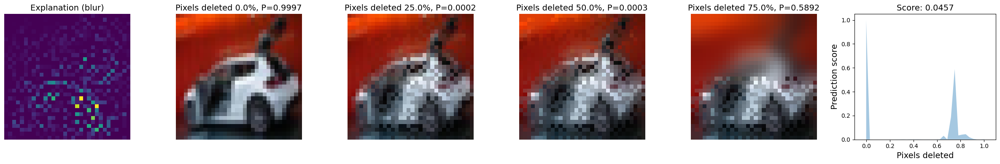

blur:  20%|█▉        | 195/1000 [00:04<00:14, 56.81it/s]

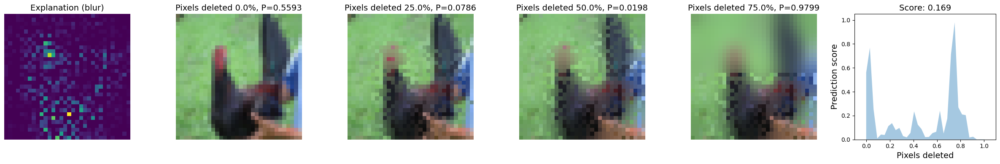

blur:  30%|███       | 300/1000 [00:07<00:12, 58.29it/s]

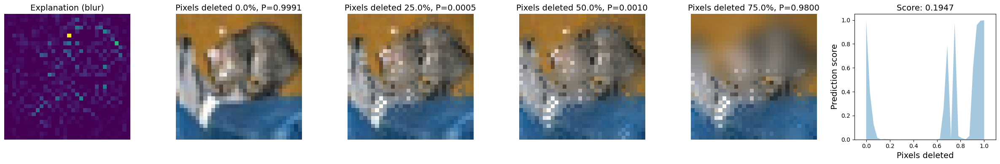

blur:  40%|███▉      | 399/1000 [00:09<00:10, 58.83it/s]

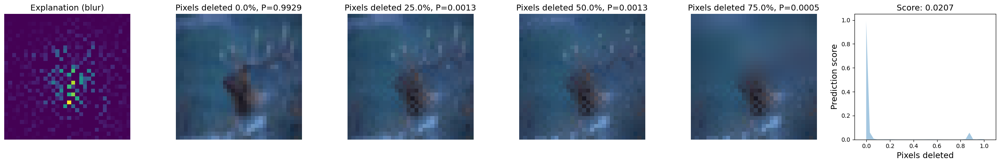

blur:  50%|████▉     | 495/1000 [00:11<00:08, 57.49it/s]

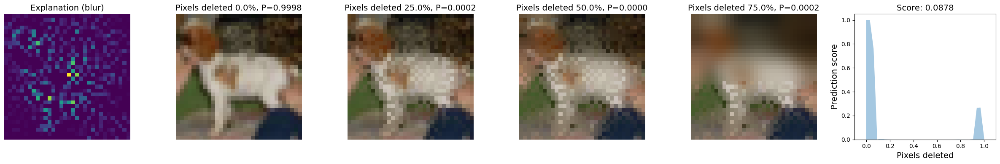

blur:  60%|█████▉    | 597/1000 [00:13<00:08, 45.02it/s]

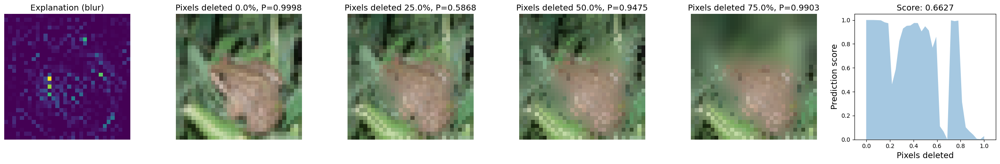

blur:  70%|██████▉   | 697/1000 [00:16<00:07, 43.07it/s]

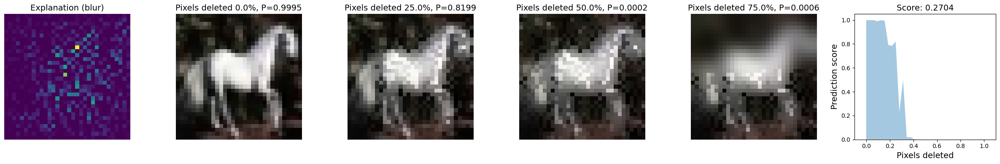

blur:  80%|███████▉  | 797/1000 [00:19<00:03, 53.29it/s]

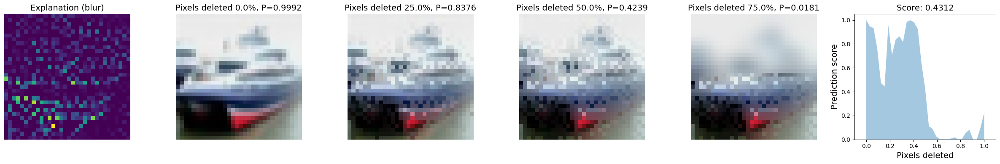

blur:  90%|████████▉ | 899/1000 [00:21<00:01, 55.46it/s]

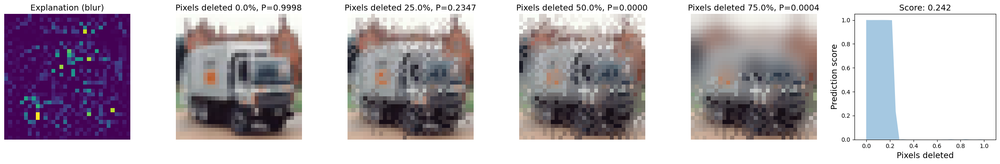

blur: 100%|██████████| 1000/1000 [00:24<00:00, 41.60it/s]


np.float64(0.3334479955050738)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

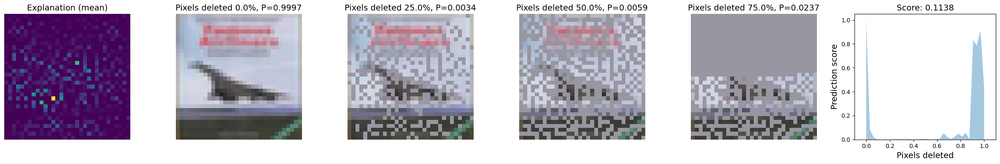

mean:  10%|▉         | 97/1000 [00:02<00:15, 57.29it/s]

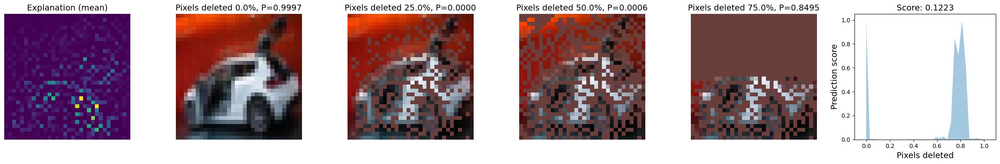

mean:  20%|█▉        | 198/1000 [00:04<00:17, 46.69it/s]

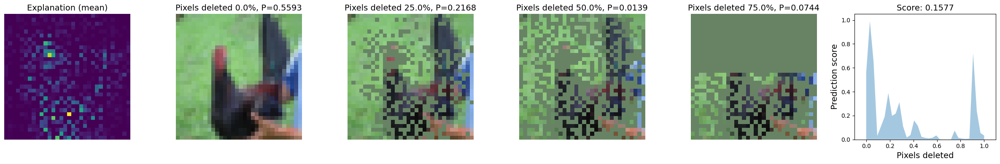

mean:  30%|██▉       | 298/1000 [00:07<00:13, 52.94it/s]

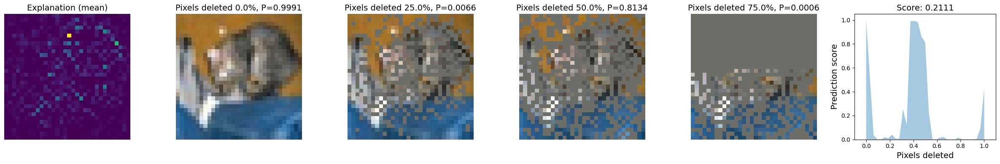

mean:  40%|████      | 400/1000 [00:09<00:10, 54.78it/s]

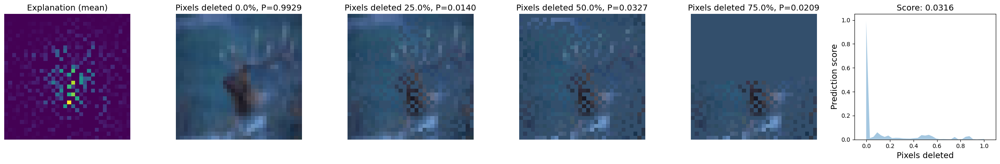

mean:  50%|████▉     | 496/1000 [00:11<00:09, 55.79it/s]

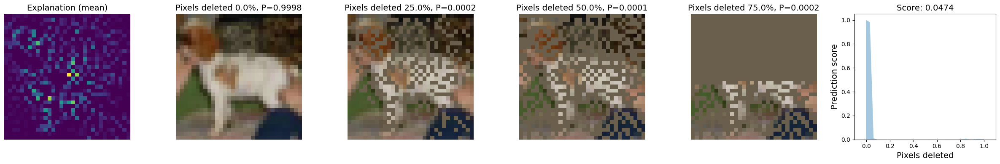

mean:  60%|█████▉    | 598/1000 [00:14<00:07, 55.33it/s]

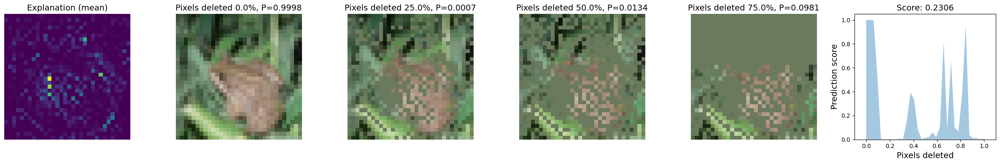

mean:  70%|███████   | 700/1000 [00:16<00:05, 56.53it/s]

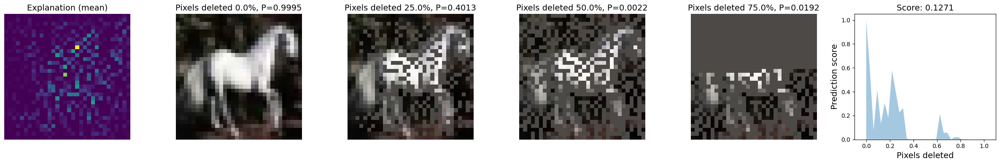

mean:  80%|███████▉  | 796/1000 [00:18<00:04, 44.05it/s]

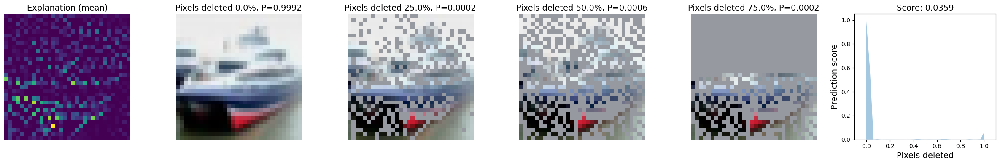

mean:  90%|█████████ | 900/1000 [00:21<00:01, 51.90it/s]

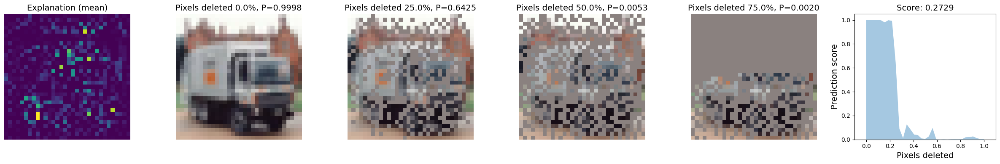

mean: 100%|██████████| 1000/1000 [00:23<00:00, 41.79it/s]


np.float64(0.23514916156445526)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

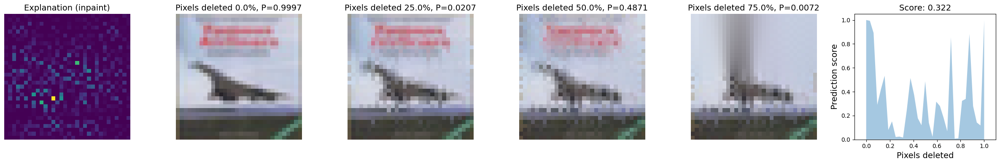

inpaint:  10%|▉         | 99/1000 [00:03<00:33, 26.56it/s]

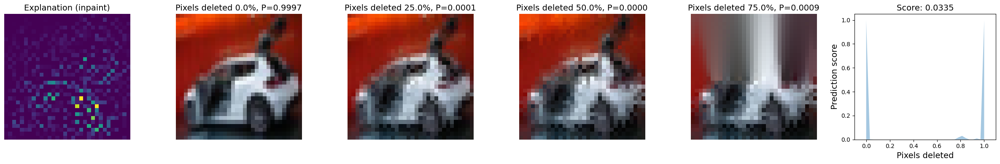

inpaint:  20%|█▉        | 198/1000 [00:08<00:39, 20.28it/s]

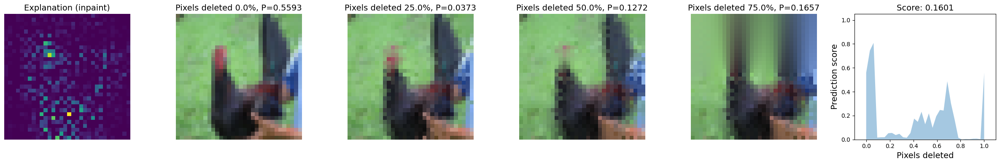

inpaint:  30%|███       | 300/1000 [00:13<00:25, 27.53it/s]

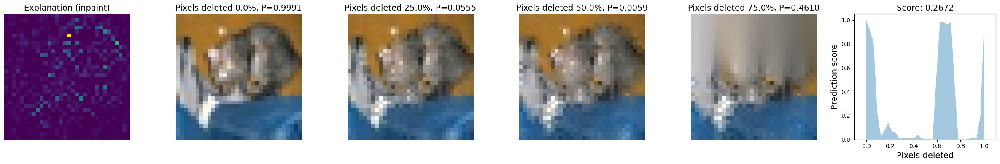

inpaint:  40%|███▉      | 399/1000 [00:17<00:22, 26.93it/s]

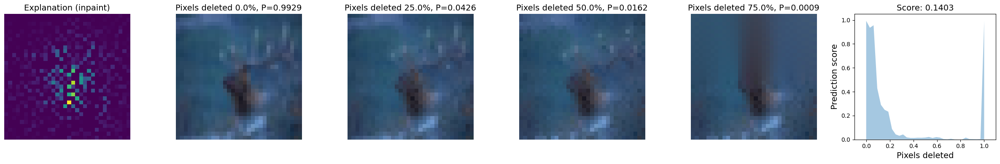

inpaint:  50%|████▉     | 499/1000 [00:22<00:26, 18.74it/s]

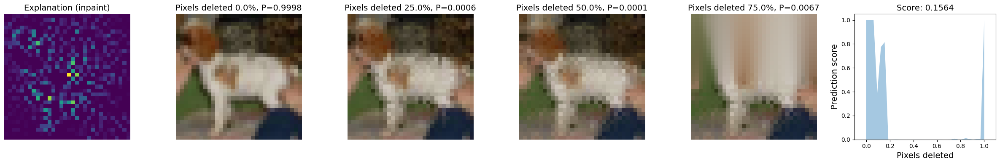

inpaint:  60%|██████    | 600/1000 [00:28<00:15, 25.05it/s]

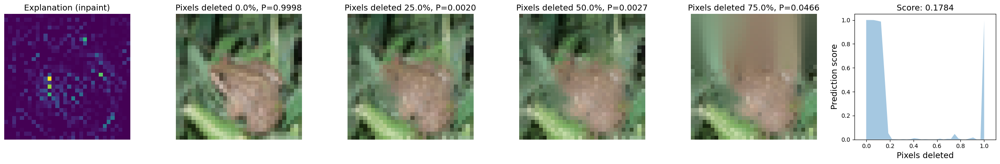

inpaint:  70%|██████▉   | 699/1000 [00:32<00:11, 25.49it/s]

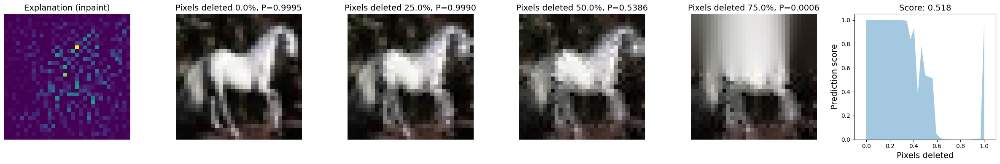

inpaint:  80%|████████  | 800/1000 [00:37<00:10, 18.96it/s]

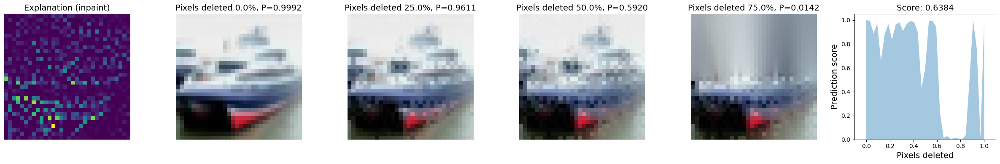

inpaint:  90%|████████▉ | 899/1000 [00:42<00:04, 24.49it/s]

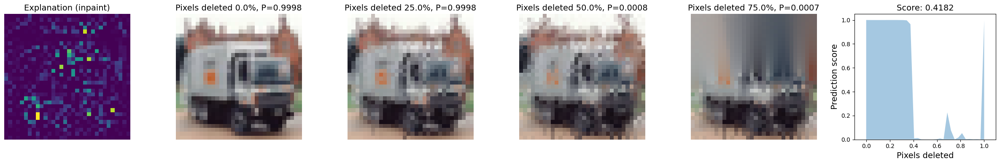

inpaint: 100%|██████████| 1000/1000 [00:47<00:00, 21.21it/s]


np.float64(0.4065060185663987)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

93it [00:00, 929.88it/s]

0
100
200


436it [00:00, 959.77it/s]

300
400


677it [00:00, 1091.00it/s]

500
600
700


801it [00:00, 903.56it/s] 

800
900


1000it [00:01, 654.41it/s]


np.float32(0.44661415)

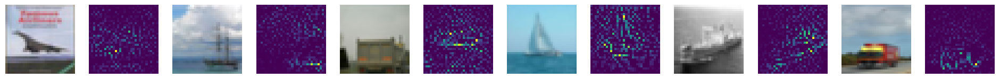

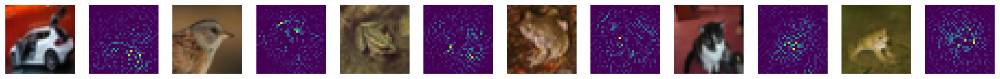

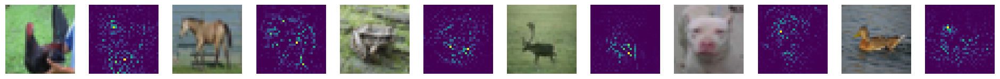

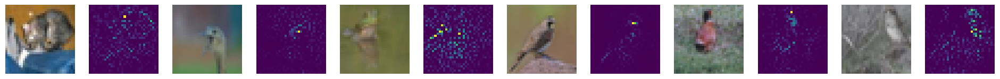

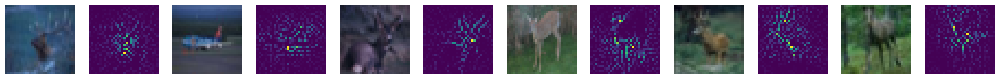

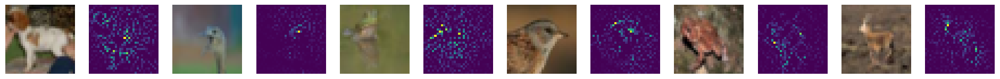

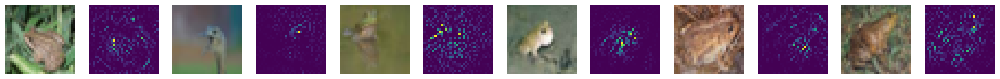

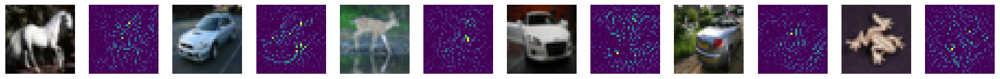

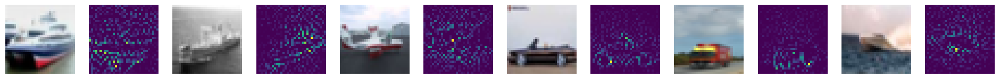

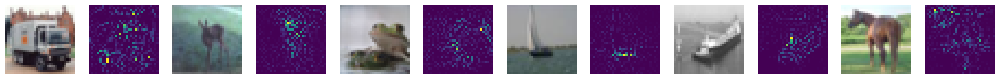

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 0 wrong: 1000 total: 1000


np.float64(100.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

### Resnet50

In [ ]:
model, target_layers = get_model("resnet50", "cifar10")
preprocess_transform = get_preprocess_transform("cifar10")
batch_predict = get_batch_predict(model, preprocess_transform)

Downloading: "https://huggingface.co/edadaltocg/resnet50_cifar10/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/resnet50_cifar10.pth


100%|██████████| 90.0M/90.0M [00:02<00:00, 44.0MB/s]


#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
%%capture
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
%%capture
exps_, t_ = expr.timed_batch_explain(imgs)

In [ ]:
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

Mean time for 1000 explanations: 1.7611588034629821
Mean time for 1000 explanations: 1.7540500383377076


<Figure size 640x480 with 0 Axes>

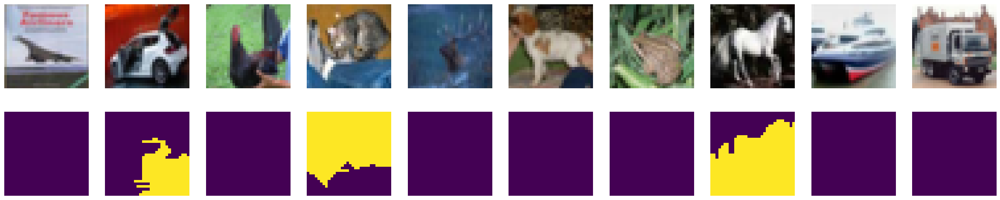

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

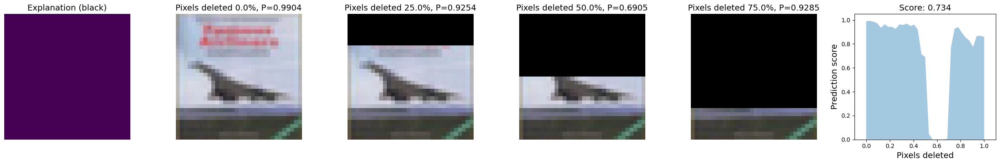

black:  10%|█         | 100/1000 [00:05<00:44, 20.39it/s]

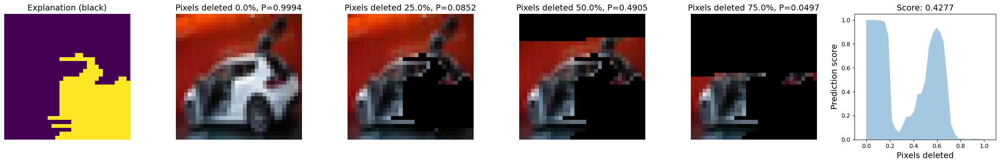

black:  20%|█▉        | 198/1000 [00:10<00:37, 21.40it/s]

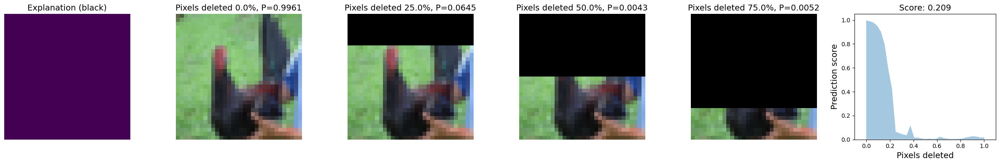

black:  30%|███       | 300/1000 [00:16<00:45, 15.26it/s]

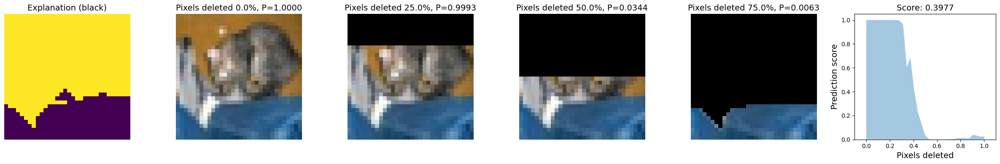

black:  40%|████      | 400/1000 [00:25<00:33, 17.75it/s]

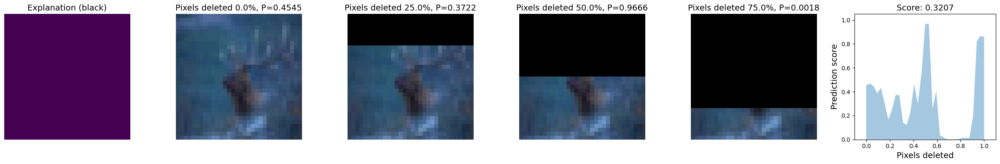

black:  50%|█████     | 500/1000 [00:31<00:26, 19.21it/s]

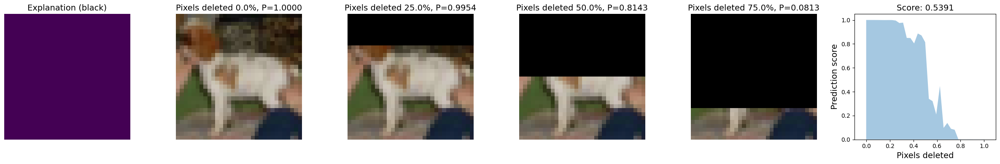

black:  60%|██████    | 600/1000 [00:38<00:28, 14.04it/s]

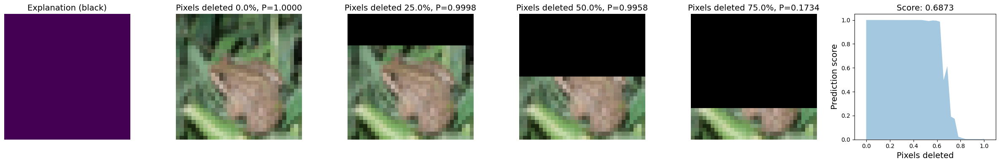

black:  70%|██████▉   | 699/1000 [00:45<00:17, 16.90it/s]

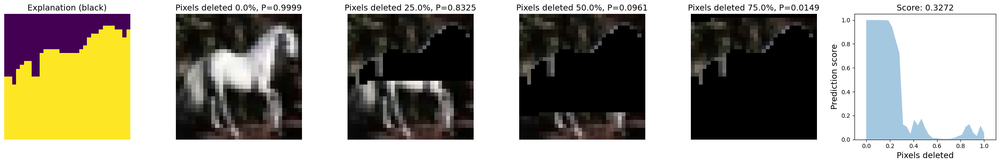

black:  80%|███████▉  | 799/1000 [00:52<00:13, 15.44it/s]

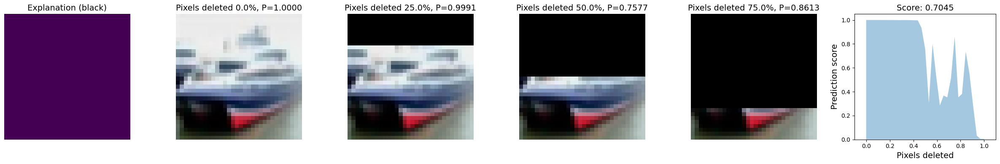

black:  90%|████████▉ | 898/1000 [00:58<00:04, 20.96it/s]

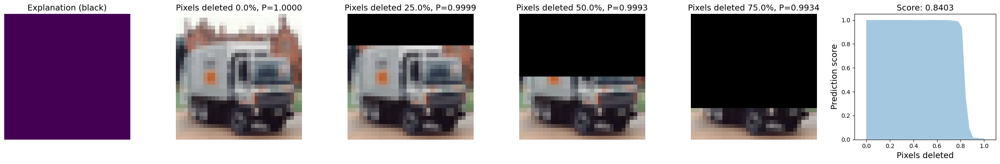

black: 100%|██████████| 1000/1000 [01:03<00:00, 15.76it/s]


np.float64(0.5734501428344907)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

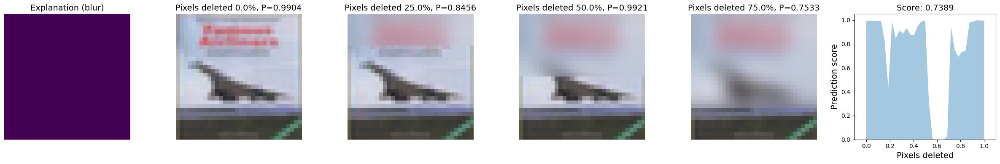

blur:  10%|█         | 100/1000 [00:06<00:46, 19.28it/s]

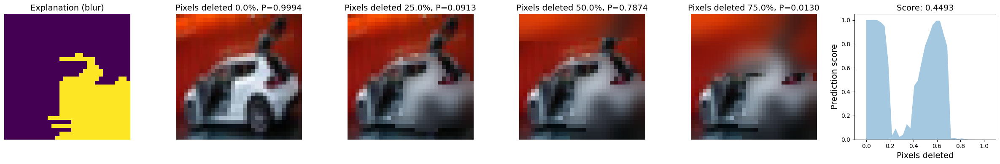

blur:  20%|██        | 200/1000 [00:13<00:53, 14.89it/s]

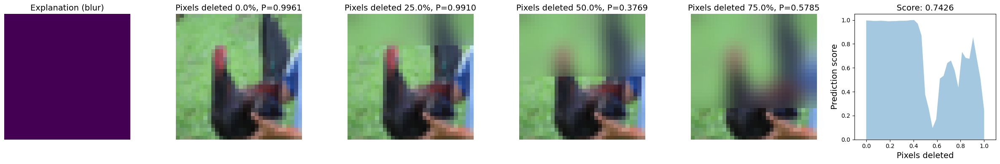

blur:  30%|███       | 300/1000 [00:20<00:41, 17.04it/s]

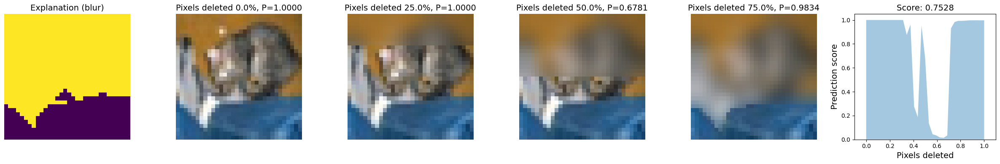

blur:  40%|███▉      | 398/1000 [00:25<00:28, 21.33it/s]

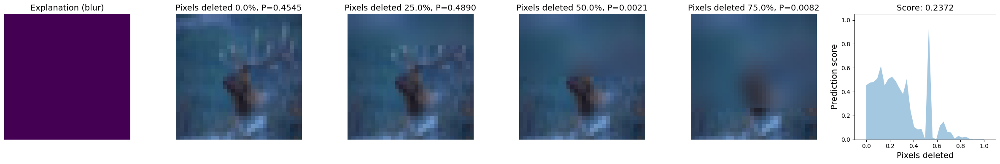

blur:  50%|█████     | 500/1000 [00:31<00:25, 19.27it/s]

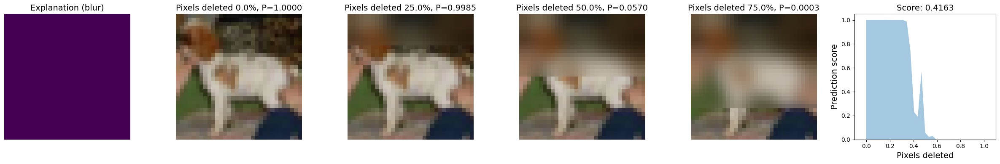

blur:  60%|█████▉    | 598/1000 [00:36<00:18, 21.28it/s]

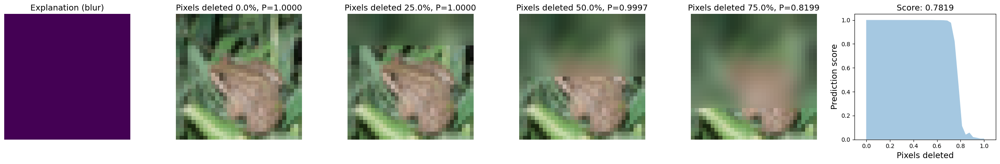

blur:  70%|███████   | 700/1000 [00:41<00:14, 20.44it/s]

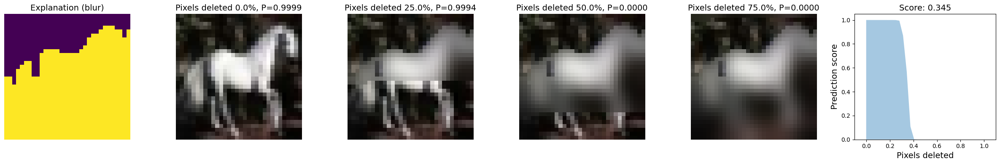

blur:  80%|████████  | 800/1000 [00:47<00:12, 15.58it/s]

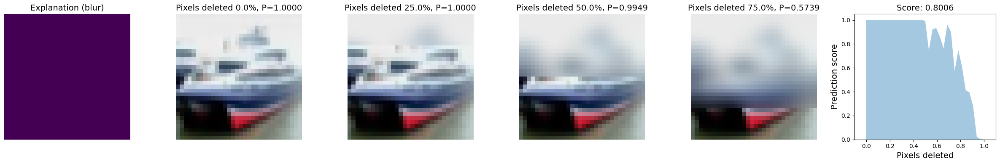

blur:  90%|█████████ | 900/1000 [00:52<00:04, 21.13it/s]

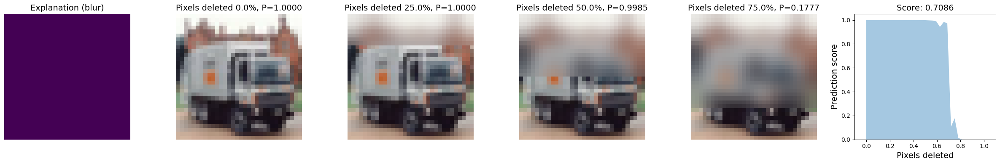

blur: 100%|██████████| 1000/1000 [00:58<00:00, 17.18it/s]


np.float64(0.5852280281481641)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

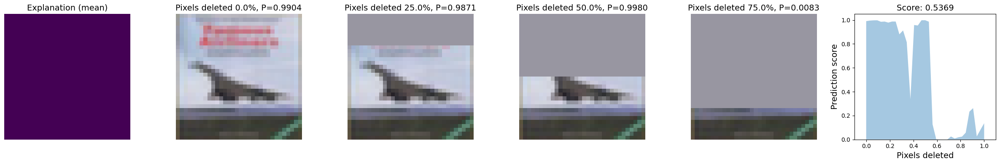

mean:  10%|▉         | 99/1000 [00:05<00:41, 21.53it/s]

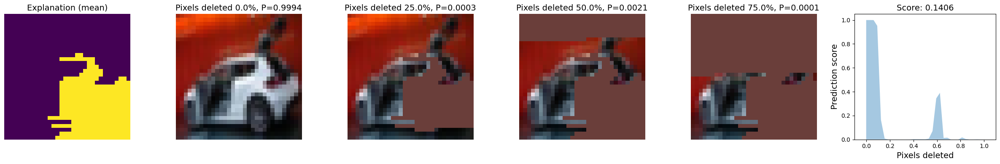

mean:  20%|█▉        | 198/1000 [00:10<00:37, 21.41it/s]

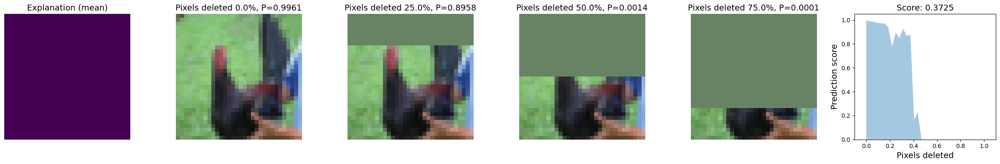

mean:  30%|███       | 300/1000 [00:15<00:35, 19.67it/s]

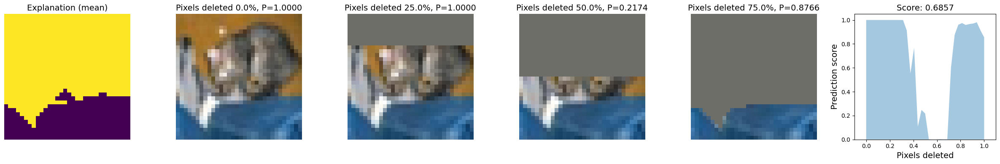

mean:  40%|███▉      | 399/1000 [00:21<00:29, 20.50it/s]

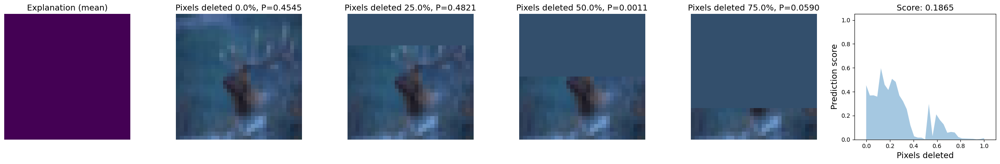

mean:  50%|████▉     | 499/1000 [00:26<00:25, 19.65it/s]

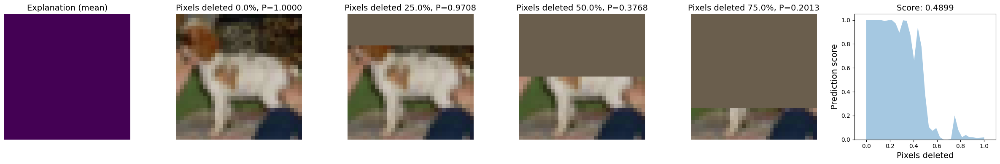

mean:  60%|█████▉    | 599/1000 [00:32<00:19, 21.06it/s]

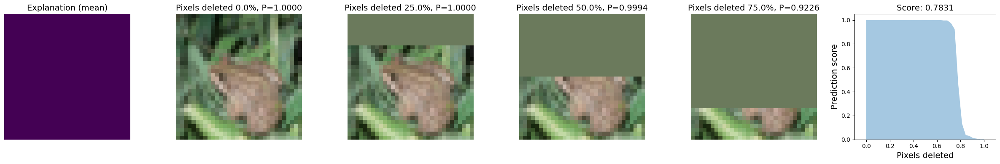

mean:  70%|██████▉   | 698/1000 [00:37<00:14, 21.11it/s]

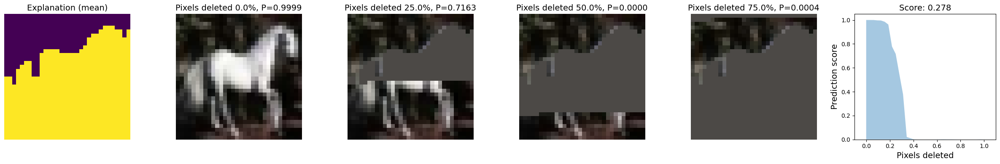

mean:  80%|███████▉  | 799/1000 [00:42<00:10, 19.57it/s]

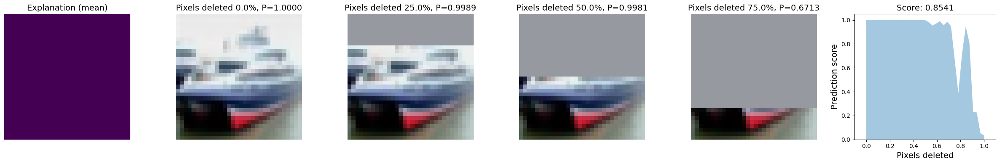

mean:  90%|█████████ | 900/1000 [00:49<00:04, 21.07it/s]

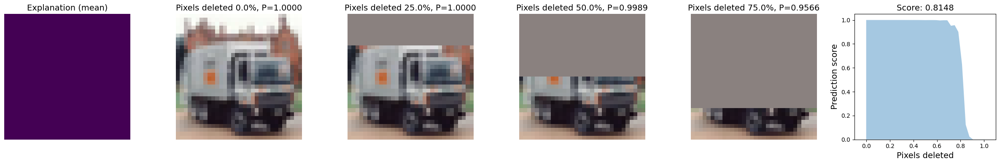

mean: 100%|██████████| 1000/1000 [00:54<00:00, 18.43it/s]


np.float64(0.5530357197969795)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

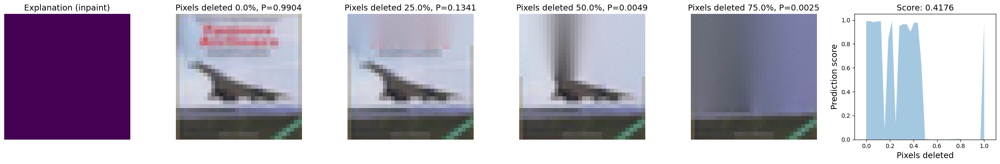

inpaint:  10%|▉         | 99/1000 [00:06<00:50, 17.85it/s]

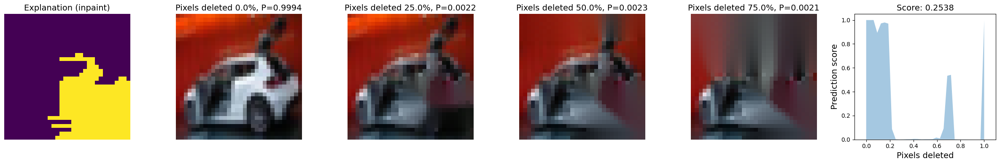

inpaint:  20%|█▉        | 199/1000 [00:12<00:44, 18.16it/s]

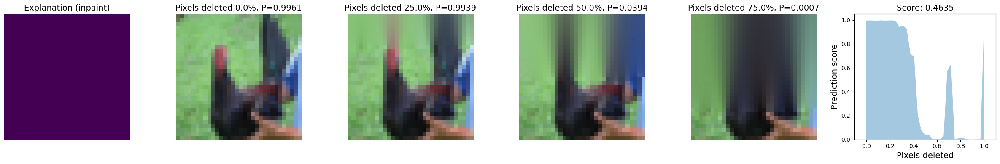

inpaint:  30%|██▉       | 299/1000 [00:19<00:44, 15.84it/s]

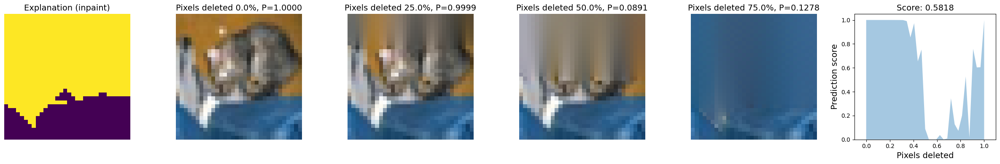

inpaint:  40%|███▉      | 399/1000 [00:25<00:34, 17.53it/s]

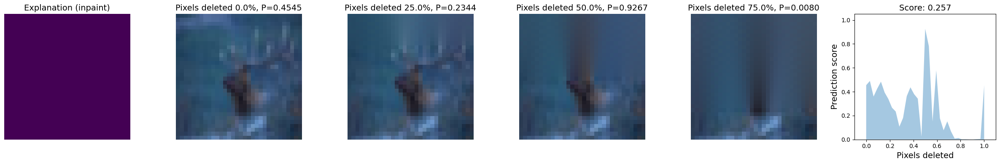

inpaint:  50%|████▉     | 499/1000 [00:31<00:32, 15.19it/s]

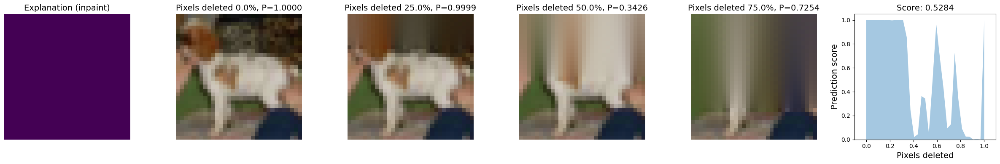

inpaint:  60%|█████▉    | 599/1000 [00:38<00:22, 18.02it/s]

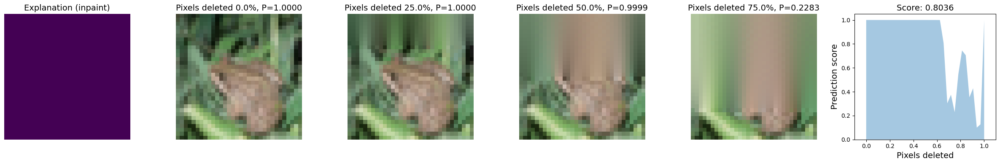

inpaint:  70%|██████▉   | 699/1000 [00:44<00:19, 15.43it/s]

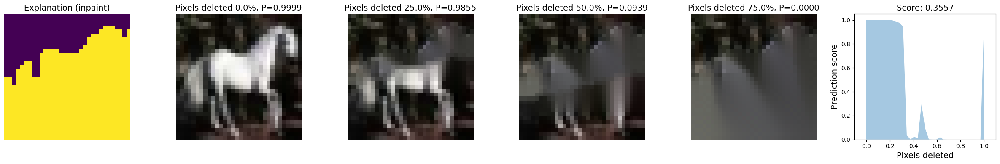

inpaint:  80%|███████▉  | 799/1000 [00:51<00:11, 17.67it/s]

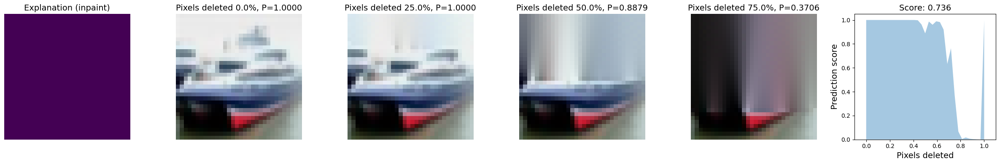

inpaint:  90%|████████▉ | 899/1000 [00:57<00:05, 17.83it/s]

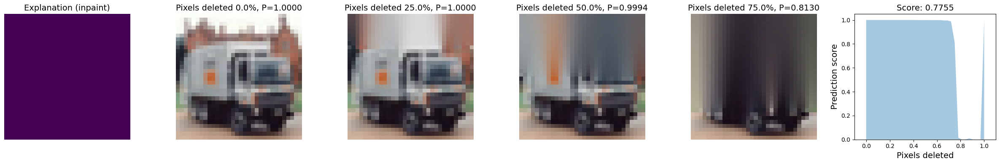

inpaint: 100%|██████████| 1000/1000 [01:03<00:00, 15.64it/s]


np.float64(0.5725555730895933)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
#exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
#print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [17:02<00:00,  1.02s/it]

Mean time for 1000 explanations: 0.9924735753536225


<Figure size 640x480 with 0 Axes>

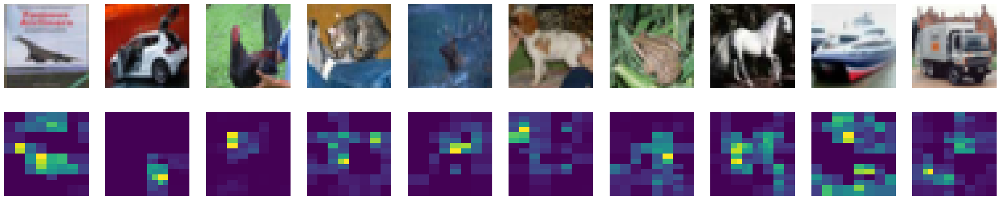

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

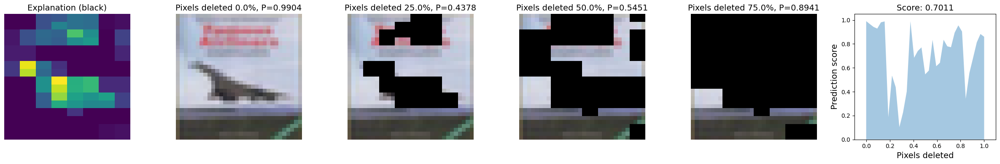

black:  10%|█         | 100/1000 [00:05<00:44, 20.32it/s]

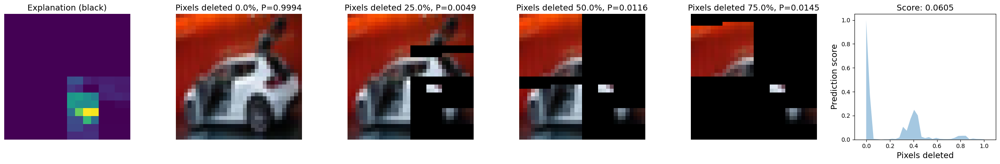

black:  20%|█▉        | 198/1000 [00:10<00:36, 21.69it/s]

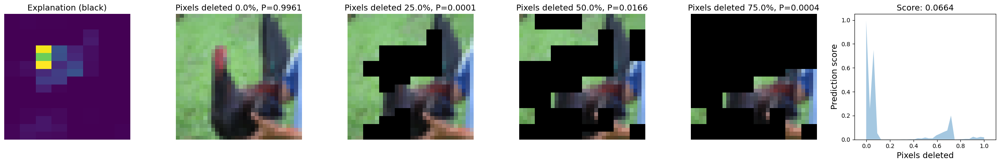

black:  30%|███       | 300/1000 [00:15<00:33, 21.20it/s]

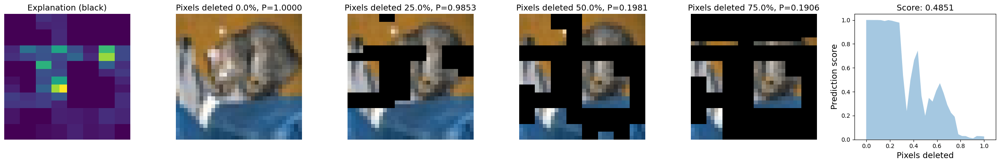

black:  40%|███▉      | 398/1000 [00:20<00:30, 19.74it/s]

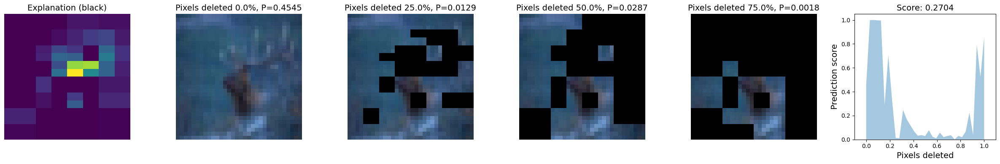

black:  50%|█████     | 500/1000 [00:26<00:23, 21.39it/s]

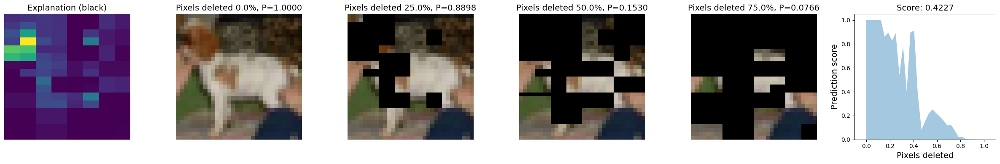

black:  60%|█████▉    | 599/1000 [00:31<00:18, 21.33it/s]

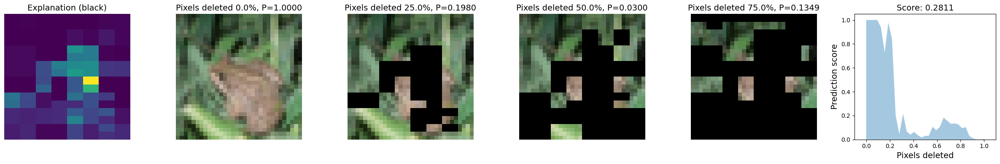

black:  70%|██████▉   | 698/1000 [00:37<00:14, 20.62it/s]

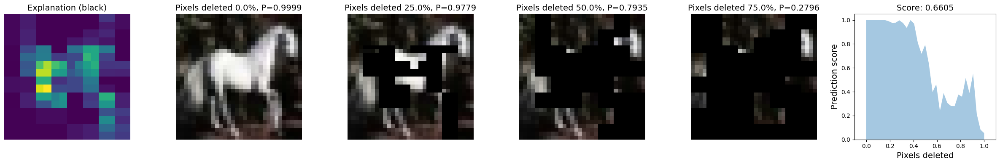

black:  80%|███████▉  | 799/1000 [00:42<00:09, 21.37it/s]

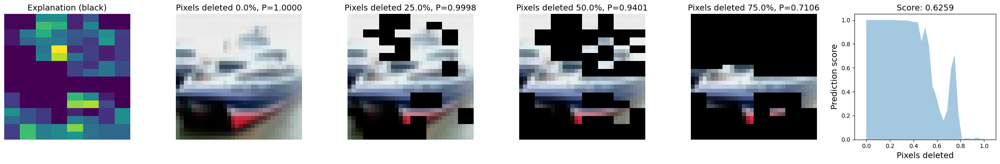

black:  90%|████████▉ | 898/1000 [00:47<00:05, 20.16it/s]

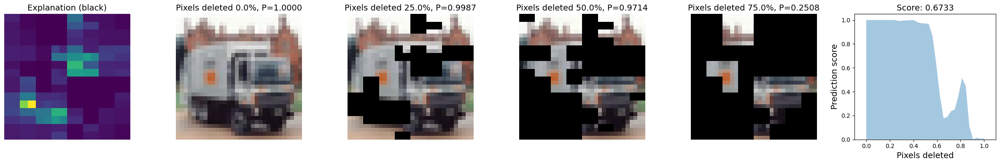

black: 100%|██████████| 1000/1000 [00:53<00:00, 18.83it/s]


np.float64(0.3228475255355068)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

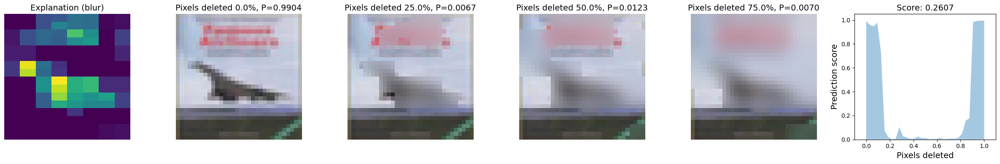

blur:  10%|█         | 100/1000 [00:05<00:41, 21.66it/s]

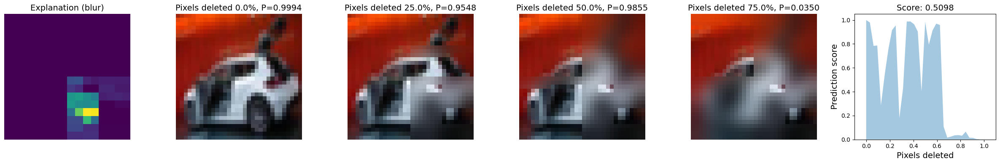

blur:  20%|█▉        | 199/1000 [00:10<00:39, 20.49it/s]

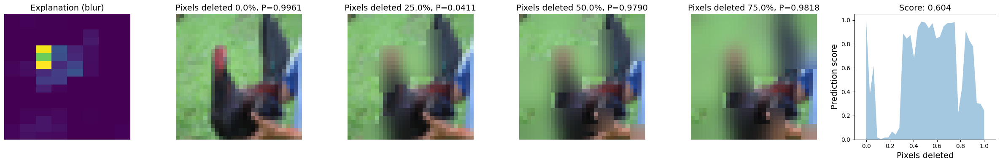

blur:  30%|███       | 300/1000 [00:15<00:32, 21.49it/s]

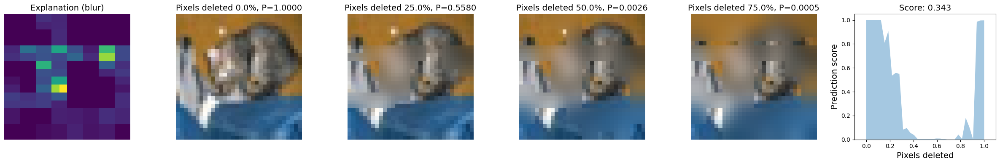

blur:  40%|███▉      | 399/1000 [00:20<00:27, 21.77it/s]

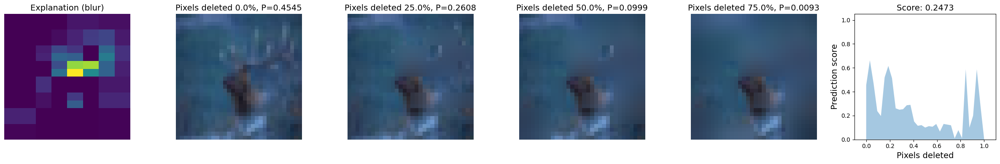

blur:  50%|█████     | 500/1000 [00:26<00:28, 17.48it/s]

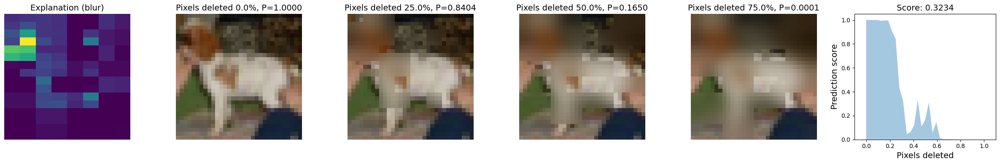

blur:  60%|██████    | 600/1000 [00:34<00:23, 17.04it/s]

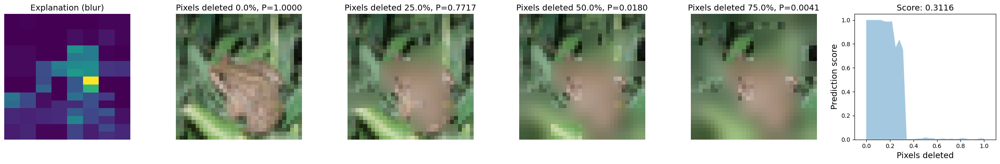

blur:  70%|██████▉   | 698/1000 [00:41<00:17, 16.91it/s]

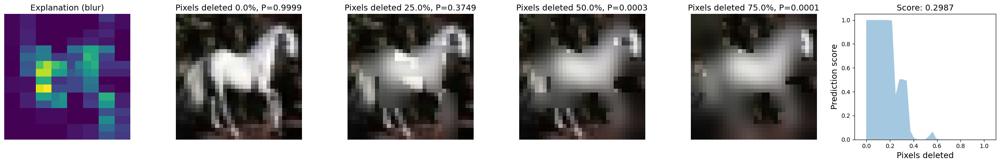

blur:  80%|████████  | 800/1000 [00:48<00:10, 19.17it/s]

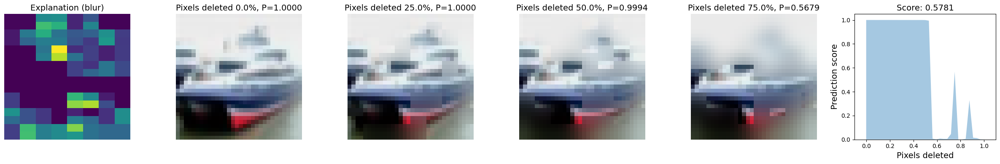

blur:  90%|████████▉ | 899/1000 [00:54<00:06, 15.90it/s]

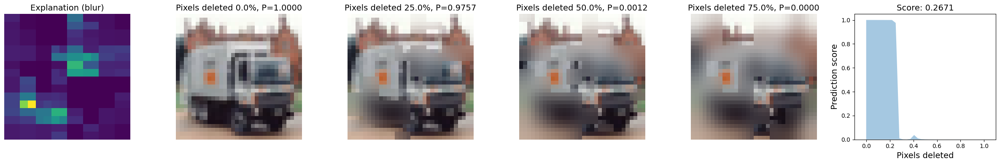

blur: 100%|██████████| 1000/1000 [01:00<00:00, 16.65it/s]


np.float64(0.3513208011552114)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

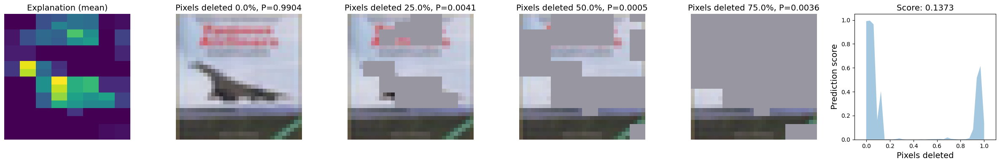

mean:  10%|█         | 100/1000 [00:04<00:41, 21.75it/s]

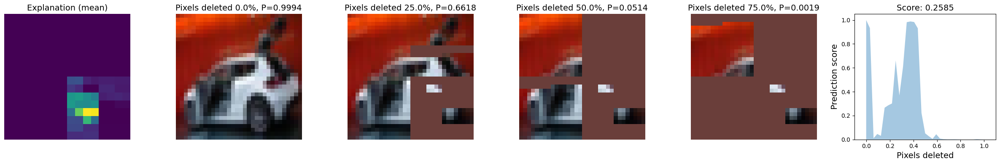

mean:  20%|█▉        | 199/1000 [00:10<00:37, 21.50it/s]

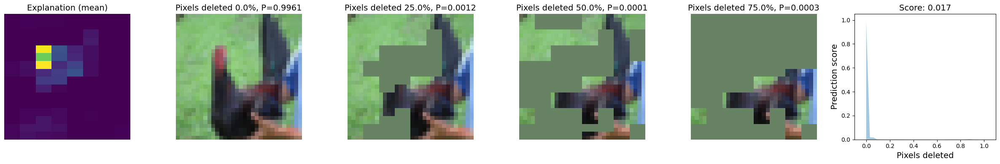

mean:  30%|██▉       | 298/1000 [00:15<00:32, 21.67it/s]

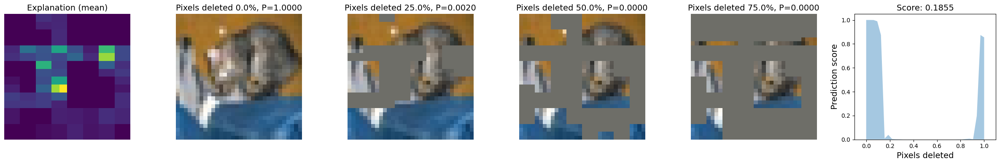

mean:  40%|████      | 400/1000 [00:20<00:29, 20.56it/s]

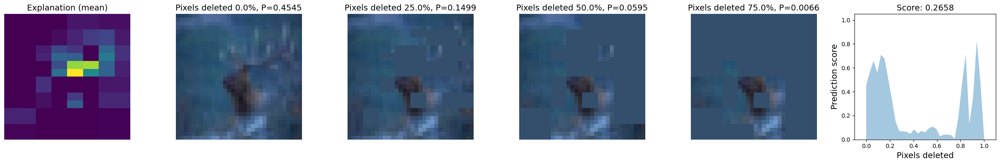

mean:  50%|█████     | 500/1000 [00:26<00:23, 21.62it/s]

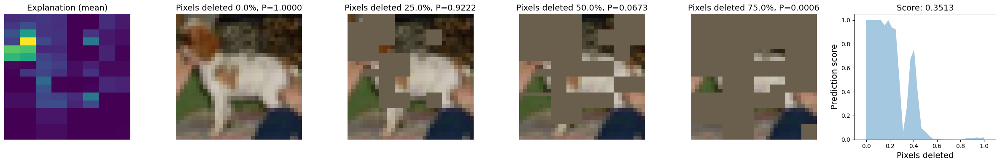

mean:  60%|█████▉    | 599/1000 [00:31<00:18, 21.73it/s]

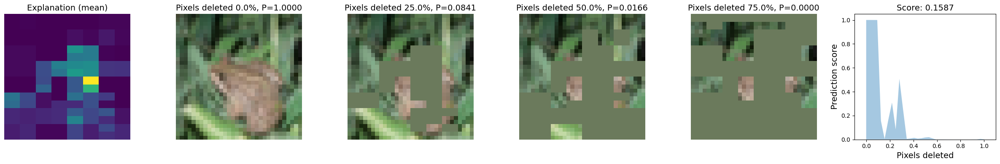

mean:  70%|███████   | 700/1000 [00:36<00:14, 20.32it/s]

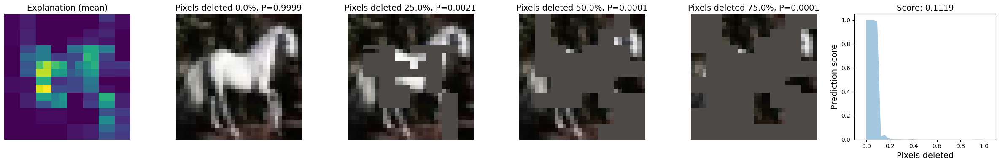

mean:  80%|███████▉  | 798/1000 [00:41<00:09, 21.27it/s]

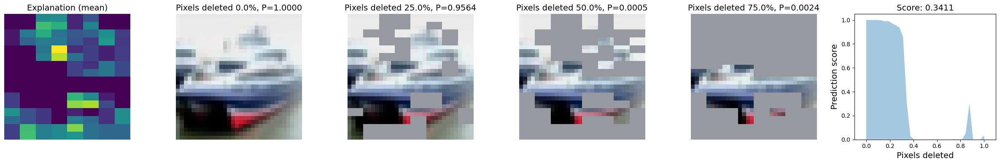

mean:  90%|█████████ | 900/1000 [00:47<00:04, 21.27it/s]

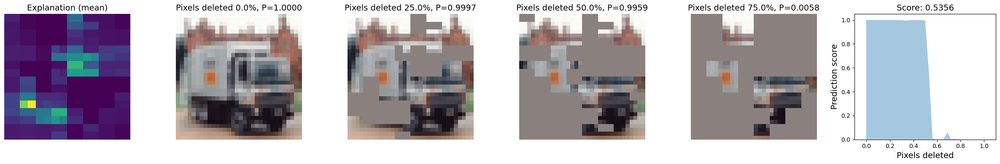

mean: 100%|██████████| 1000/1000 [00:54<00:00, 18.28it/s]


np.float64(0.2089745162597676)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

inpaint:   0%|          | 0/1000 [00:00<?, ?it/s]

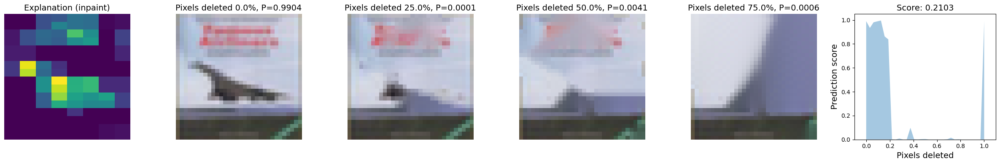

inpaint:  10%|█         | 100/1000 [00:08<01:10, 12.82it/s]

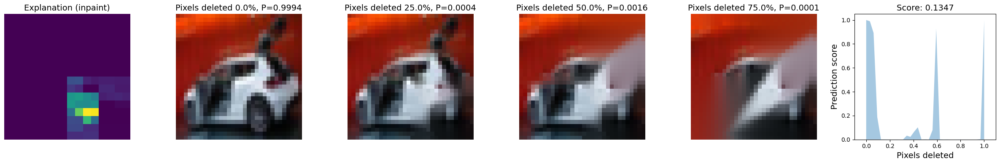

inpaint:  20%|█▉        | 199/1000 [00:20<00:54, 14.71it/s]

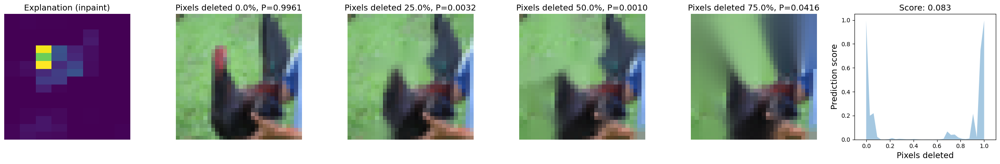

inpaint:  30%|███       | 300/1000 [00:30<00:51, 13.72it/s]

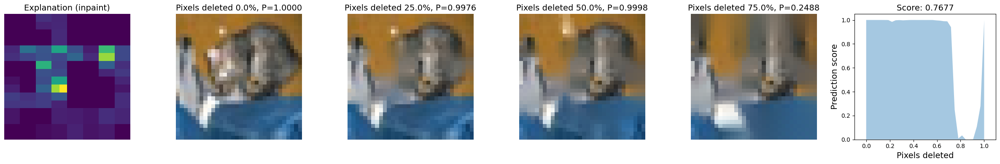

inpaint:  40%|████      | 400/1000 [00:36<00:34, 17.51it/s]

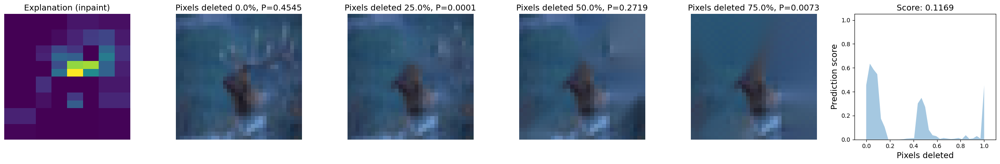

inpaint:  50%|█████     | 500/1000 [00:43<00:30, 16.29it/s]

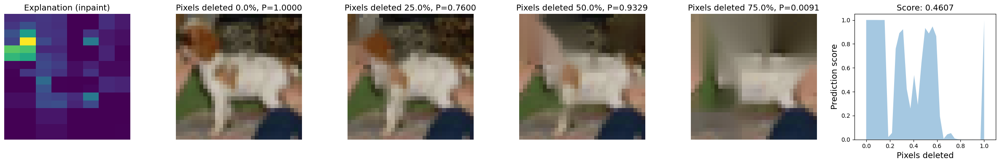

inpaint:  60%|██████    | 600/1000 [00:49<00:22, 17.53it/s]

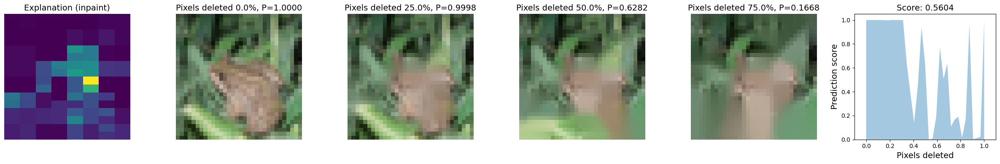

inpaint:  70%|███████   | 700/1000 [00:56<00:20, 14.59it/s]

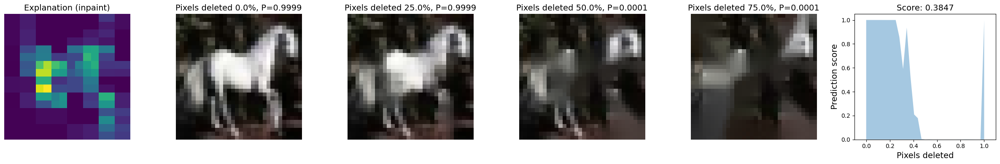

inpaint:  80%|████████  | 800/1000 [01:03<00:18, 10.89it/s]

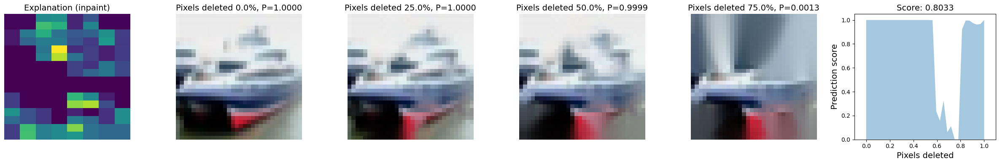

inpaint:  90%|█████████ | 900/1000 [01:10<00:07, 14.02it/s]

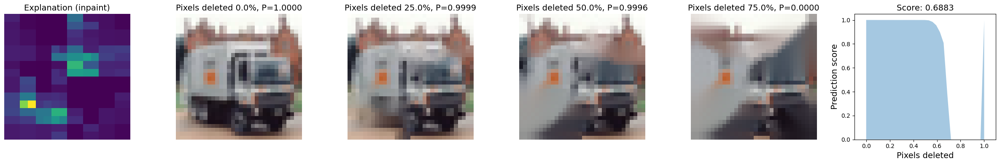

inpaint: 100%|██████████| 1000/1000 [01:17<00:00, 12.95it/s]


np.float64(0.4346497467279855)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
#exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
#print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:39<00:00, 25.38it/s]

Mean time for 1000 explanations: 0.03403356909751892


<Figure size 640x480 with 0 Axes>

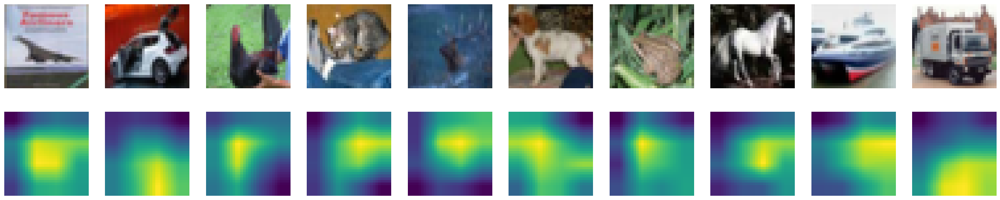

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

black:   0%|          | 0/1000 [00:00<?, ?it/s]

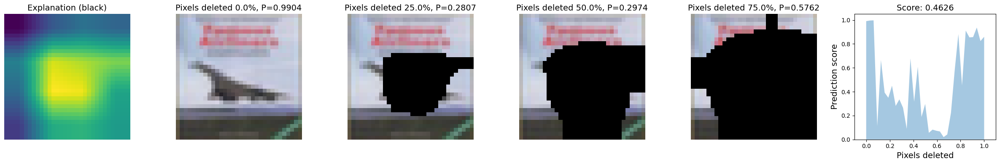

black:  10%|▉         | 98/1000 [00:05<00:42, 21.31it/s]

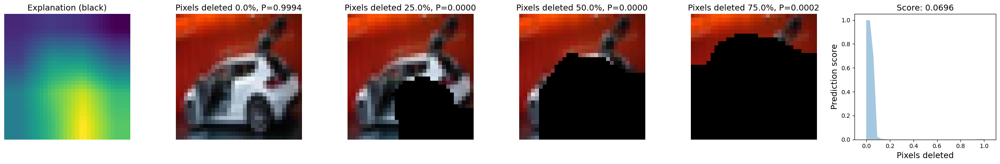

black:  20%|██        | 200/1000 [00:11<00:40, 19.64it/s]

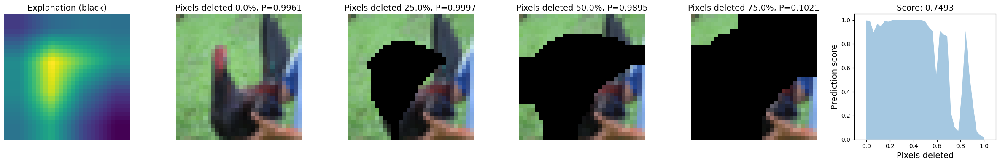

black:  30%|███       | 300/1000 [00:16<00:34, 20.16it/s]

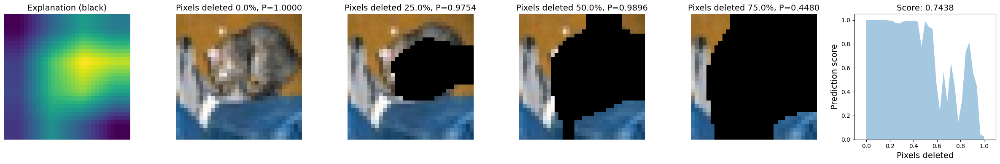

black:  40%|████      | 400/1000 [00:21<00:29, 20.22it/s]

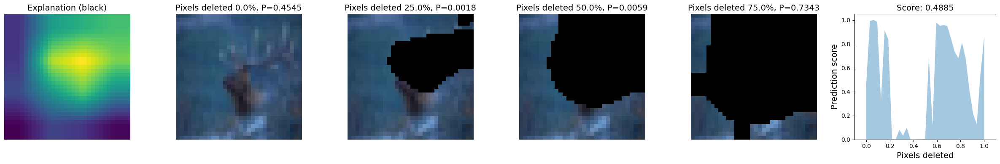

black:  50%|████▉     | 499/1000 [00:27<00:24, 20.14it/s]

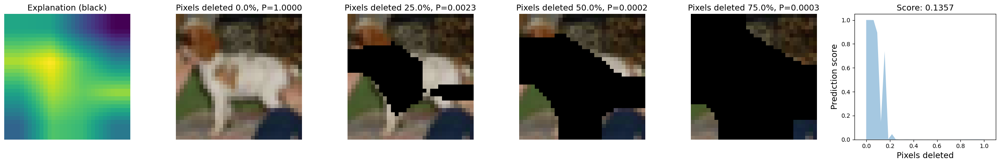

black:  60%|█████▉    | 599/1000 [00:33<00:20, 19.73it/s]

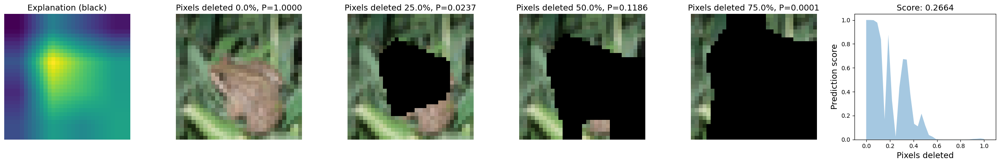

black:  70%|██████▉   | 699/1000 [00:38<00:16, 18.79it/s]

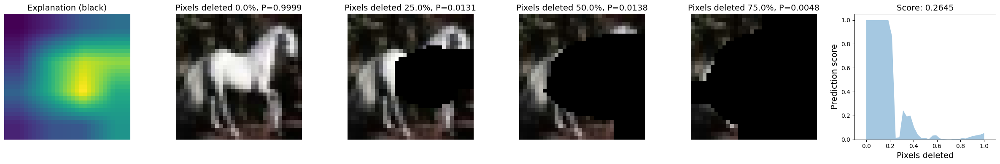

black:  80%|███████▉  | 799/1000 [00:46<00:11, 17.73it/s]

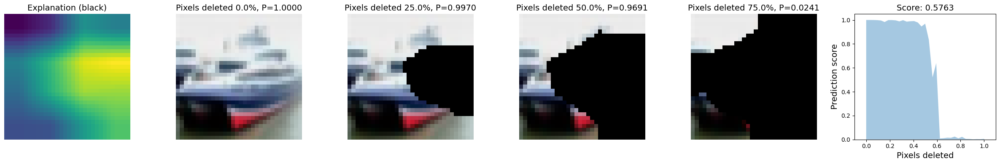

black:  90%|████████▉ | 899/1000 [00:53<00:05, 18.64it/s]

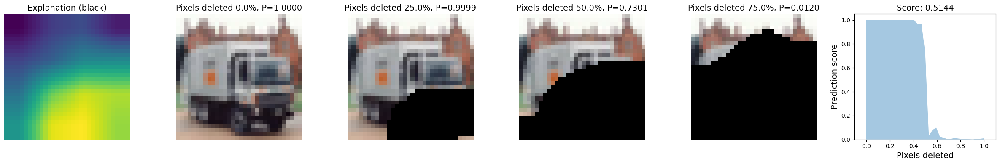

black: 100%|██████████| 1000/1000 [00:59<00:00, 16.83it/s]


np.float64(0.3263725661598693)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

blur:   0%|          | 0/1000 [00:00<?, ?it/s]

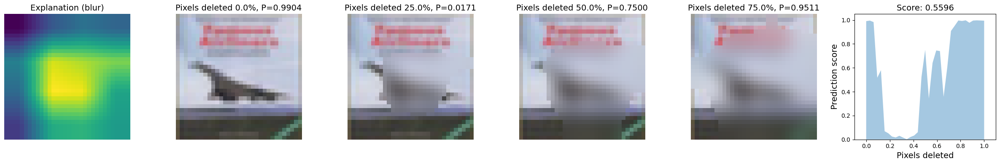

blur:  10%|▉         | 99/1000 [00:05<00:43, 20.66it/s]

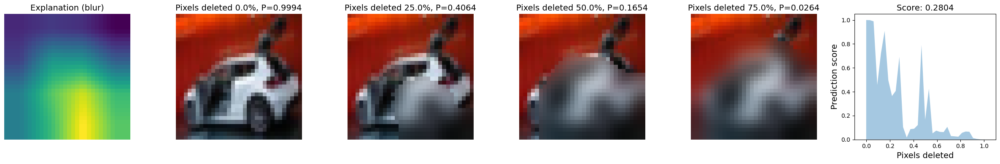

blur:  20%|█▉        | 198/1000 [00:10<00:39, 20.17it/s]

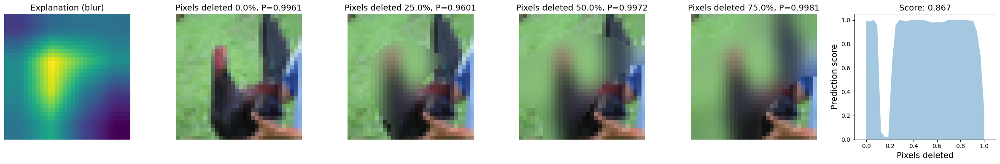

blur:  30%|██▉       | 299/1000 [00:16<00:35, 19.78it/s]

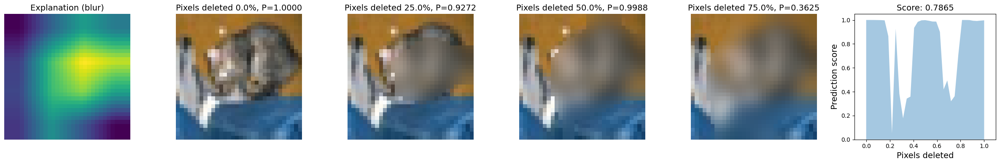

blur:  40%|███▉      | 399/1000 [00:21<00:33, 17.99it/s]

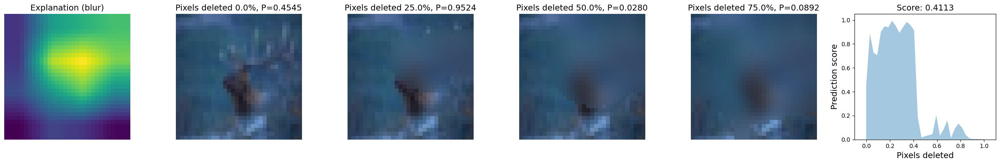

blur:  50%|█████     | 500/1000 [00:27<00:24, 20.02it/s]

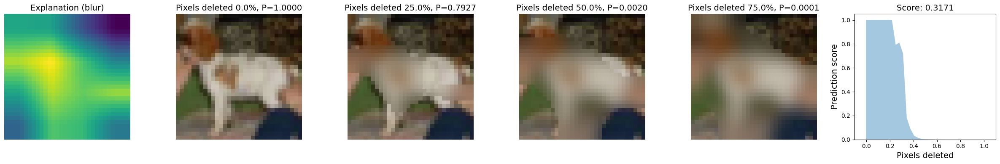

blur:  60%|█████▉    | 599/1000 [00:33<00:20, 19.70it/s]

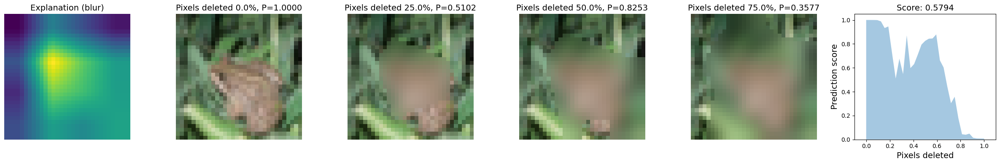

blur:  70%|██████▉   | 699/1000 [00:39<00:17, 17.69it/s]

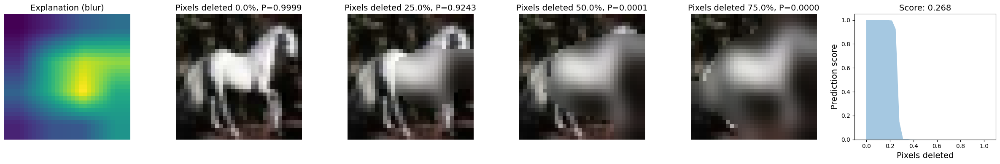

blur:  80%|███████▉  | 799/1000 [00:45<00:10, 19.44it/s]

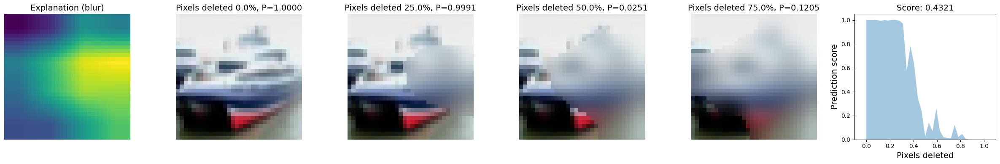

blur:  90%|████████▉ | 899/1000 [00:50<00:05, 17.79it/s]

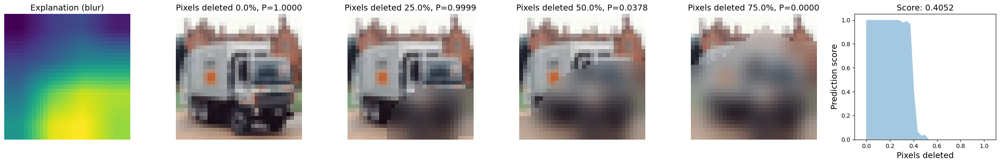

blur: 100%|██████████| 1000/1000 [00:56<00:00, 17.55it/s]


np.float64(0.37286735801005727)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

mean:   0%|          | 0/1000 [00:00<?, ?it/s]

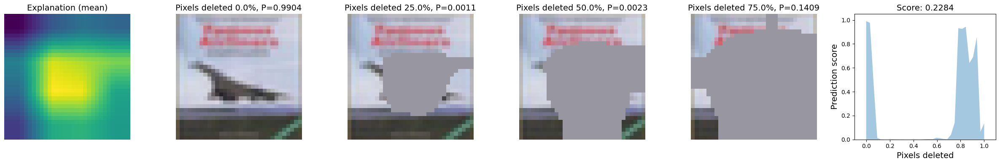

mean:  10%|█         | 100/1000 [00:05<00:45, 19.75it/s]

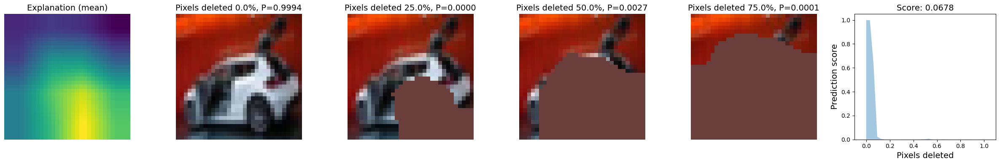

mean:  20%|██        | 200/1000 [00:11<00:48, 16.58it/s]

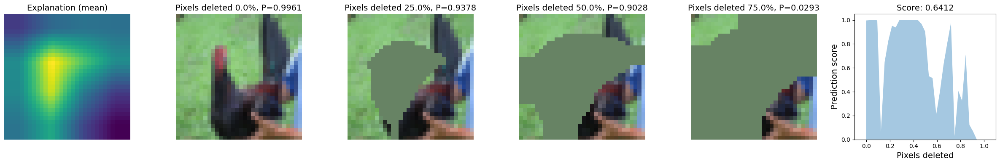

mean:  30%|██▉       | 299/1000 [01:13<00:33, 20.65it/s]

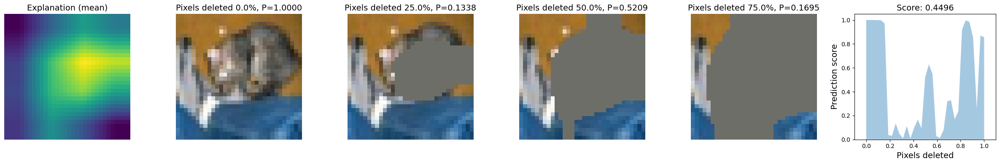

mean:  40%|███▉      | 398/1000 [01:18<00:29, 20.18it/s]

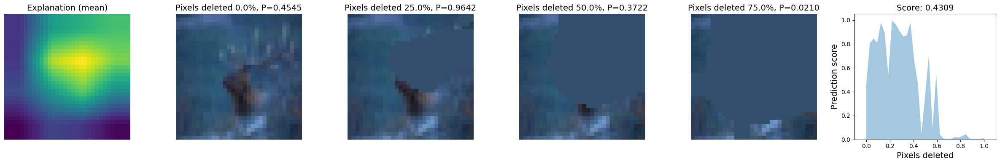

mean:  43%|████▎     | 432/1000 [01:37<00:53, 10.61it/s]

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity1(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_fidelity2(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_fidelity3(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_fidelity4(imgs, exps, model, preprocess_transform,
                             step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [09:37<00:00,  1.73it/s]

Mean time for 1000 explanations: 0.5562859890460968
Mean time for 1000 explanations: 0.5583687143325806


<Figure size 640x480 with 0 Axes>

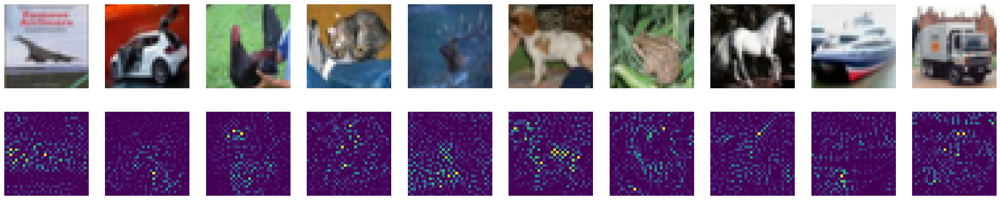

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [06:32,  2.55it/s]


np.float64(0.22274110389504137)

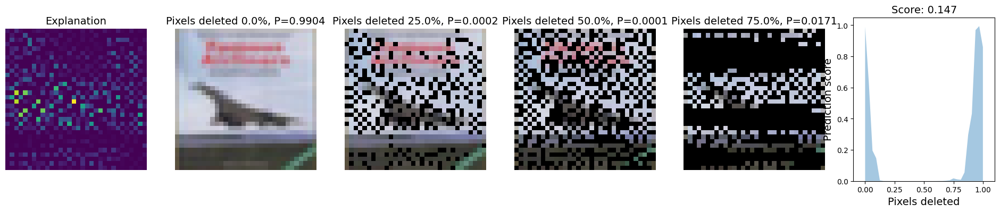

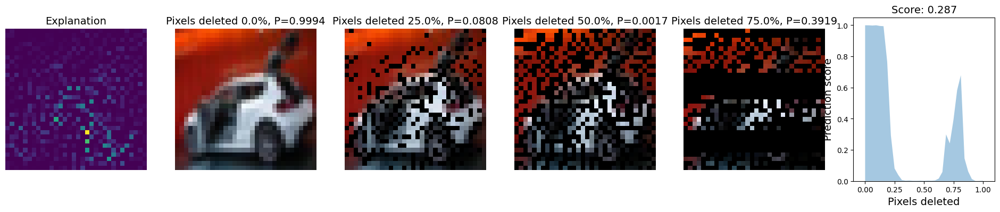

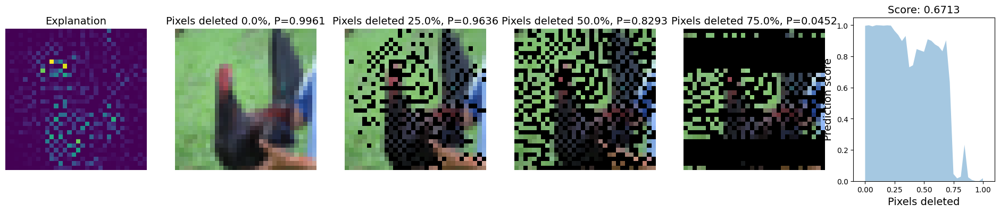

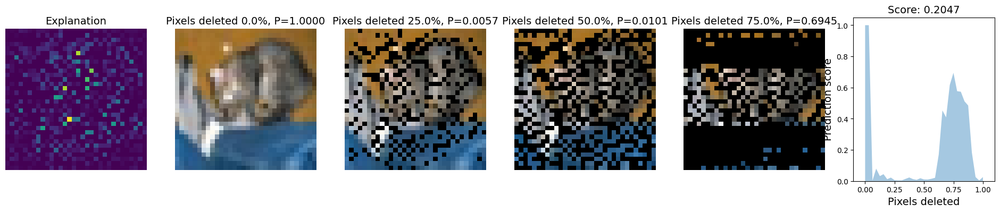

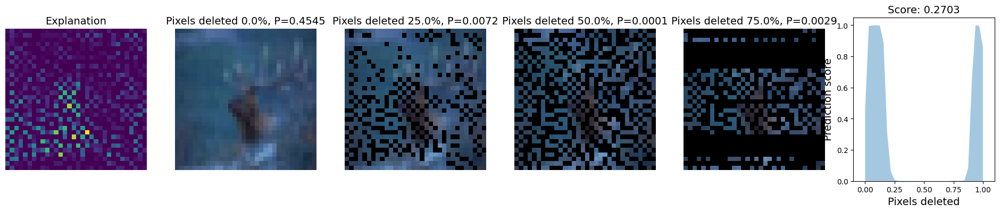

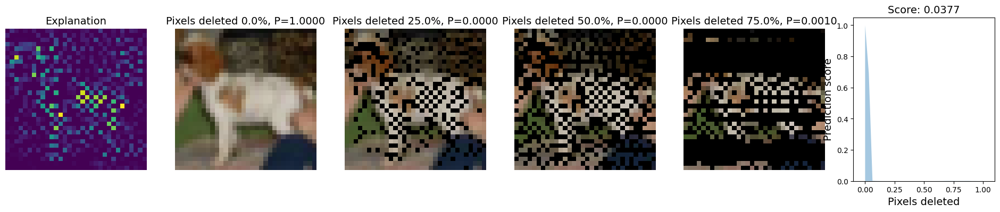

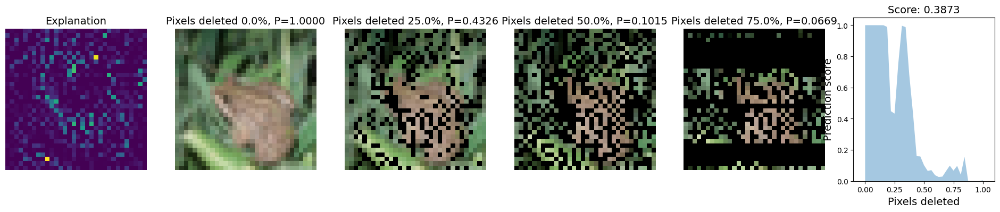

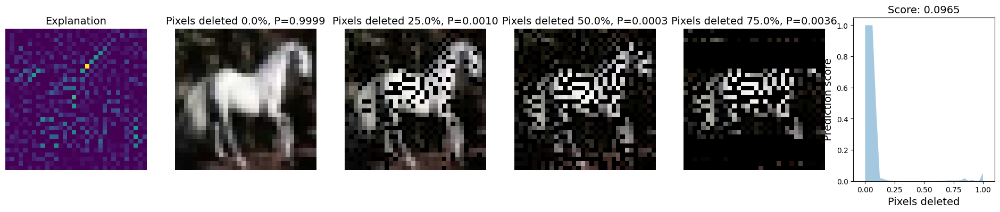

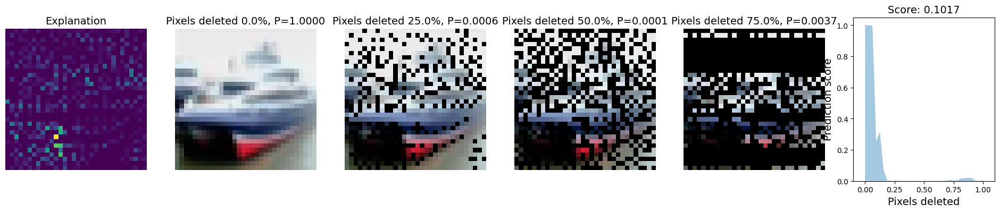

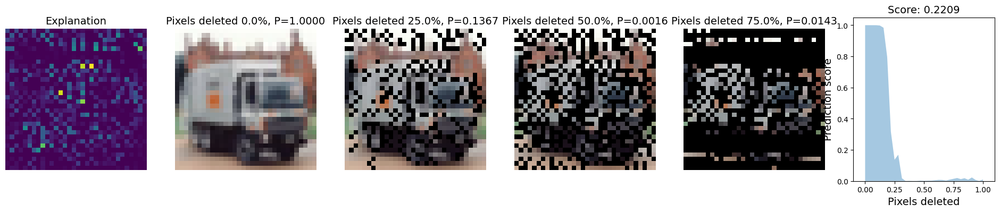

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 571.78it/s]

0
100
200


386it [00:00, 1148.92it/s]

300
400
500


614it [00:00, 945.25it/s]

600
700
800


801it [00:00, 943.11it/s]

900


1000it [00:01, 704.05it/s]


np.float32(0.48421904)

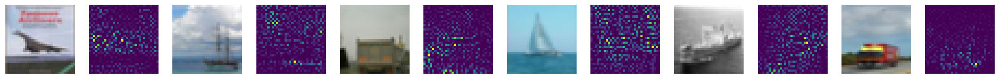

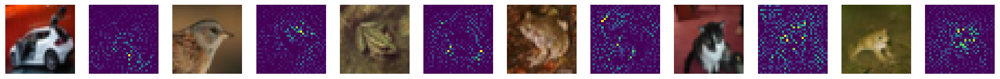

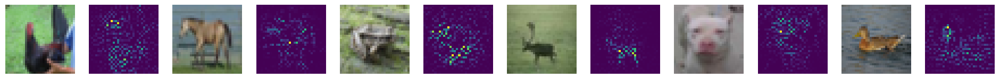

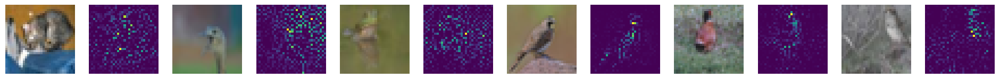

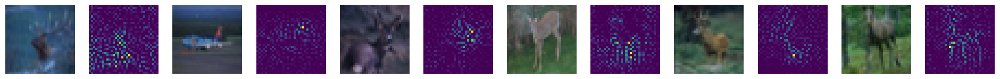

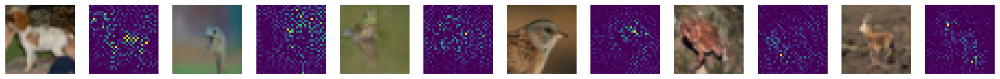

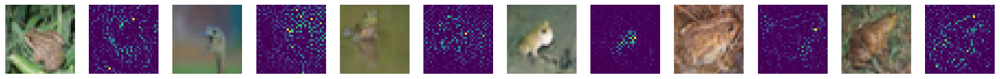

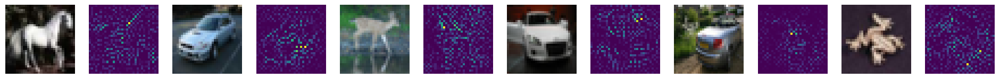

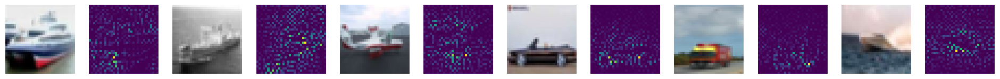

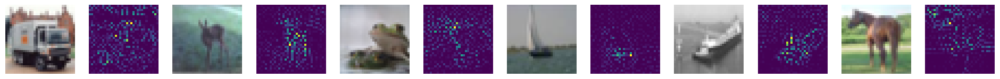

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 0 wrong: 1000 total: 1000


np.float64(100.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

### Densenet121

In [ ]:
model, target_layers = get_model("densenet121", "cifar10")
preprocess_transform = get_preprocess_transform("cifar10")
batch_predict = get_batch_predict(model, preprocess_transform)

Downloading: "https://huggingface.co/edadaltocg/densenet121_cifar10/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/densenet121_cifar10.pth


100%|██████████| 4.19M/4.19M [00:03<00:00, 1.31MB/s]


#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
%%capture
exps, t = expr.timed_batch_explain(imgs)

KeyboardInterrupt: 

In [ ]:
print(f"Mean time for {len(imgs)} explanations: {t}")

Mean time for 1000 explanations: 0.5562859890460968


In [ ]:
%%capture
exps_, t_ = expr.timed_batch_explain(imgs)

KeyboardInterrupt: 

In [ ]:
print(f"Mean time for {len(imgs)} explanations: {t_}")

Mean time for 1000 explanations: 0.5583687143325806


<Figure size 640x480 with 0 Axes>

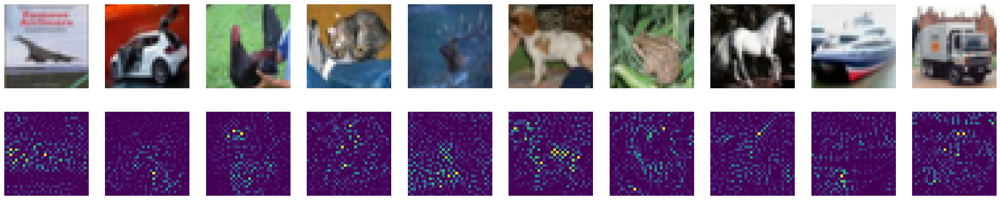

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [15:36,  1.07it/s]


np.float64(0.16977837172785654)

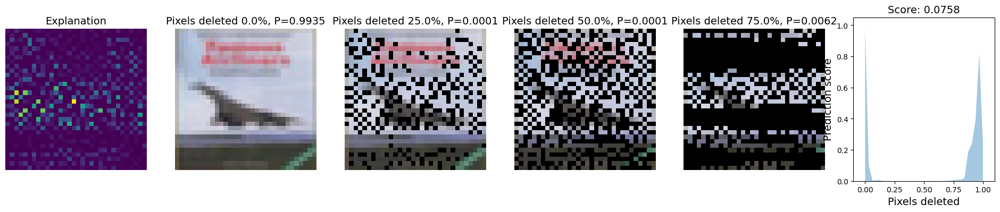

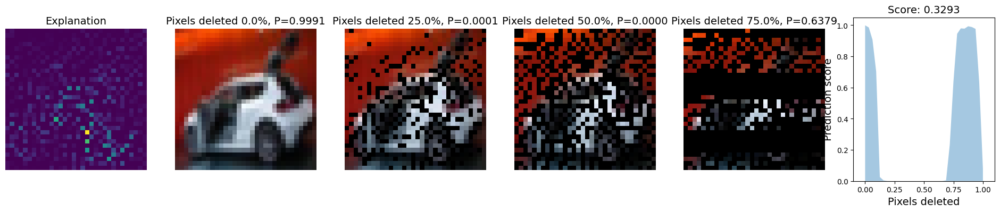

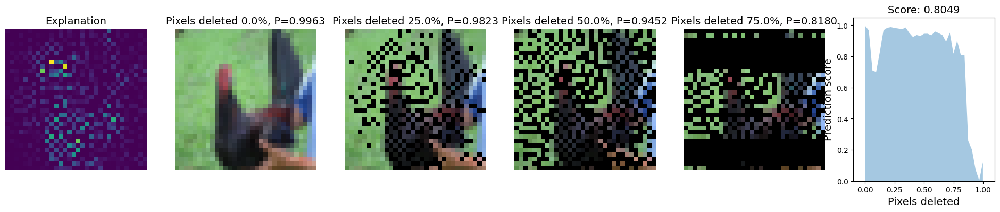

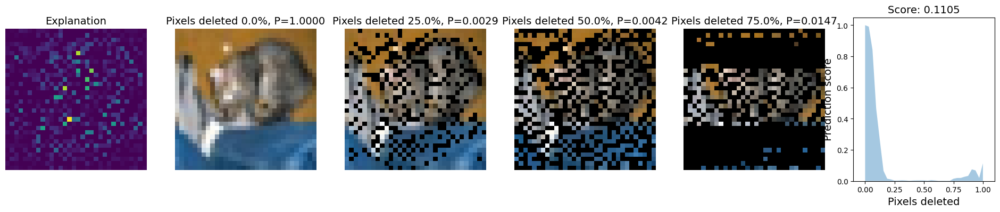

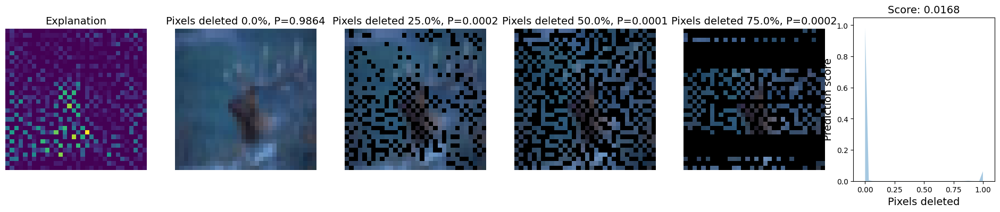

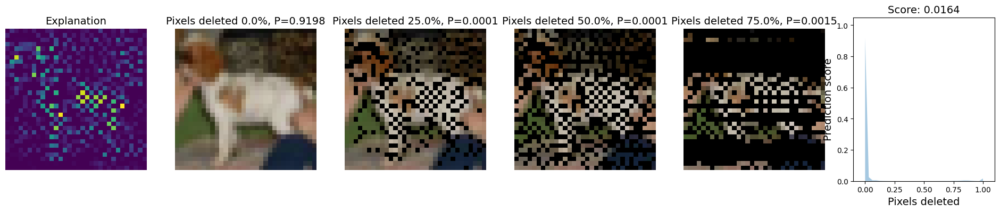

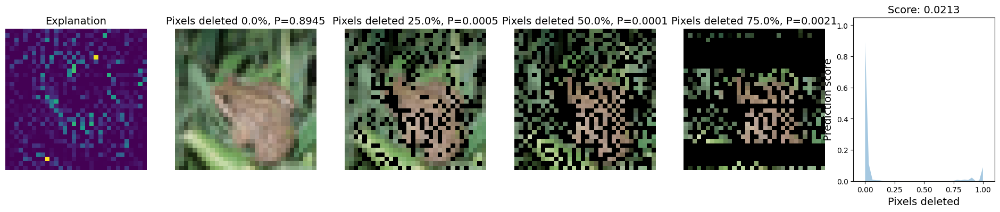

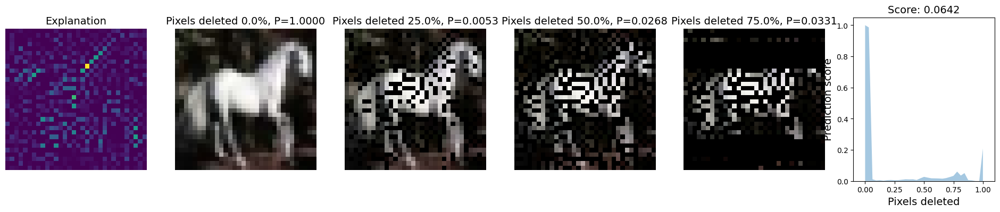

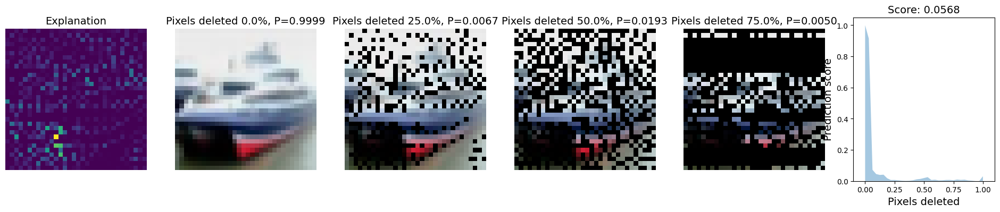

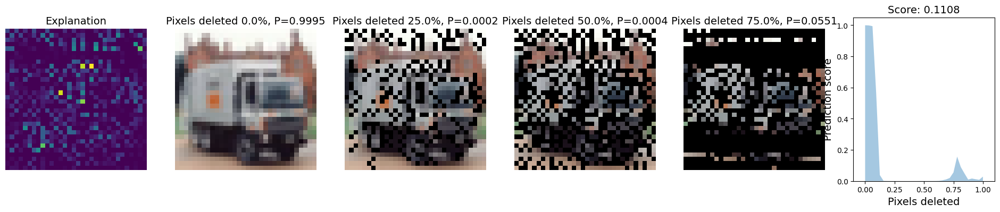

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

1it [00:00,  9.68it/s]

0
100


252it [00:00, 351.03it/s]

200
300
400


623it [00:01, 702.86it/s]

500
600
700


1000it [00:01, 628.43it/s]

800
900


np.float32(0.48421904)

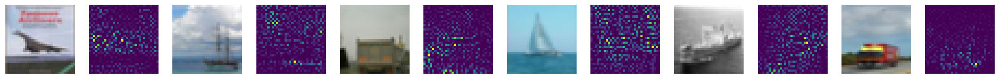

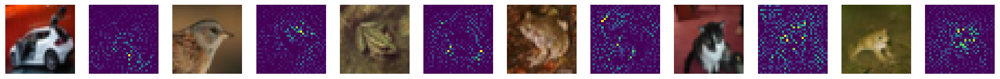

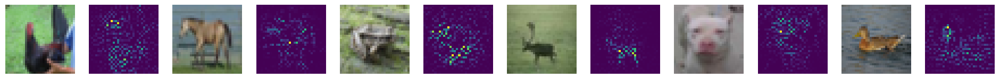

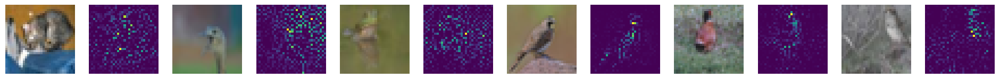

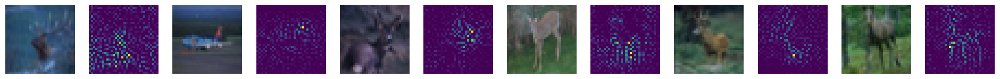

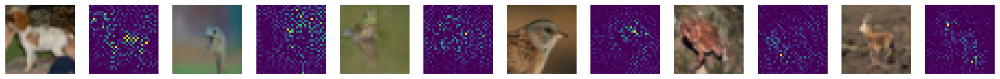

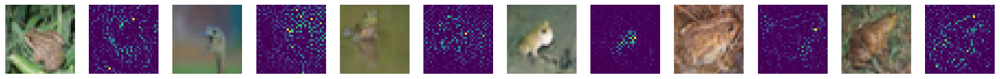

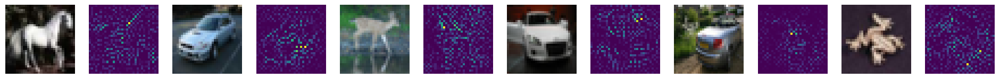

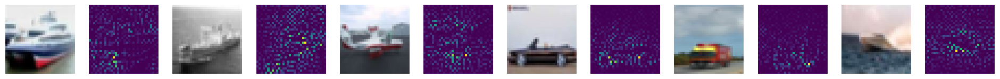

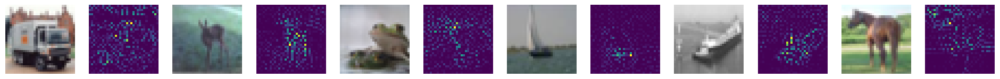

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 0 wrong: 1000 total: 1000


np.float64(100.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [01:32<00:00, 10.86it/s]

Mean time for 1000 explanations: 0.081864089012146
Mean time for 1000 explanations: 0.08128433132171631


<Figure size 640x480 with 0 Axes>

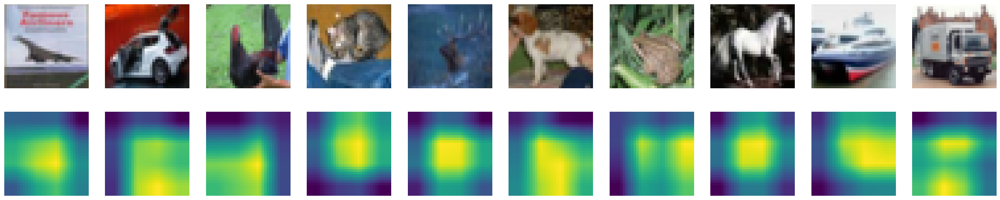

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

568it [09:40,  1.05it/s]

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

## SVHN

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset("svhn")

URLError: <urlopen error [Errno 111] Connection refused>

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=100)
imgs = sample_images
print_every_n = int(len(imgs) / 10)

NameError: name 'dataset' is not defined

### VGG16_BN

In [ ]:
model, target_layers = get_model("vgg16_bn", "svhn")
preprocess_transform = get_preprocess_transform("svhn")
batch_predict = get_batch_predict(model, preprocess_transform)

#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

100%|██████████| 1000/1000 [13:00<00:00,  1.28it/s]

Mean time for 1000 explanations: 0.7788327879905701


In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [12:56<00:00,  1.29it/s]

Mean time for 1000 explanations: 0.7754331424236297


<Figure size 640x480 with 0 Axes>

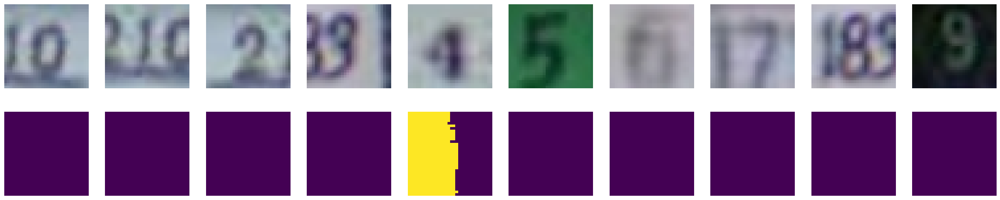

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:24,  6.91it/s]


np.float64(0.521551159007535)

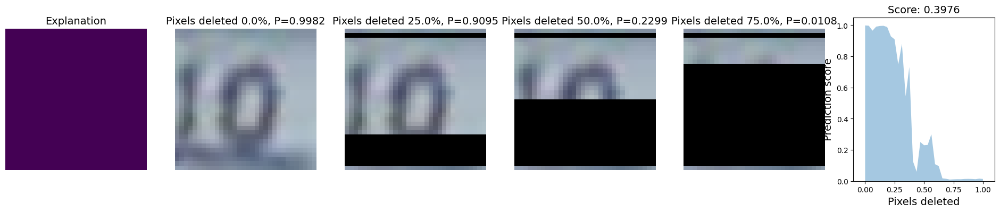

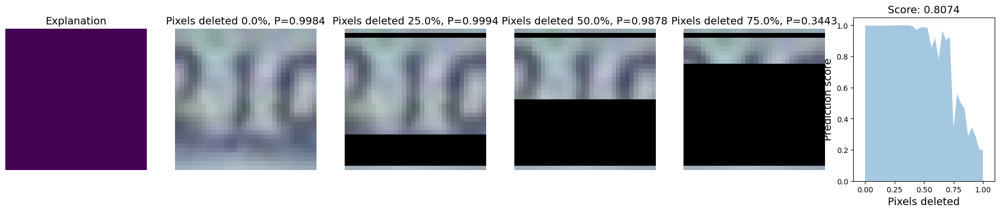

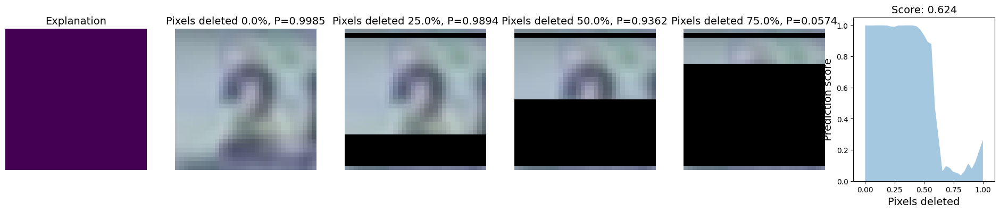

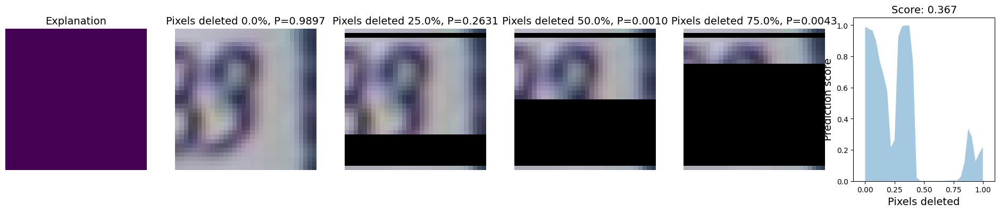

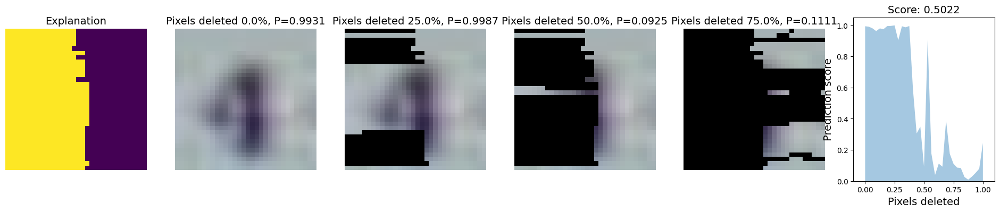

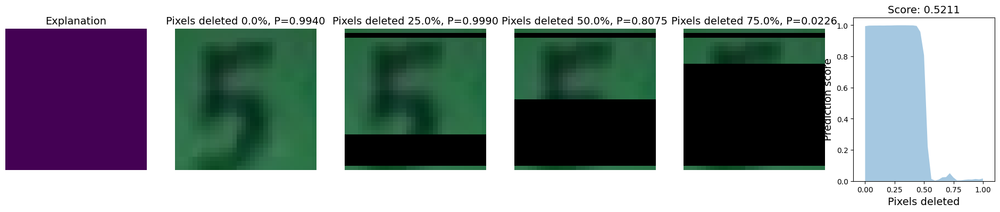

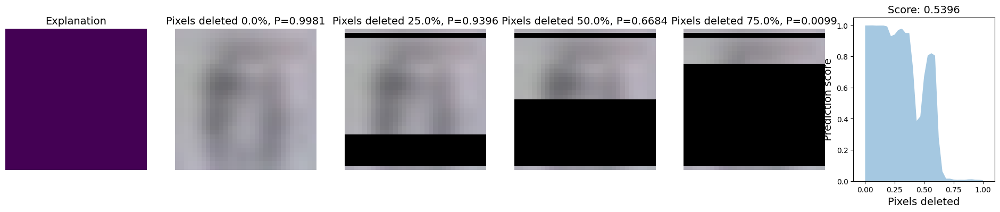

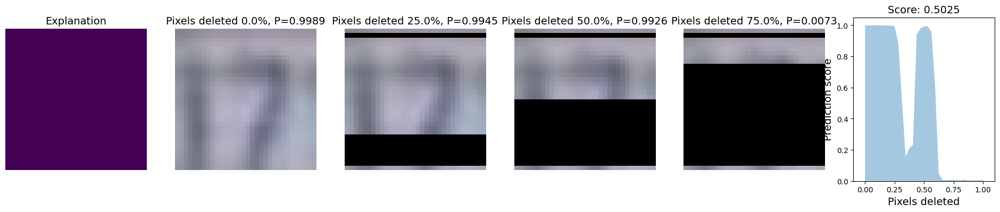

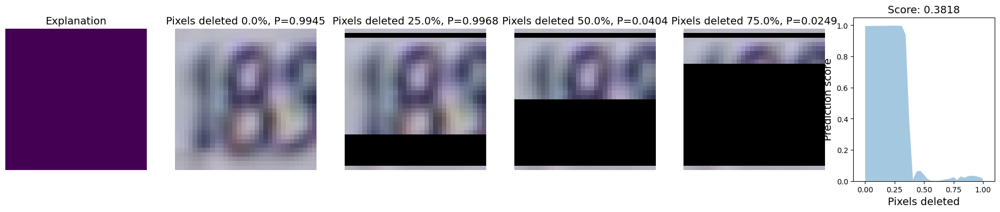

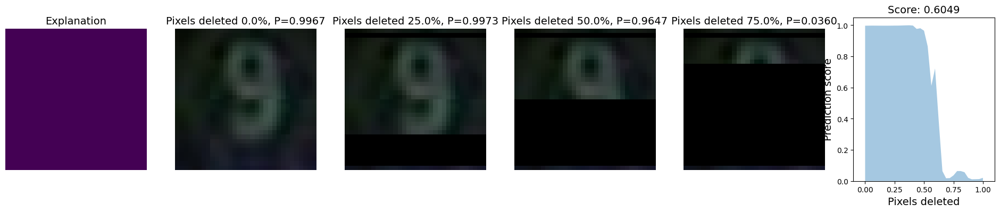

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 585.05it/s]

0
100
200


401it [00:00, 910.30it/s] 

300
400
500


601it [00:00, 962.87it/s]

600
700
800


1000it [00:00, 1064.69it/s]

900


np.float64(0.8240927295717818)

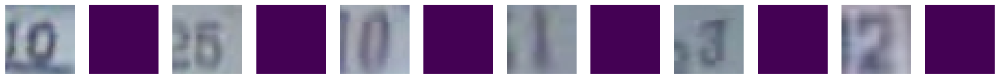

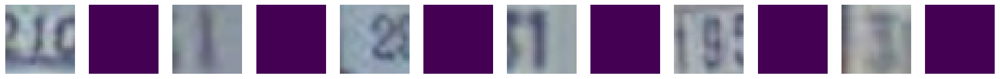

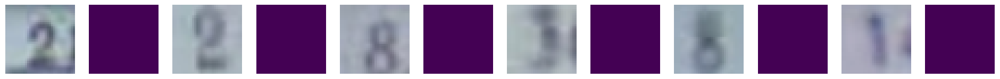

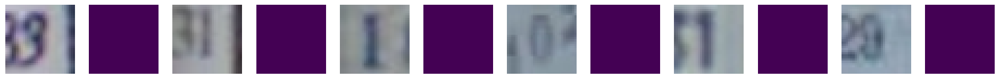

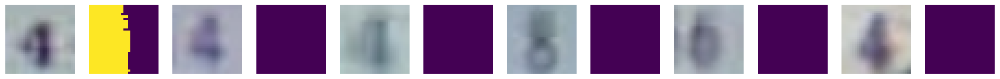

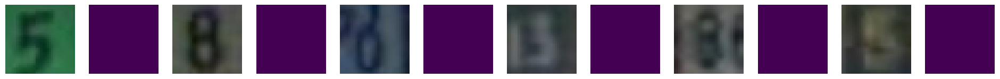

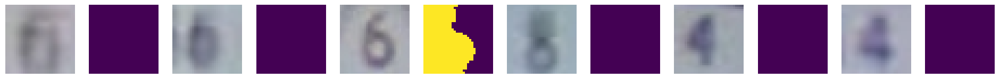

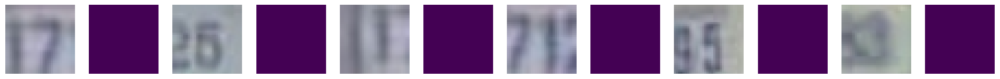

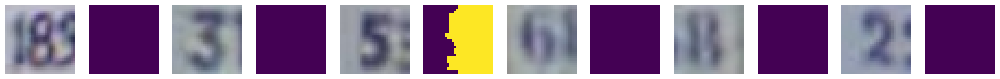

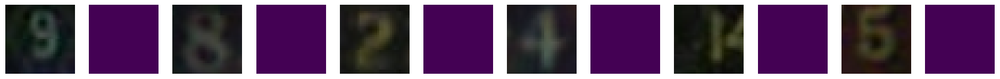

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 999 wrong: 1 total: 1000


np.float64(0.1)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 184438 wrong: 814562 total: 999000


81.53773773773774

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

  1%|          | 7/1000 [00:07<17:02,  1.03s/it]


KeyboardInterrupt: 

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:14<00:00, 69.89it/s]

Mean time for 1000 explanations: 0.01303082275390625
Mean time for 1000 explanations: 0.012461147785186767


<Figure size 640x480 with 0 Axes>

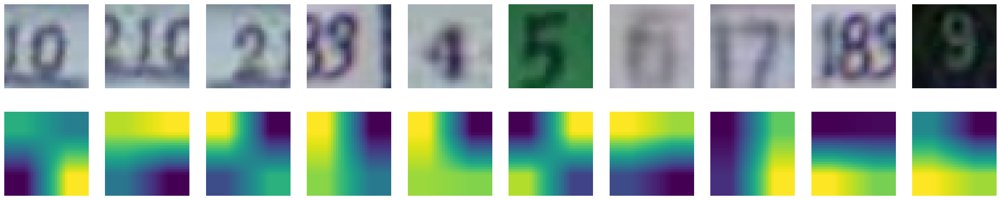

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:47,  5.96it/s]


np.float64(0.47015451605425435)

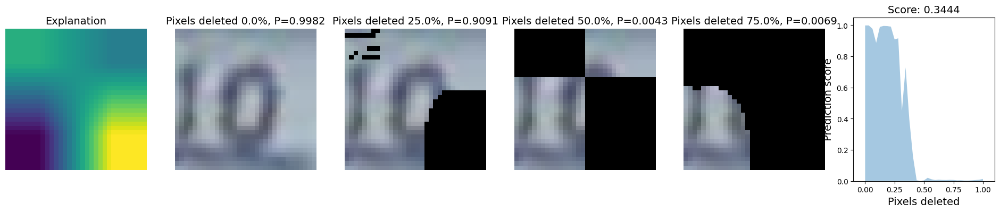

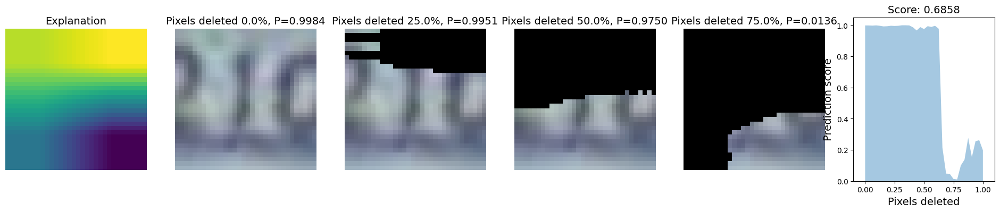

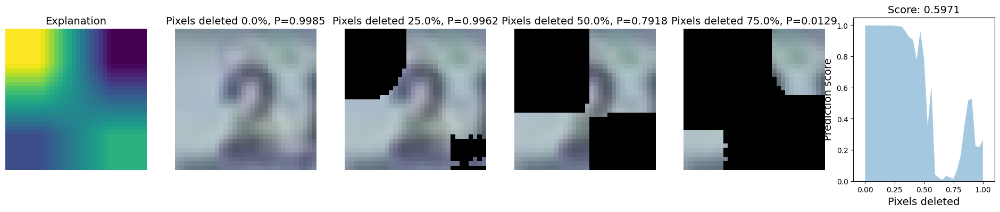

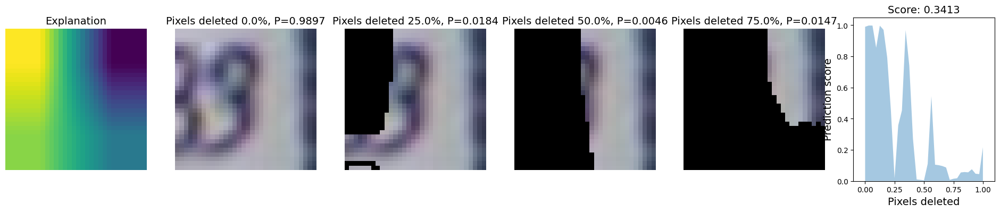

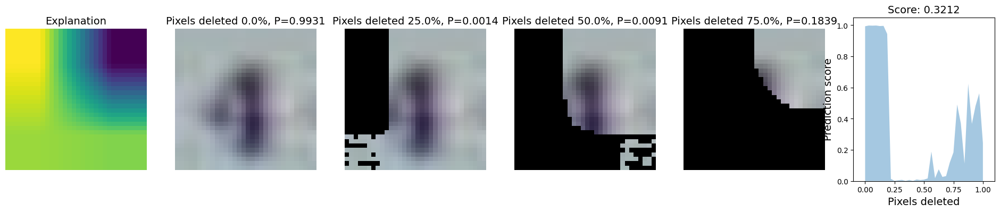

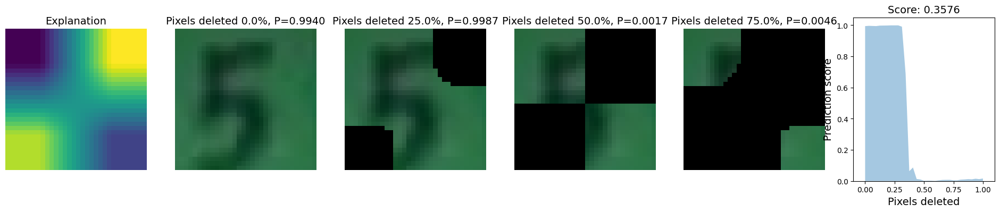

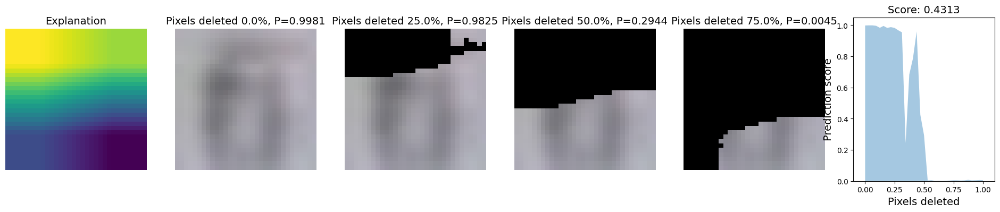

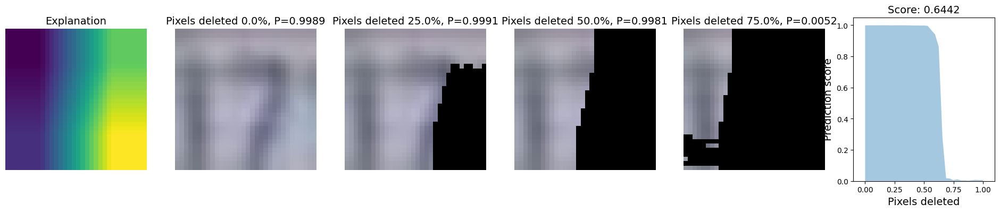

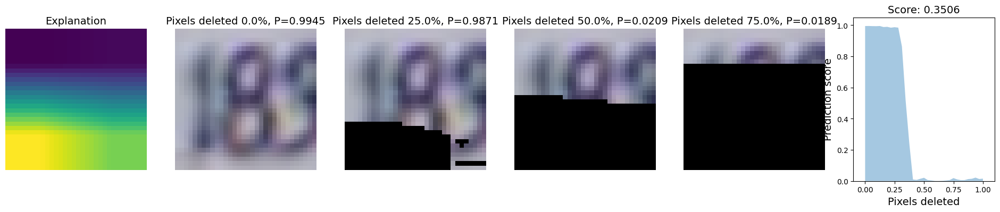

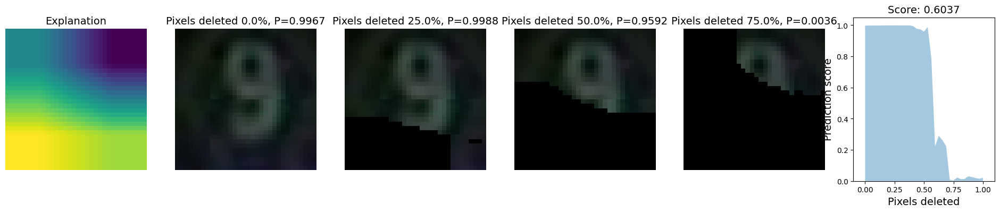

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 558.47it/s]

0
100
200


423it [00:00, 520.67it/s]

300
400
500


783it [00:01, 918.08it/s]

600
700
800


1000it [00:01, 675.45it/s]

900


np.float32(3.031467)

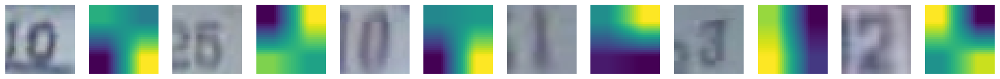

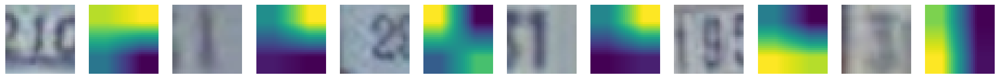

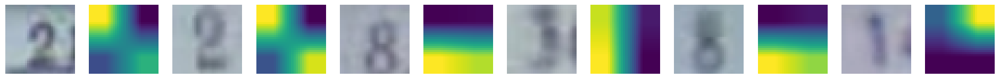

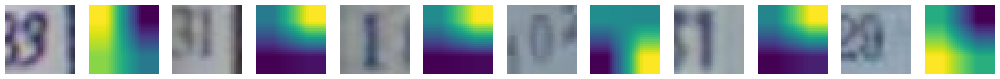

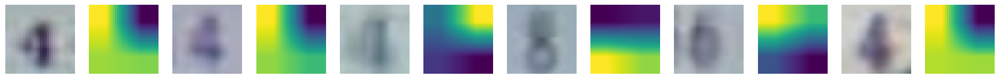

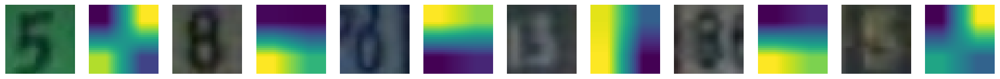

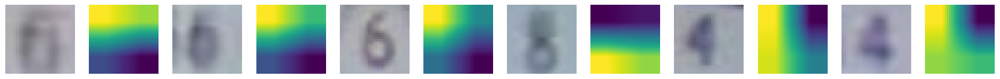

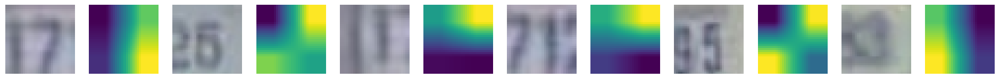

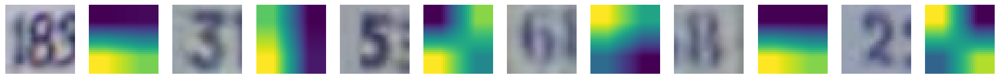

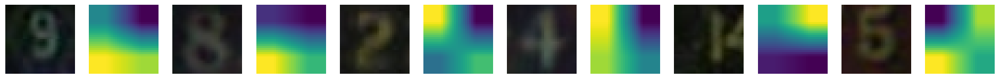

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, [model.features[-2]], preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:14<00:00, 68.80it/s]

Mean time for 1000 explanations: 0.012776201009750366
Mean time for 1000 explanations: 0.012699383974075317


<Figure size 640x480 with 0 Axes>

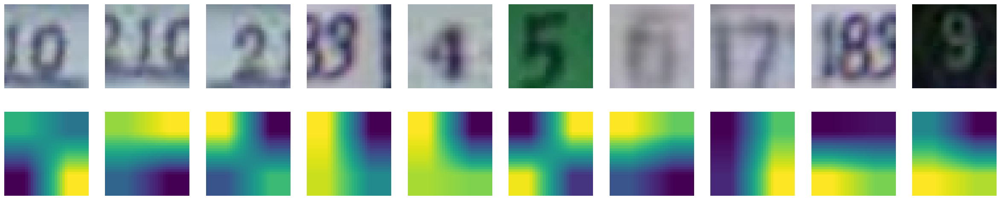

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:49,  5.90it/s]


np.float64(0.4717084789951188)

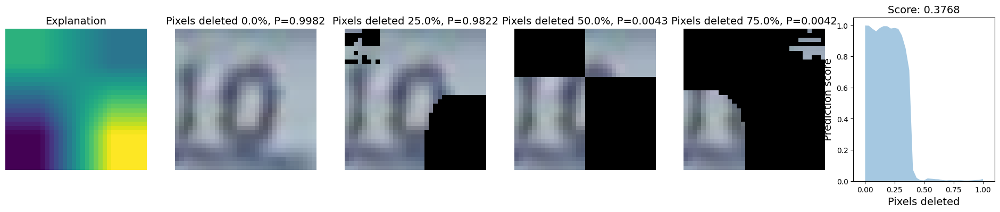

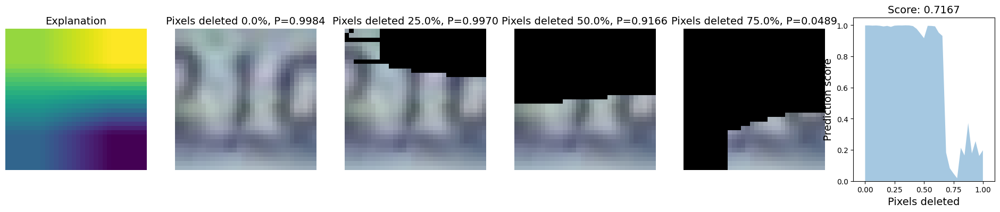

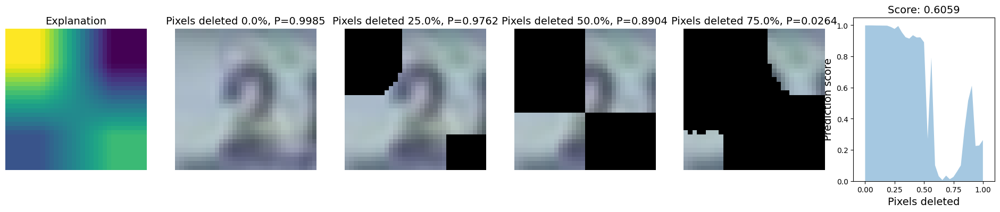

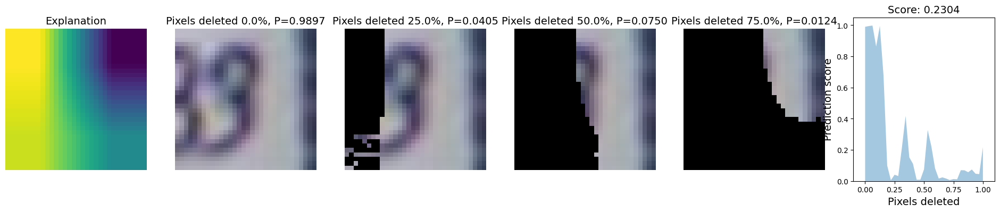

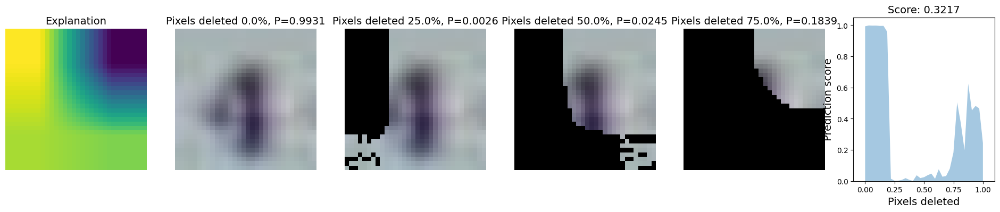

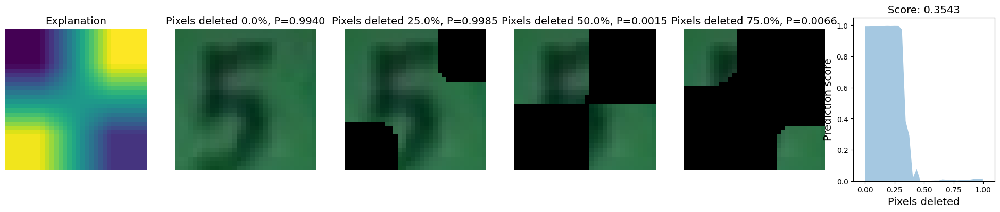

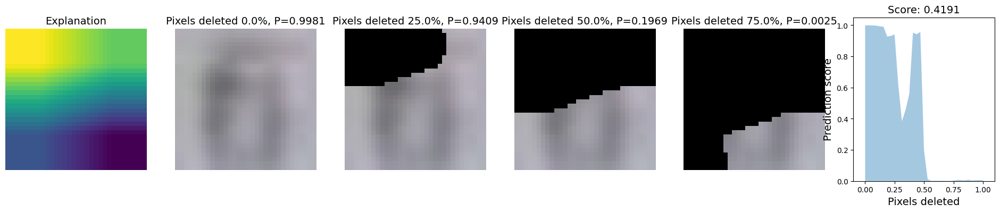

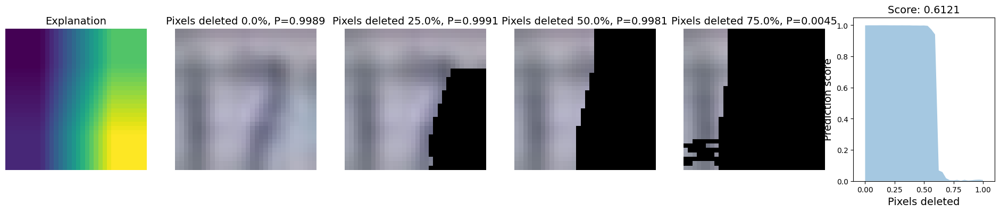

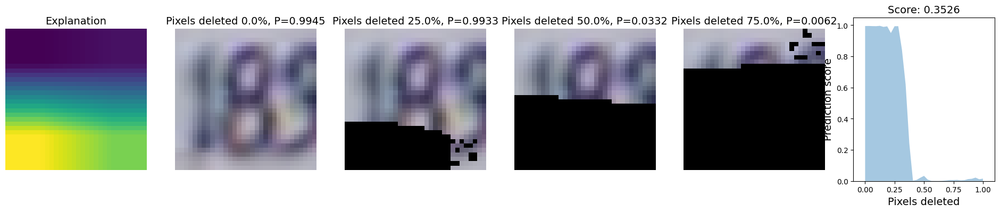

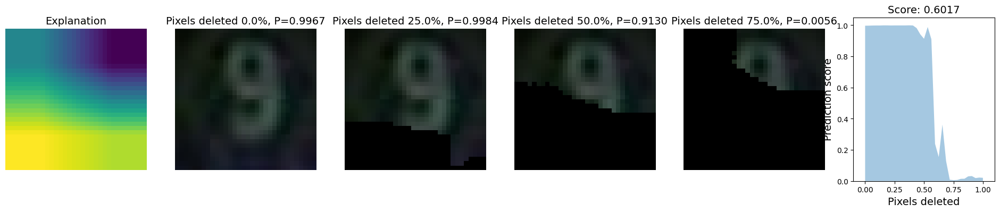

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 559.32it/s]

0
100
200


485it [00:00, 1109.56it/s]

300
400
500
600


776it [00:01, 590.40it/s]

700
800
900


1000it [00:01, 700.05it/s]


np.float32(3.012173)

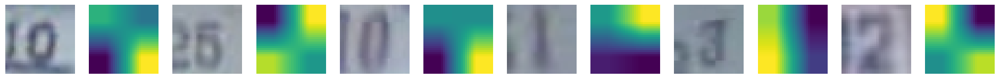

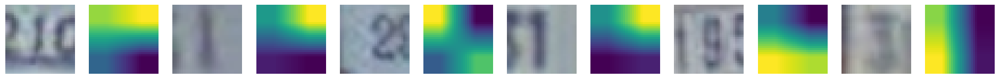

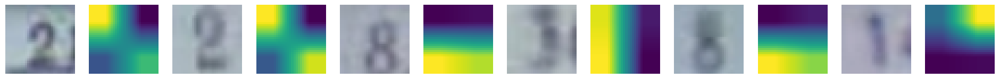

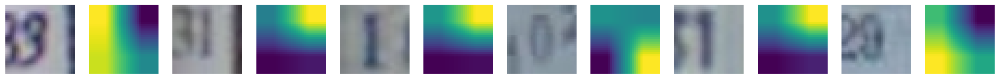

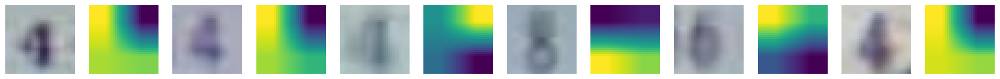

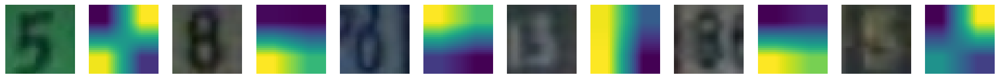

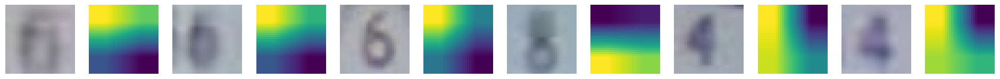

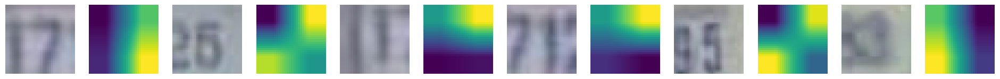

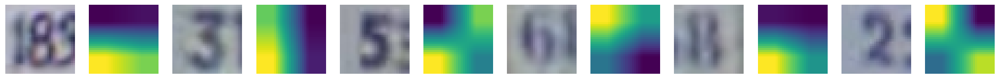

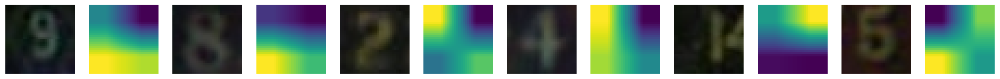

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:30<00:00, 32.99it/s]

Mean time for 1000 explanations: 0.023150654554367066
Mean time for 1000 explanations: 0.022988142013549803


<Figure size 640x480 with 0 Axes>

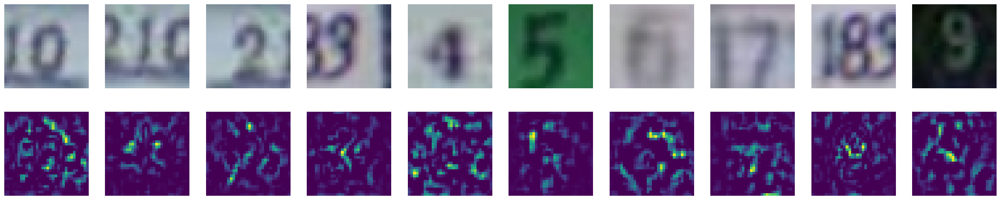

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:36,  6.39it/s]


np.float64(0.27639293988982583)

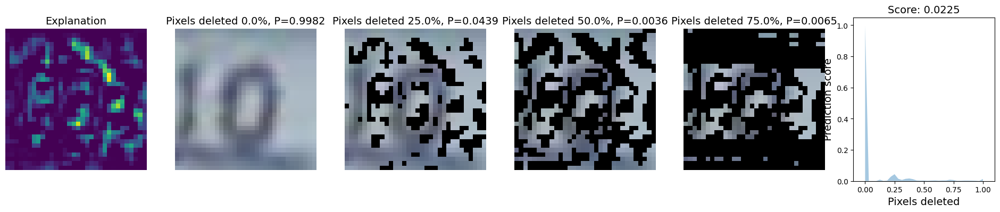

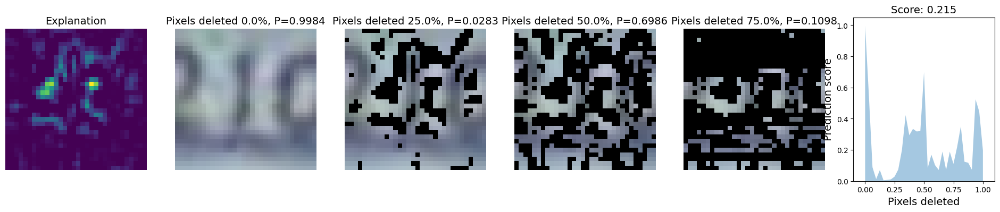

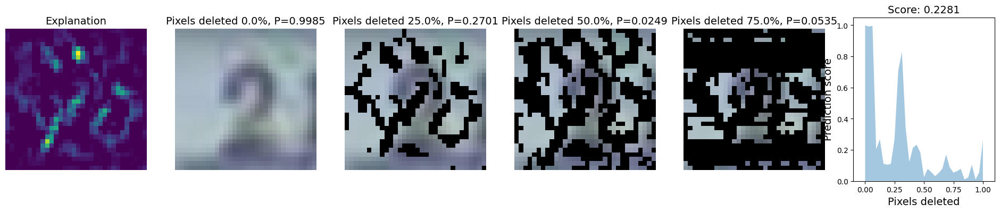

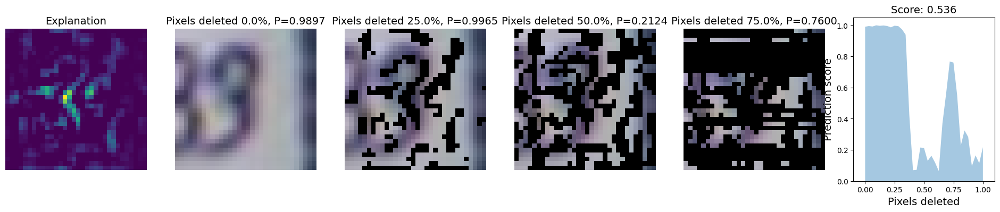

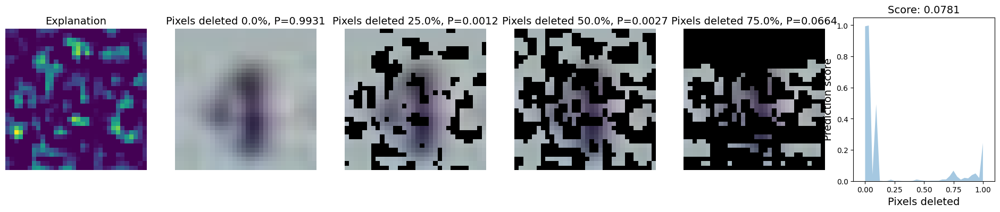

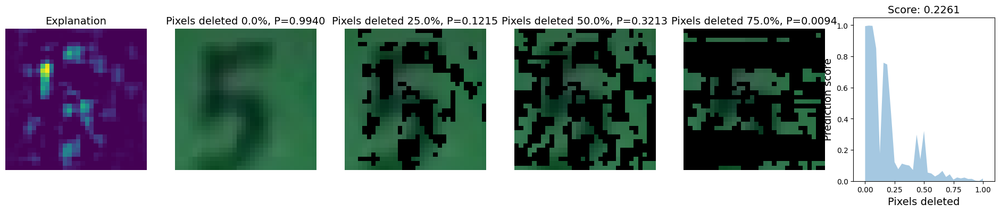

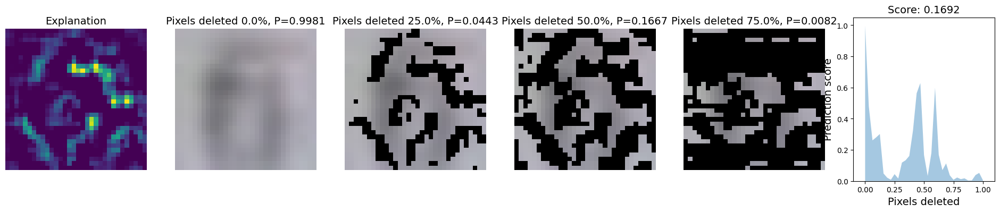

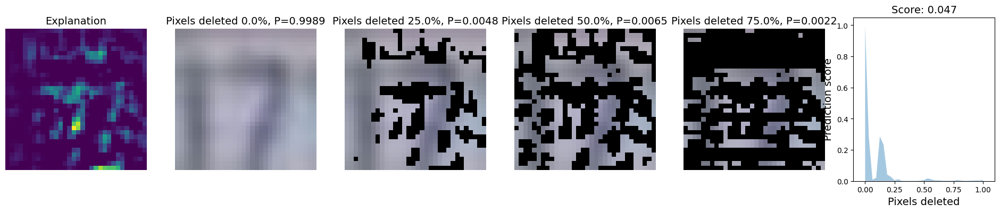

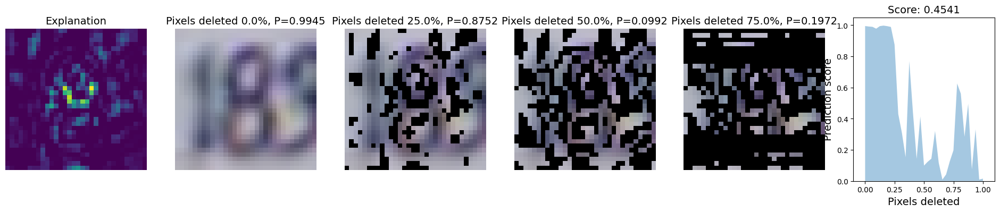

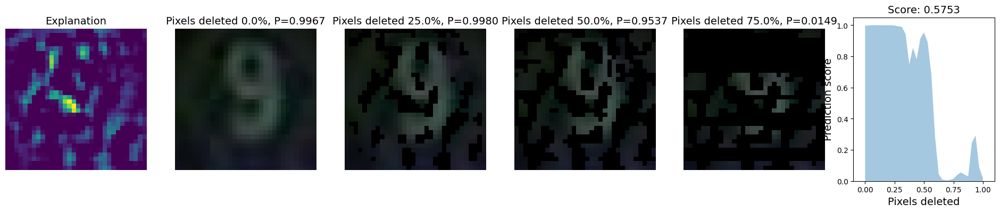

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 548.51it/s]

0
100
200


380it [00:00, 1136.46it/s]

300
400
500


609it [00:00, 938.12it/s]

600
700
800


1000it [00:00, 1048.36it/s]

900


np.float32(1.0607382)

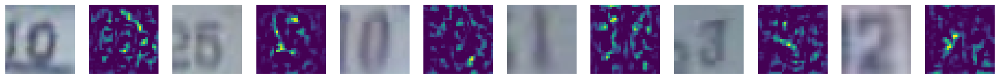

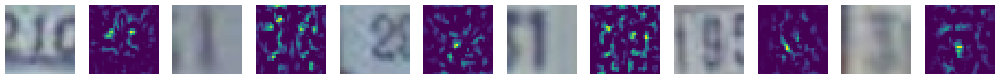

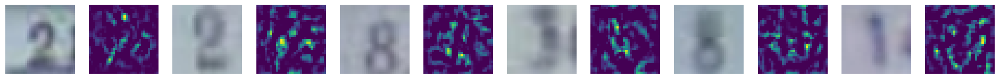

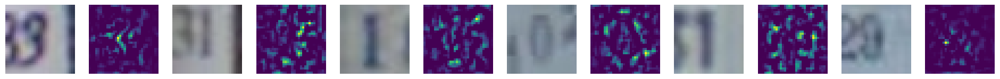

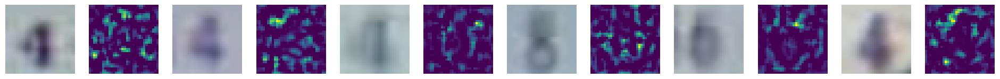

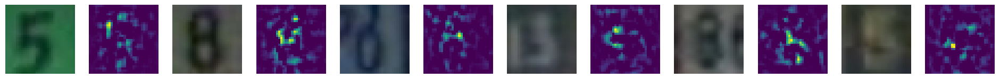

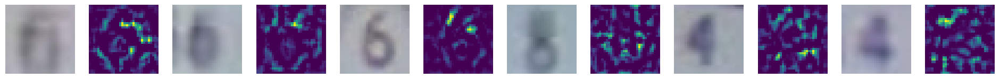

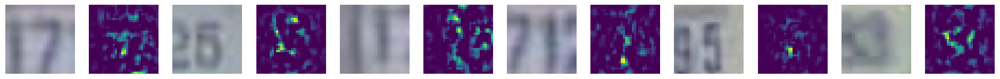

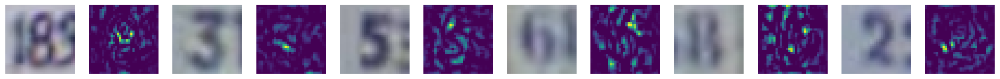

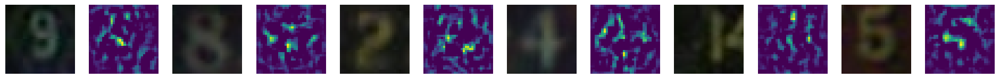

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [02:06<00:00,  7.92it/s]

Mean time for 1000 explanations: 0.11786600685119629
Mean time for 1000 explanations: 0.11741623544692993


<Figure size 640x480 with 0 Axes>

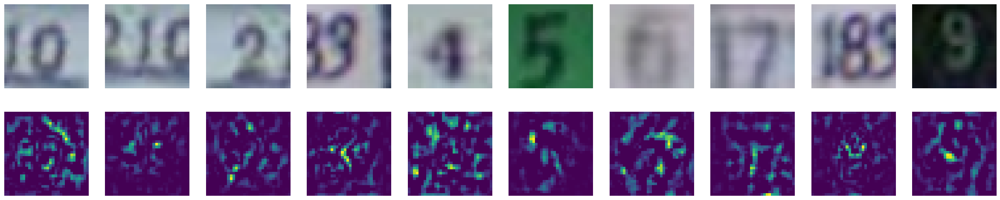

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:25,  6.86it/s]


np.float64(0.28629835206125176)

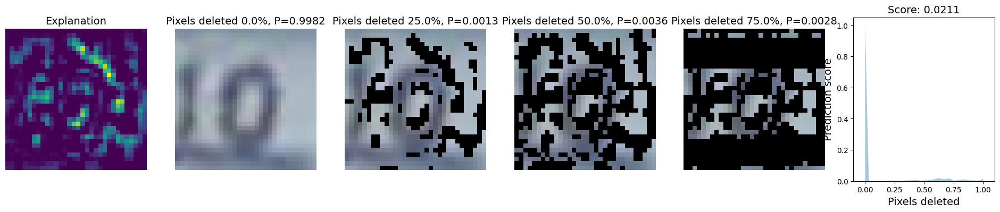

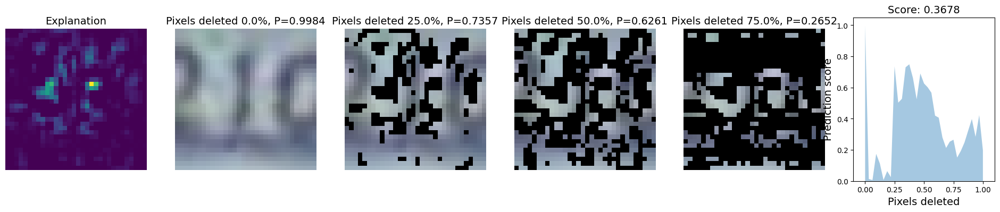

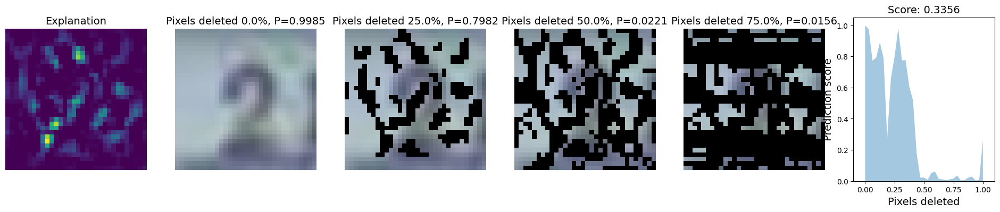

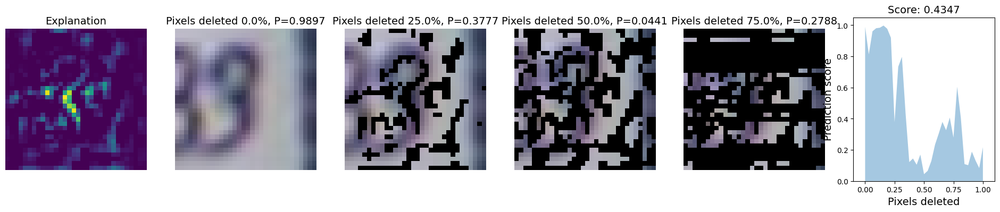

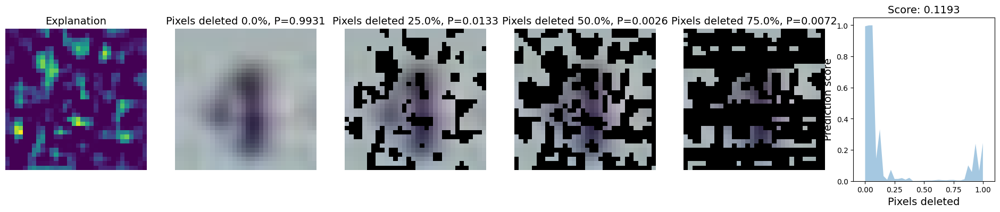

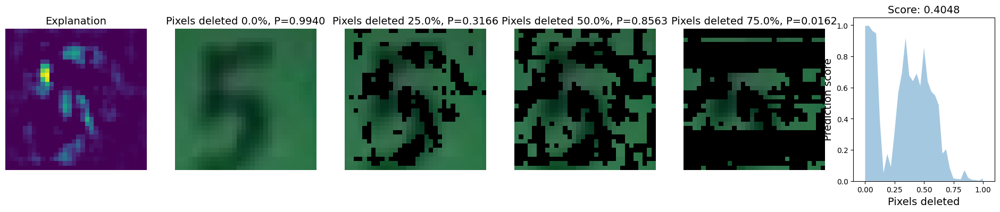

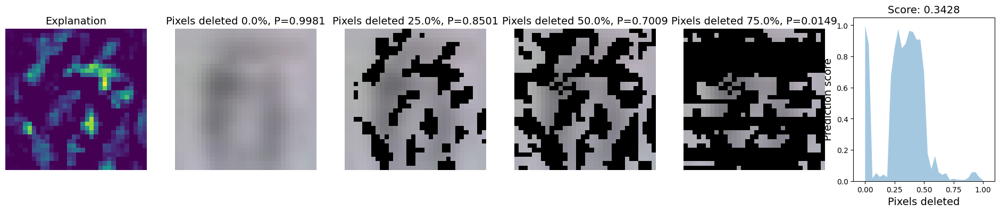

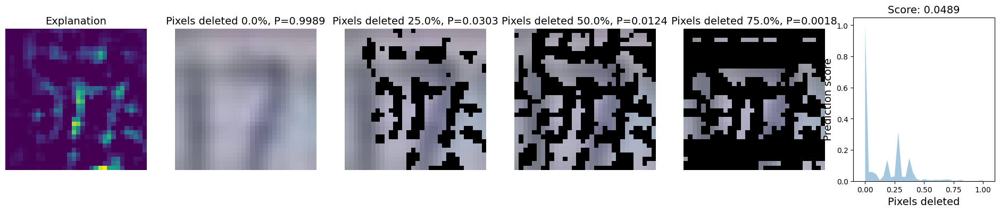

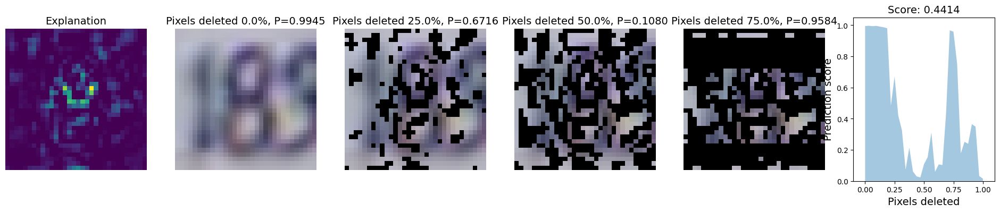

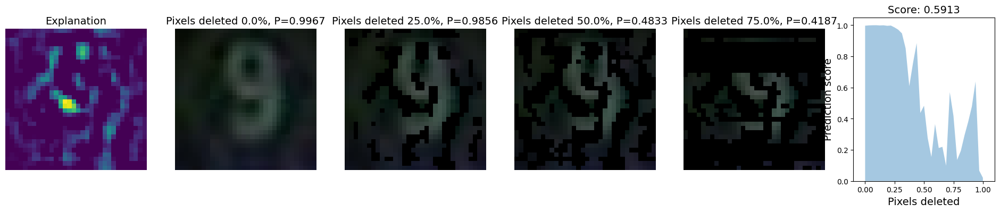

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 544.93it/s]

0
100
200


320it [00:00, 886.56it/s]

300
400


537it [00:01, 465.31it/s]

500
600
700


1000it [00:01, 663.13it/s]

800
900


np.float32(1.0535938)

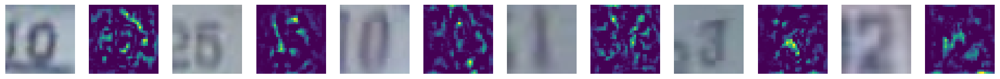

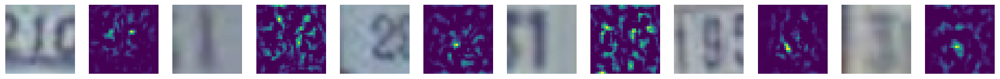

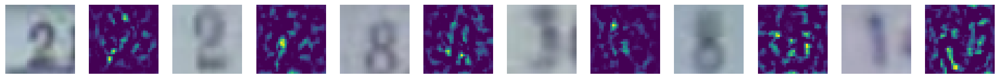

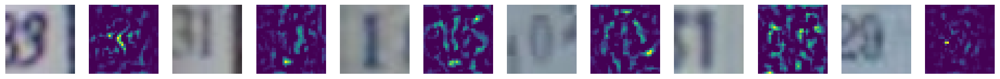

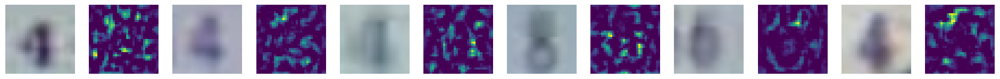

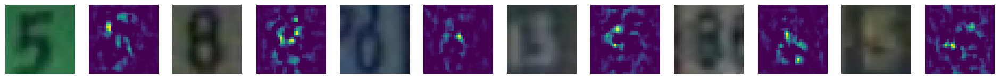

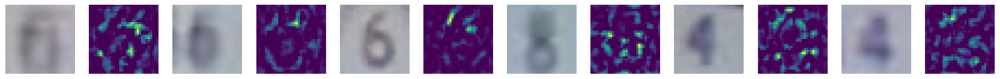

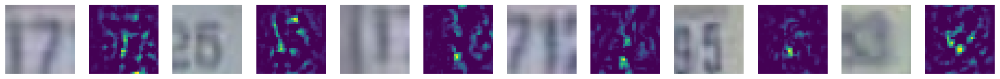

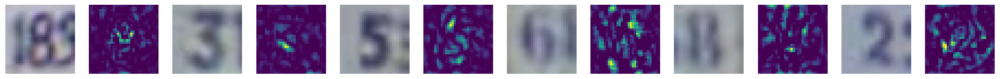

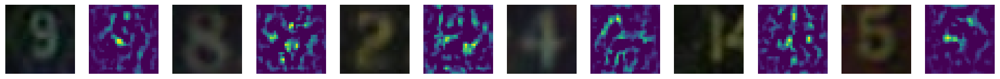

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 0 wrong: 1000 total: 1000


np.float64(100.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

### Resnet50

In [ ]:
model, target_layers = get_model("resnet50", "svhn")
preprocess_transform = get_preprocess_transform("svhn")
batch_predict = get_batch_predict(model, preprocess_transform)

Downloading: "https://huggingface.co/edadaltocg/resnet50_svhn/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/resnet50_svhn.pth


100%|██████████| 90.0M/90.0M [00:06<00:00, 14.3MB/s]


#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

100%|██████████| 1000/1000 [02:07<00:00,  7.87it/s]

Mean time for 1000 explanations: 0.11783615207672118


In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [02:06<00:00,  7.92it/s]

Mean time for 1000 explanations: 0.11733010053634643


<Figure size 640x480 with 0 Axes>

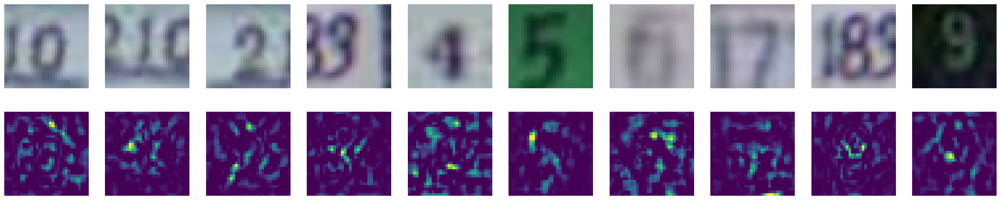

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:26,  6.84it/s]


np.float64(0.27754691479113375)

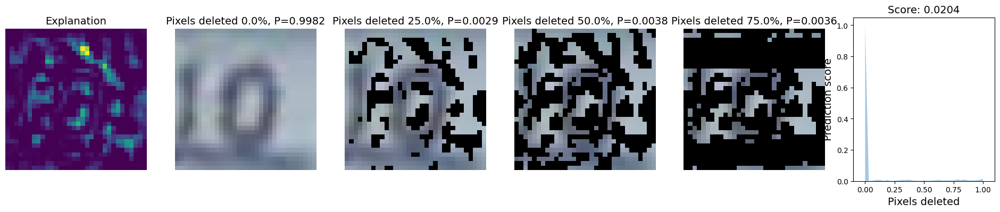

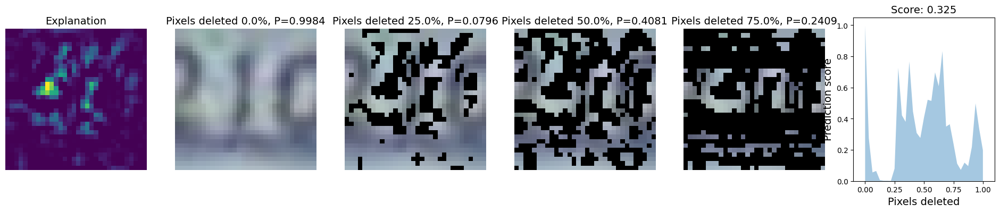

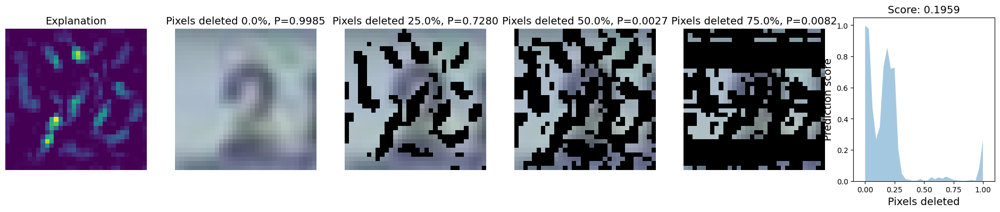

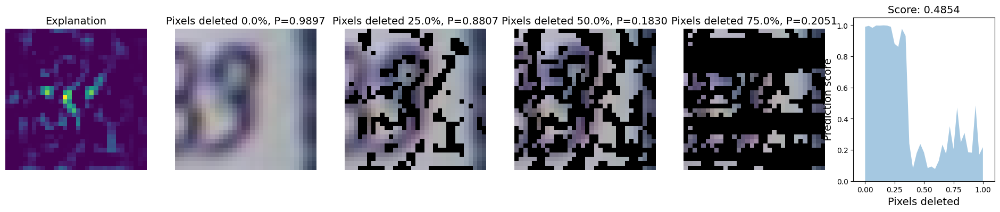

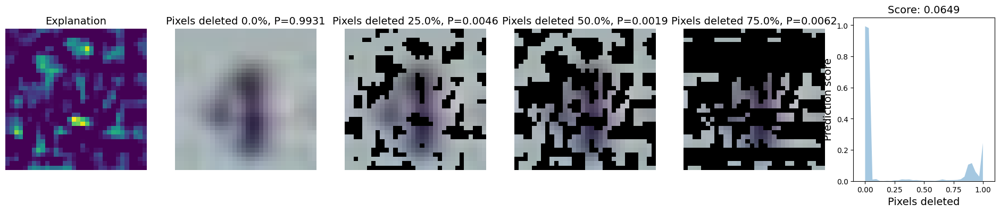

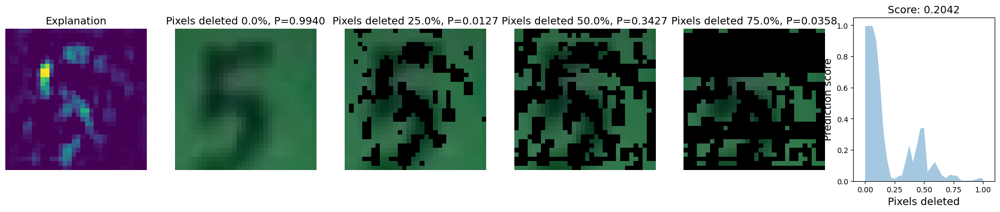

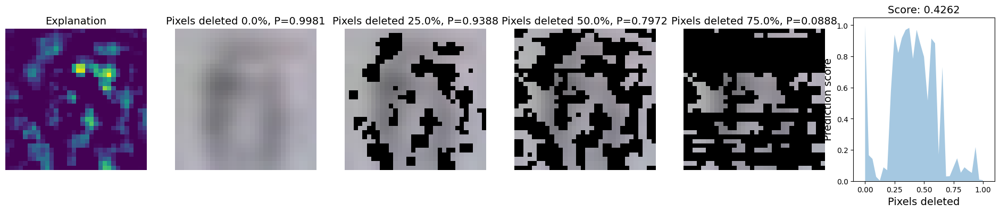

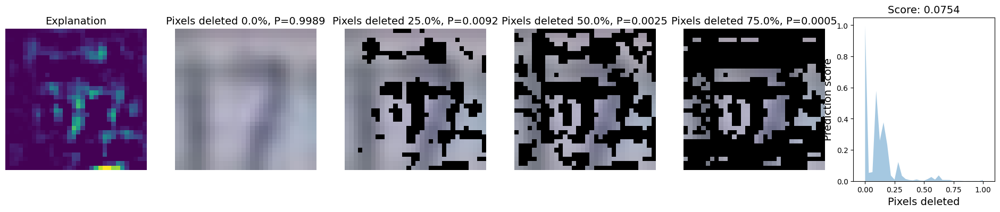

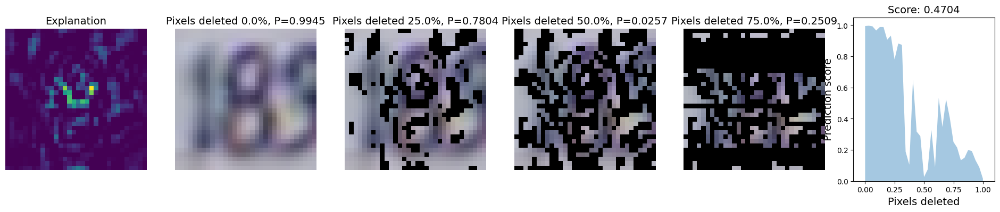

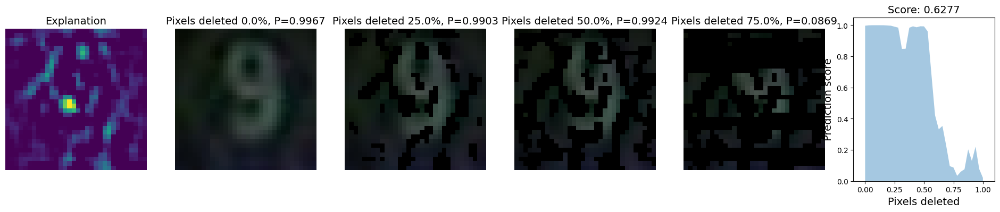

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 592.90it/s]

0
100
200


377it [00:00, 1093.54it/s]

300
400
500


687it [00:00, 1168.51it/s]

600
700
800


1000it [00:00, 1052.75it/s]

900


np.float32(1.0451102)

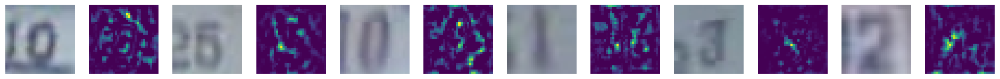

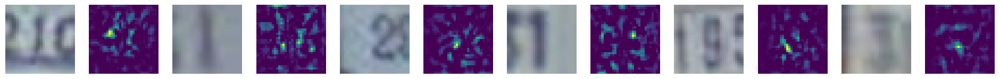

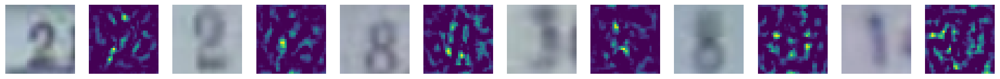

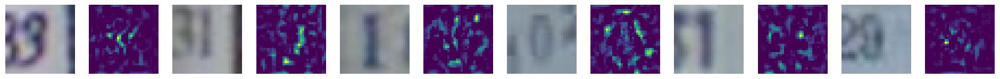

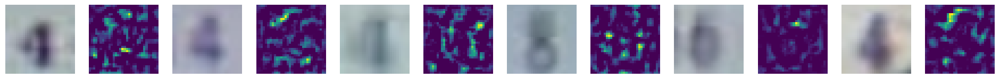

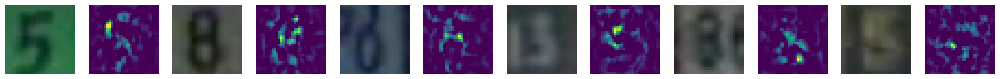

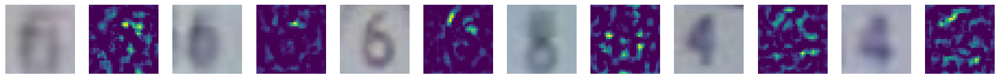

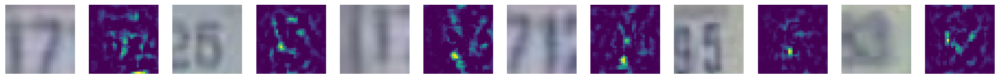

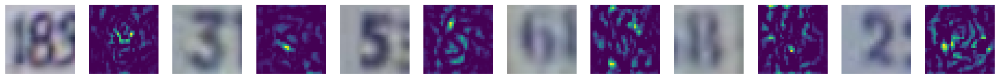

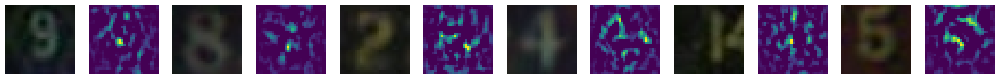

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 0 wrong: 1000 total: 1000


np.float64(100.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [08:18<00:00,  2.01it/s]

Mean time for 1000 explanations: 0.4745315344333649
Mean time for 1000 explanations: 0.471724130153656


<Figure size 640x480 with 0 Axes>

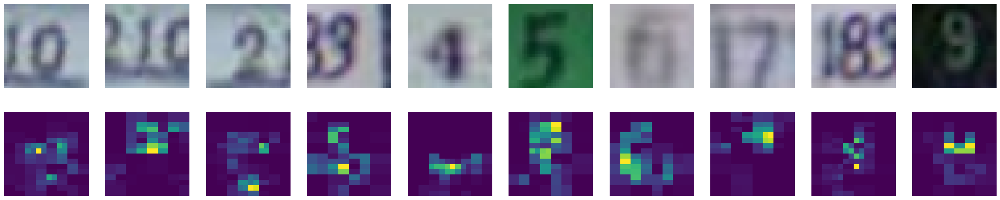

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:25,  6.90it/s]


np.float64(0.20600191599320583)

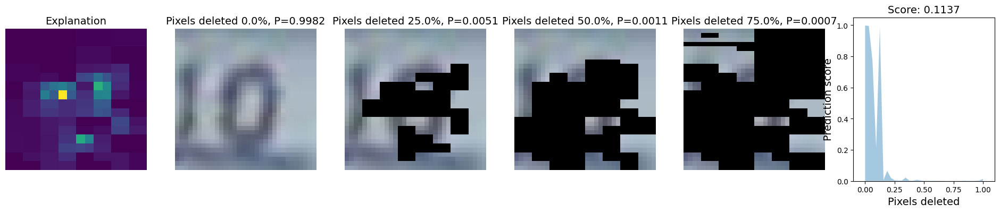

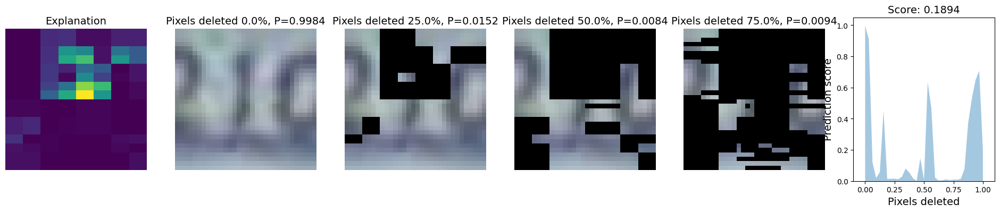

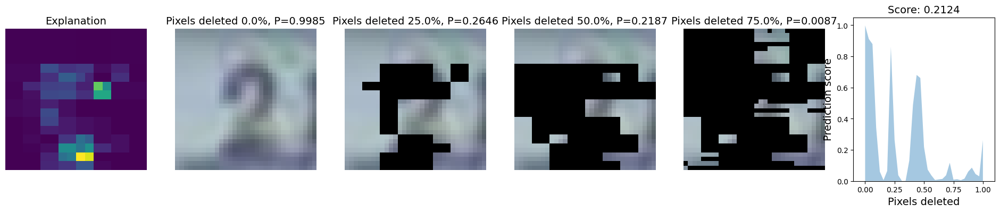

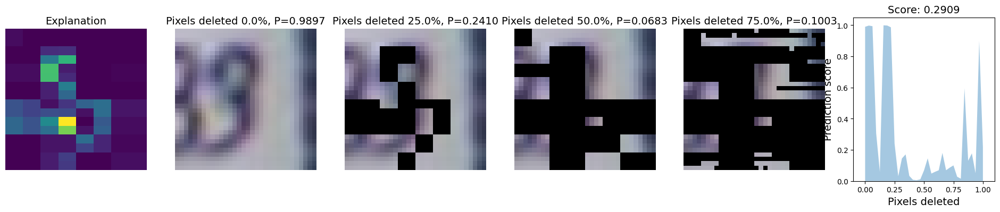

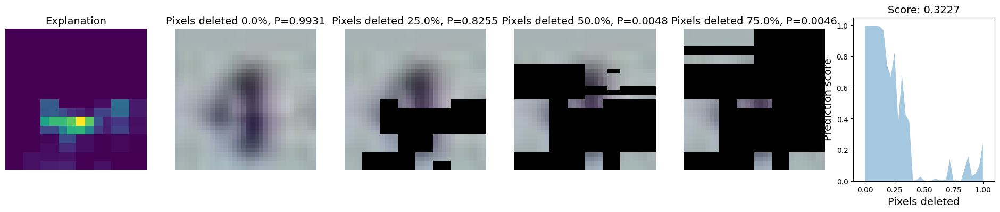

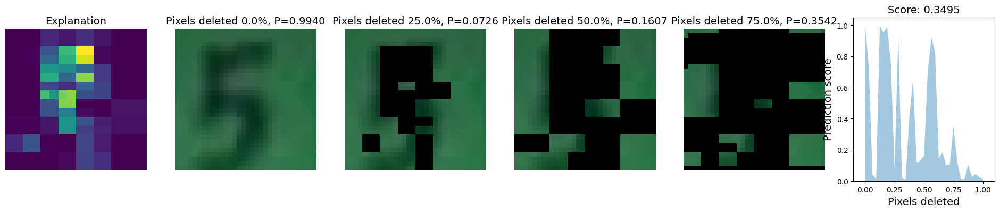

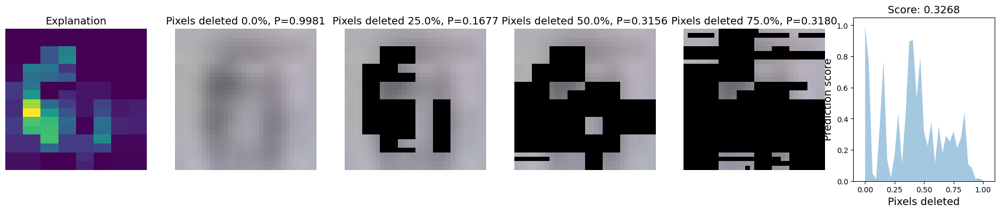

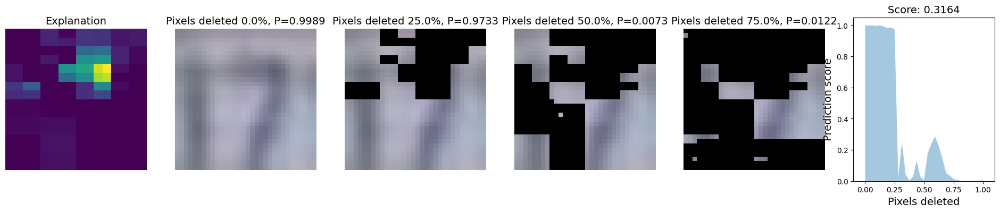

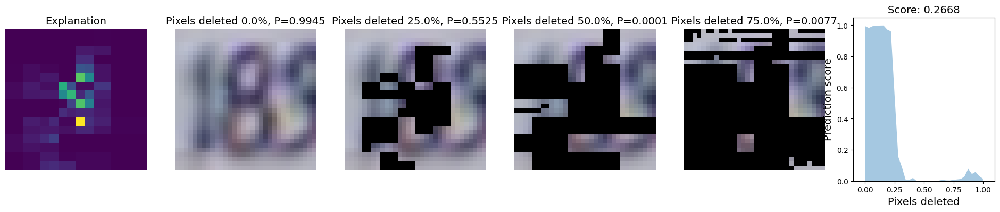

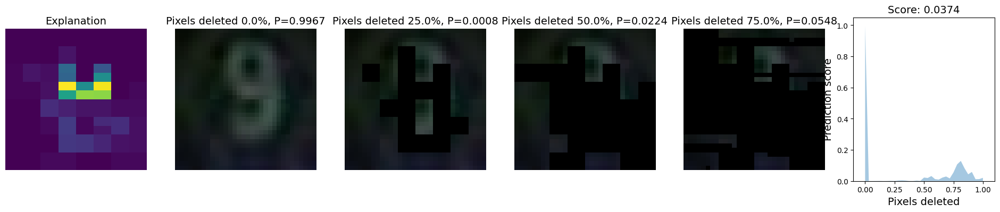

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

164it [00:00, 845.68it/s]

0
100
200


258it [00:00, 888.46it/s]

300
400


586it [00:01, 552.59it/s]

500
600
700


1000it [00:01, 683.68it/s]

800
900


np.float64(1.2638750800378649)

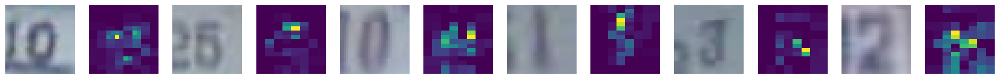

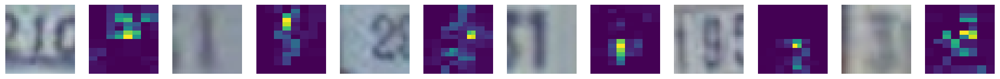

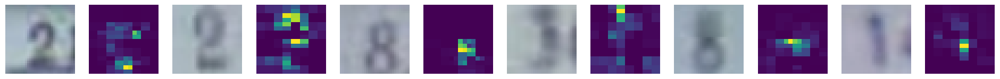

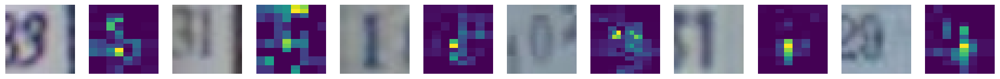

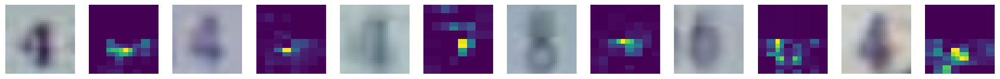

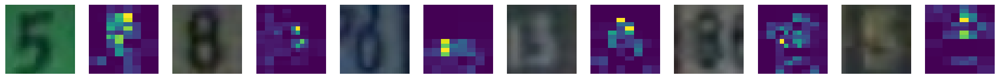

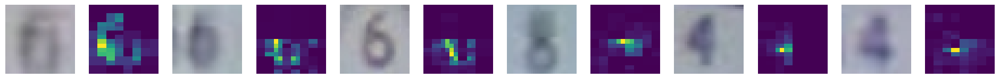

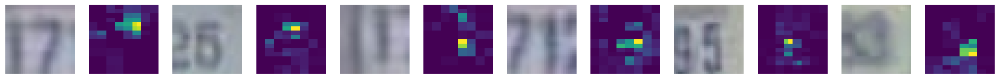

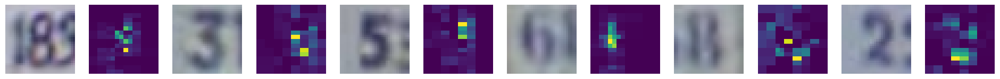

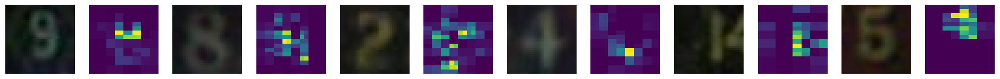

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

100%|██████████| 1000/1000 [00:14<00:00, 70.04it/s]

Mean time for 1000 explanations: 0.01240960955619812
Mean time for 1000 explanations: 0.012463831424713134


<Figure size 640x480 with 0 Axes>

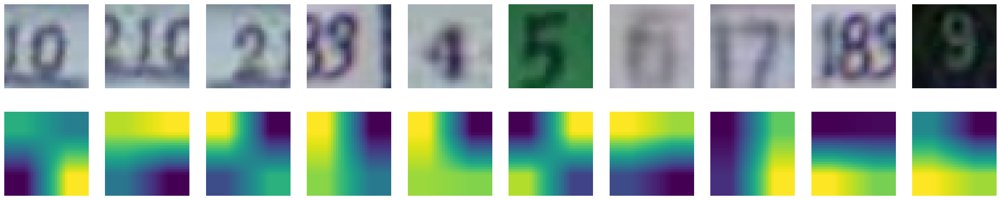

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

1000it [02:47,  5.97it/s]


np.float64(0.47015451605425435)

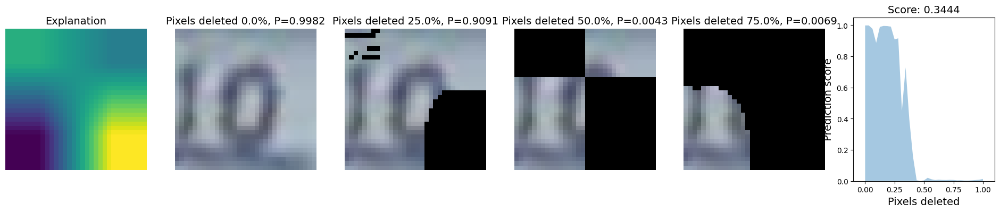

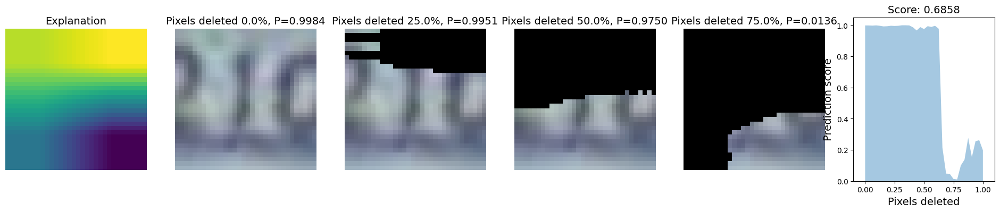

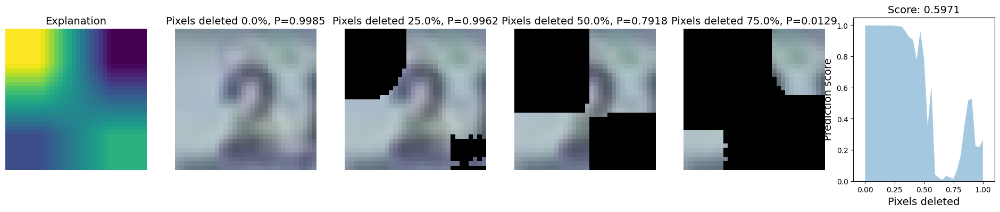

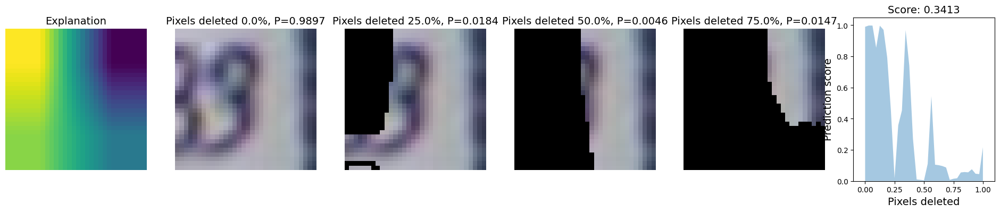

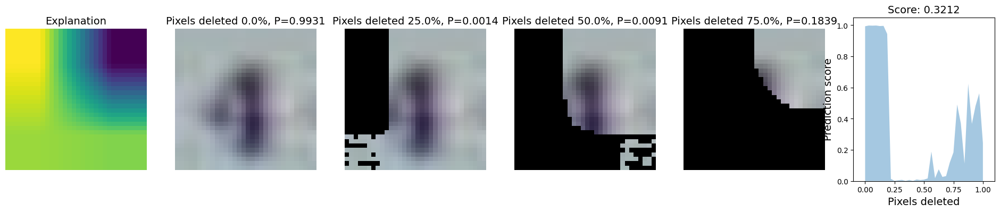

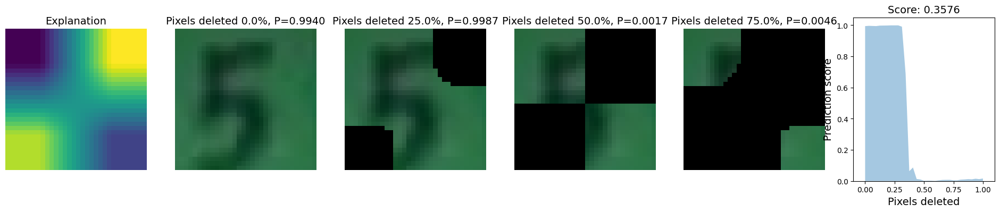

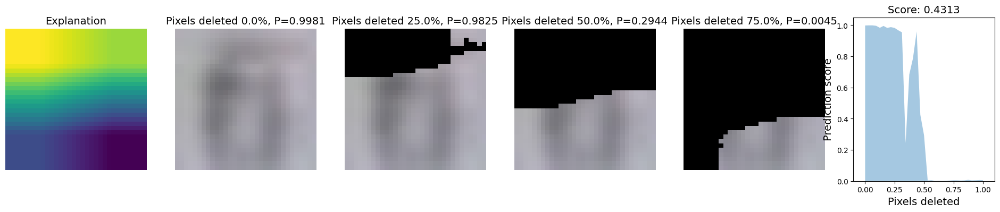

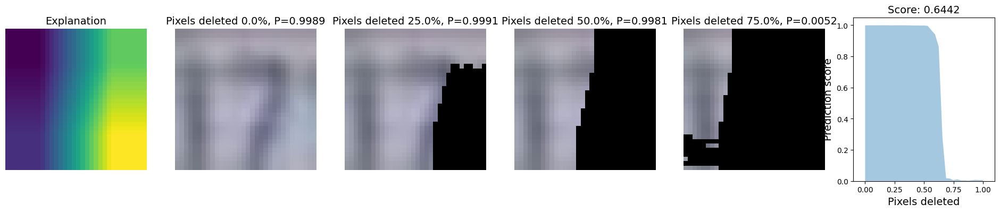

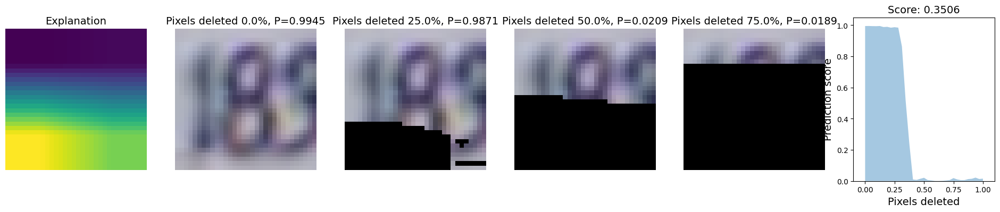

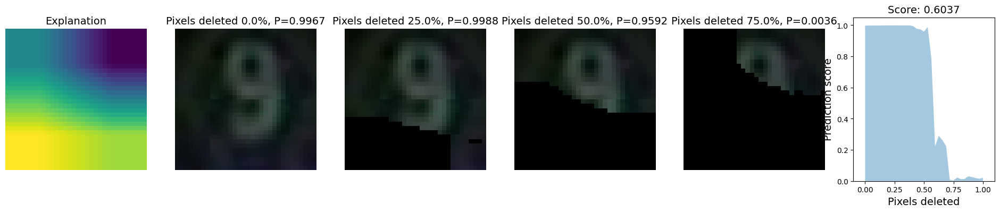

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

101it [00:00, 578.70it/s]

0
100
200


352it [00:00, 1003.92it/s]

300
400
500


688it [00:00, 1186.07it/s]

600
700
800


818it [00:00, 949.75it/s] 

900


1000it [00:01, 665.11it/s]


np.float32(3.031467)

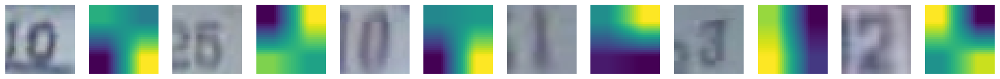

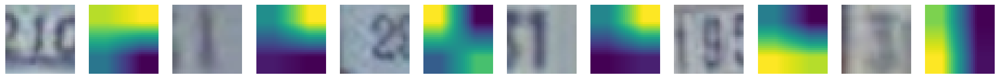

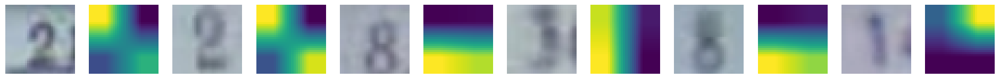

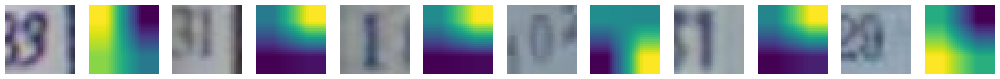

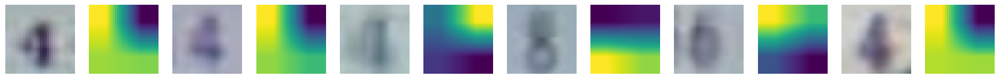

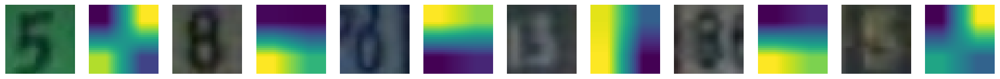

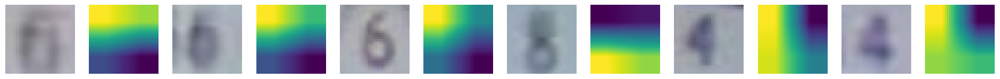

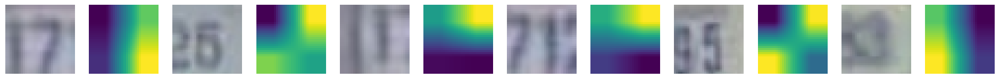

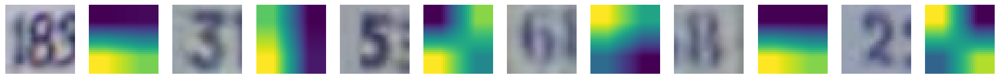

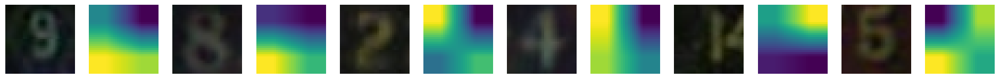

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

true: 1000 wrong: 0 total: 1000


np.float64(0.0)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

true: 999000 wrong: 0 total: 999000


0.0

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

NameError: name 'GradCAMPlusPlusExplainerAdapter' is not defined

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

### Densenet121

In [ ]:
model, target_layers = get_model("densenet121", "svhn")
preprocess_transform = get_preprocess_transform("svhn")
batch_predict = get_batch_predict(model, preprocess_transform)

#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

## Imagenet

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset("imagenet")

RuntimeError: Dataset not found. You can use download=True to download it.

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=100)
imgs = sample_images
print_every_n = int(len(imgs) / 10)

### VGG16_BN

In [ ]:
model, target_layers = get_model("vgg16_bn", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)


#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps1, t = expr.timed_batch_explain(imgs[:250])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime1.npy", exps1)

In [ ]:
exps1 = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime1.npy")

In [ ]:
exps2, t = expr.timed_batch_explain(imgs[250:500])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime2.npy", exps2)

In [ ]:
exps2 = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime2.npy")

In [ ]:
exps3, t = expr.timed_batch_explain(imgs[500:750])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime3.npy", exps3)

In [ ]:
exps3 = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime3.npy")

In [ ]:
exps4, t = expr.timed_batch_explain(imgs[750:])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime4.npy", exps4)

In [ ]:
exps4 = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime4.npy")

In [ ]:
exps = np.concatenate((exps1, exps2, exps3, exps4))

In [ ]:
exps.shape

In [ ]:
exps1_, t = expr.timed_batch_explain(imgs[:250])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime1x.npy", exps1_)

In [ ]:
exps1_ = np.load("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime1x.npy")

In [ ]:
exps2_, t = expr.timed_batch_explain(imgs[250:500])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime2x.npy", exps2_)

In [ ]:
exps3_, t = expr.timed_batch_explain(imgs[500:750])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime3x.npy", exps3_)

In [ ]:
exps4_, t = expr.timed_batch_explain(imgs[750:])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_vgg16bn_lime4x.npy", exps4_)

In [ ]:
exps_ = np.concatenate((exps1_, exps2_, exps3_, exps4_))

In [ ]:
exps.shape, exps_.shape

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix in range(ncol-1):
    for i in range(ix * print_every_n, (ix+1) * print_every_n):
        if not np.array_equal(exps[i], exps_[i]):
            axarr[0, ix].imshow(imgs[i])
            axarr[0, ix].axis(False)
            axarr[1, ix].imshow(exps[i])
            axarr[1, ix].axis(False)
            axarr[2, ix].imshow(exps_[i])
            axarr[2, ix].axis(False)
            break

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
torch.cuda.empty_cache()

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix, i in enumerate(range(0, len(imgs), print_every_n)):
    axarr[0, ix].imshow(imgs[i])
    axarr[0, ix].axis(False)
    axarr[1, ix].imshow(exps[i])
    axarr[1, ix].axis(False)
    axarr[2, ix].imshow(exps_[i])
    axarr[2, ix].axis(False)

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

### Resnet50

In [ ]:
model, target_layers = get_model("resnet50", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix in range(ncol-1):
    for i in range(ix * print_every_n, (ix+1) * print_every_n):
        if not np.array_equal(exps[i], exps_[i]):
            axarr[0, ix].imshow(imgs[i])
            axarr[0, ix].axis(False)
            axarr[1, ix].imshow(exps[i])
            axarr[1, ix].axis(False)
            axarr[2, ix].imshow(exps_[i])
            axarr[2, ix].axis(False)
            break

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
torch.cuda.empty_cache()

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix, i in enumerate(range(0, len(imgs), print_every_n)):
    axarr[0, ix].imshow(imgs[i])
    axarr[0, ix].axis(False)
    axarr[1, ix].imshow(exps[i])
    axarr[1, ix].axis(False)
    axarr[2, ix].imshow(exps_[i])
    axarr[2, ix].axis(False)

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

### Densenet121

In [ ]:
model, target_layers = get_model("densenet121", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

#### LIME

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps1, t = expr.timed_batch_explain(imgs[:500])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_lime1.npy", exps1)

In [ ]:
exps2, t = expr.timed_batch_explain(imgs[500:])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_lime2.npy", exps2)

In [ ]:
exps = np.concatenate((exps1, exps2))

In [ ]:
exps1_, t = expr.timed_batch_explain(imgs[:500])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_lime1x.npy", exps1_)

In [ ]:
exps2_, t = expr.timed_batch_explain(imgs[500:])
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
np.save("/content/drive/MyDrive/Uni/thesis/imagenet_densenet121_lime2x.npy", exps2_)

In [ ]:
exps_ = np.concatenate((exps1_, exps2_))

In [ ]:
exps.shape, exps_.shape

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
show_imgs_exps(imgs, exps_, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix, i in enumerate(range(0, len(imgs), print_every_n)):
    axarr[0, ix].imshow(imgs[i])
    axarr[0, ix].axis(False)
    axarr[1, ix].imshow(exps[i])
    axarr[1, ix].axis(False)
    axarr[2, ix].imshow(exps_[i])
    axarr[2, ix].axis(False)

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SHAP

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### GradCAM++

In [ ]:
expr = GradCAMPlusPlusExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### IntGrad

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

#### SmoothGrad

In [ ]:
torch.cuda.empty_cache()

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
exps_, t_ = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t_}")

In [ ]:
show_imgs_exps(imgs, exps, print_every_n)

In [ ]:
scores = calculate_fidelity(imgs, exps, lambda x: expr.batch_predict([x]), step=SIZE, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
scores = calculate_stability(imgs, exps, n=5, print_every=print_every_n)
np.mean(scores), np.std(scores)

In [ ]:
score, true, total = calculate_identity(exps, exps_)
score

In [ ]:
nrow, ncol = 3, 10
plt.figure()
_, axarr = plt.subplots(nrow, ncol, figsize=(3*ncol, 3*nrow))
for ix, i in enumerate(range(0, len(imgs), print_every_n)):
    axarr[0, ix].imshow(imgs[i])
    axarr[0, ix].axis(False)
    axarr[1, ix].imshow(exps[i])
    axarr[1, ix].axis(False)
    axarr[2, ix].imshow(exps_[i])
    axarr[2, ix].axis(False)

In [ ]:
distances = [dist(e, e_) for e, e_ in zip(exps, exps_)]
np.mean(distances), np.std(distances)

In [ ]:
wrong, total, evaluated, score = calculate_separability(exps)
score

## Explanations Example

In [ ]:
ds_names = ["cifar10", "svhn", "imagenet"]
imgs_by_ds = {}
classes_by_ds = {}
models_by_ds = {}
settings_by_ds = {}
ixs = (3,5,8)
n_imgs_per_ds = len(ixs)

for ds_name in ds_names:
    print(ds_name)
    dataset, classes, SIZE, HW, CH = init_dataset(ds_name)
    sample_images, _, _ = get_sample_images(dataset, classes, n_images_per_class=1)

    imgs_by_ds[ds_name] = [sample_images[ix] for ix in ixs]
    classes_by_ds[ds_name] = classes

    settings_by_ds[ds_name] = (SIZE, HW, CH)

    model, target_layers = get_model("resnet50", ds_name)
    preprocess_transform = get_preprocess_transform(ds_name)
    batch_predict = get_batch_predict(model, preprocess_transform)
    models_by_ds[ds_name] = (model, target_layers, preprocess_transform, batch_predict)

In [ ]:
for ds_name in ds_names:
    model, target_layers = get_model("resnet50", ds_name)
    preprocess_transform = get_preprocess_transform(ds_name)
    batch_predict = get_batch_predict(model, preprocess_transform)
    models_by_ds[ds_name] = (model, target_layers, preprocess_transform, batch_predict)

In [ ]:
explainers = {
    "LIME": LimeExplainerAdapter,
    "SHAP": ShapExplainerAdapter,
    "GradCAM": GradCAMExplainerAdapter,
    "GradCAM++": GradCAMPlusPlusExplainerAdapter,
    "IntGrad": IntGradExplainerAdapter,
    "SmoothGrad": SmoothGradExplainerAdapter,
}

In [ ]:
nrow, ncol = len(ixs) * len(imgs_by_ds), 1 + len(explainers)
plt.figure()
imsize = 2
_, axarr = plt.subplots(nrow, ncol, figsize=(imsize*ncol, imsize*nrow))

for i, (ds_name, imgs) in enumerate(imgs_by_ds.items()):
    model, target_layers, preprocess_transform, batch_predict = models_by_ds[ds_name]
    SIZE, HW, CH = settings_by_ds[ds_name]

    preds = [np.argmax(p) for p in batch_predict(imgs)]
    preds = [
        classes_by_ds[ds_name][p]
        if ds_name != "imagenet"
        else classes_by_ds[ds_name][imagenet_idx_to_imagenette[p]][0]
        for p in preds
    ]
    print(preds)
    for k, (img, pred) in enumerate(zip(imgs, preds)):
        ax = axarr[i * n_imgs_per_ds + k, 0]
        ax.imshow(img)
        if i * n_imgs_per_ds + k == 0:
            ax.set_title("Image")

        ax.xaxis.set_ticklabels([])
        ax.yaxis.set_ticklabels([])
        ax.xaxis.set_ticks([])
        ax.yaxis.set_ticks([])
        ax.spines['bottom'].set_color(None)
        ax.spines['top'].set_color(None)
        ax.spines['right'].set_color(None)
        ax.spines['left'].set_color(None)
        ax.set_ylabel(pred, fontsize=14)


    for j, (expr_name, expr_class) in enumerate(explainers.items(), start=1):
        expr = expr_class(model, target_layers, preprocess_transform, SIZE, CH)

        exps, _ = expr.timed_batch_explain(imgs)
        for k, (img, exp) in enumerate(zip(imgs, exps)):
            axarr[i * n_imgs_per_ds + k, j].imshow(exp)
            axarr[i * n_imgs_per_ds + k, j].axis("off")
            if (i * n_imgs_per_ds + k) == 0:
                axarr[ i * n_imgs_per_ds + k, j].set_title(expr_name, fontsize=14)

## Stability example

## Fidelity example

In [ ]:
ds_name = "imagenet"

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset(ds_name)

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=10)

In [ ]:
model, target_layers = get_model("resnet50", ds_name)
preprocess_transform = get_preprocess_transform(ds_name)
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
import json
with open("/content/imagenet_class_index.json", "r") as f:
    imagenet_classes = json.load(f)

In [ ]:
imgs = [sample_images[3]]
pfunc = lambda x: expr.batch_predict([x])
get_class = lambda x: imagenet_classes[int(x)]

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

In [ ]:
ds_name = "svhn"

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset(ds_name)

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=10)

In [ ]:
model, target_layers = get_model("resnet50", ds_name)
preprocess_transform = get_preprocess_transform(ds_name)
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
sample_images[52]

In [ ]:
imgs = [sample_images[51], sample_images[52]]
pfunc = lambda x: expr.batch_predict([x])
get_class = lambda x: classes[int(x)]

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

In [ ]:
expr = SmoothGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)
exps, t = expr.timed_batch_explain(imgs)

In [ ]:
calculate_fidelity(imgs, exps, pfunc, step=SIZE, print_every=1, get_class=get_class)

## Identity example

In [ ]:
ds_name = "imagenet"

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset(ds_name)

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=10)

In [ ]:
sample_images[66]

In [ ]:
imgs = [sample_images[11], sample_images[42], sample_images[66]]
n_imgs = len(imgs)

In [ ]:
model, target_layers = get_model("resnet50", ds_name)
preprocess_transform = get_preprocess_transform(ds_name)
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
explainers = {
    "LIME": LimeExplainerAdapter,
    "SmoothGrad": SmoothGradExplainerAdapter,
}

In [ ]:
preds = [np.argmax(p) for p in batch_predict(imgs)]
preds = [
    classes[p]
    if ds_name != "imagenet"
    else classes[imagenet_idx_to_imagenette[p]][0]
    for p in preds
]
print(preds)

In [ ]:
nrow, ncol = 1 + len(explainers), n_imgs * 2
plt.figure()
imsize = 2
_, axarr = plt.subplots(nrow, ncol, figsize=(imsize*ncol, imsize*nrow))

for k, (img, pred) in enumerate(zip(imgs, preds)):
    for i in range(2):
        ax = axarr[0, k * 2 + i]
        ax.imshow(img)
        # ax.axis("off")
        if k * 2 + i == 0:
            ax.set_ylabel("Image", fontsize=14)

        ax.set_title(pred)
        ax.xaxis.set_ticklabels([])
        ax.yaxis.set_ticklabels([])
        ax.xaxis.set_ticks([])
        ax.yaxis.set_ticks([])
        ax.spines['bottom'].set_color(None)
        ax.spines['top'].set_color(None)
        ax.spines['right'].set_color(None)
        ax.spines['left'].set_color(None)

for j, (expr_name, expr_class) in enumerate(explainers.items(), start=1):
    expr = expr_class(model, target_layers, preprocess_transform, SIZE, CH)
    for k, img in enumerate(imgs):
        exp1, _ = expr.timed_single_explain(img)
        exp2 = exp1
        while np.array_equal(exp1, exp2):
            exp2, _ = expr.timed_single_explain(img)
        for i, exp in enumerate((exp1, exp2)):
            ax = axarr[j, k * 2 + i]
            ax.imshow(exp)
            if (k * 2 + i) == 0:
                ax.set_ylabel(expr_name, fontsize=14)

            ax.xaxis.set_ticklabels([])
            ax.yaxis.set_ticklabels([])
            ax.xaxis.set_ticks([])
            ax.yaxis.set_ticks([])
            ax.spines['bottom'].set_color(None)
            ax.spines['top'].set_color(None)
            ax.spines['right'].set_color(None)
            ax.spines['left'].set_color(None)

## Imagenette accuracy calculation

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset("imagenet")

In [ ]:
model, target_layers = get_model("vgg16_bn", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
res = []
for img, cls in tqdm(dataset):
    res.append(imagenet_idx_to_imagenette.get(np.argmax(batch_predict([img])[0])) == cls)
np.mean(res)

In [ ]:
model, target_layers = get_model("resnet50", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
res = []
for img, cls in tqdm(dataset):
    res.append(imagenet_idx_to_imagenette.get(np.argmax(batch_predict([img])[0])) == cls)
np.mean(res)

In [ ]:
model, target_layers = get_model("densenet121", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
res = []
for img, cls in tqdm(dataset):
    res.append(imagenet_idx_to_imagenette.get(np.argmax(batch_predict([img])[0])) == cls)
np.mean(res)

## Stability v2 comparison (using noisy images)

In [ ]:
dataset, classes, SIZE, HW, CH = init_dataset("imagenet")

In [ ]:
sample_images, sample_labels, sample_images_by_class = get_sample_images(dataset, classes, n_images_per_class=1)
imgs = sample_images
print_every_n = int(len(imgs) / 10)

In [ ]:
model, target_layers = get_model("resnet50", "imagenet")
preprocess_transform = get_preprocess_transform("imagenet")
batch_predict = get_batch_predict(model, preprocess_transform)

In [ ]:
expr = LimeExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
scores = calculate_stability_v2(imgs, exps, lambda x: expr.timed_single_explain(x)[0])
np.mean(scores)

In [ ]:
expr = ShapExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
scores = calculate_stability_v2(imgs, exps, lambda x: expr.timed_single_explain(x)[0])
np.mean(scores)

In [ ]:
expr = GradCAMExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
scores = calculate_stability_v2(imgs, exps, lambda x: expr.timed_single_explain(x)[0])
np.mean(scores)

In [ ]:
expr = IntGradExplainerAdapter(model, target_layers, preprocess_transform, SIZE, CH)

In [ ]:
exps, t = expr.timed_batch_explain(imgs)
print(f"Mean time for {len(imgs)} explanations: {t}")

In [ ]:
scores = calculate_stability_v2(imgs, exps, lambda x: expr.timed_single_explain(x)[0])
np.mean(scores)

# Task
The user wants to enhance the existing experiment notebook by implementing a robust save and load mechanism for intermediate results and final metric scores. This will prevent re-computation of lengthy experiments and ensure persistent storage of results, making the experimentation process more efficient.

I will implement the following steps:

1.  **Define Utility Function for Save/Load**: Create two Python functions, `save_data` and `load_data`.
    *   `save_data(data, dataset_name, model_name, explainer_name, variable_name)`: This function will take the data (NumPy array or scalar), along with contextual names (dataset, model, explainer, and a descriptive variable name), construct a file path within `/content/drive/MyDrive/Uni/thesis/results/`, create necessary directories, and save the data using `np.save`. It will handle scalars by wrapping them in `np.array` before saving.
    *   `load_data(dataset_name, model_name, explainer_name, variable_name)`: This function will construct the same file path. If the file exists, it will load the data using `np.load`, convert 0-dimensional arrays back to scalars if applicable, and return it. If the file does not exist, it will return `None`.

2.  **Implement Save/Load for CIFAR10 Experiments**:
    *   For each explainer (LIME, SHAP, GradCAM, GradCAM++, IntGrad, SmoothGrad) under each model (VGG16_BN, Resnet50, Densenet121) in the CIFAR10 section, I will integrate `save_data` and `load_data`.
    *   Before computing `exps` and `t` (explanation results and mean computation time), I will attempt to `load_data`. If not found, `exps` and `t` will be computed and then saved.
    *   The same logic will be applied for `exps_` and `t_` (repeated explanation results and mean computation time).
    *   For each metric (`calculate_fidelity`, `calculate_stability`, `calculate_identity`, `calculate_separability`), I will check if the corresponding `scores` variable (e.g., `fidelity_scores`, `stability_scores`, `identity_score`, `separability_score`) can be loaded. If not, the metric will be computed, and its result (the primary score as per the plan) will be saved.

3.  **Implement Save/Load for SVHN Experiments**:
    *   I will apply the exact same strategy as described for CIFAR10 experiments to the SVHN dataset section.

4.  **Implement Save/Load for Imagenet Experiments**:
    *   For the Imagenet LIME experiments, which currently use chunked saving/loading:
        *   I will modify the chunked `np.save` and `np.load` calls to use the new `save_data` and `load_data` utility functions for `exps` and `exps_` chunks.
        *   I will ensure that the overall mean `t` and `t_` (across all chunks) are computed and saved/loaded. If any part (overall `t` or any `exps` chunk) is missing, the entire computation for that variable will be re-run and saved.
    *   For other explainers (SHAP, GradCAM, GradCAM++, IntGrad, SmoothGrad) under each model (VGG16_BN, Resnet50, Densenet121) in the Imagenet section, I will follow the same save/load strategy as for CIFAR10 and SVHN.

5.  **Review and Verify**: After implementing the save/load logic, I will review the modified cells to ensure correctness, proper variable naming, and that all requested variables (`exps`, `t`, `exps_`, `t_`, `fidelity_scores`, `stability_scores`, `identity_score`, `separability_score`) are handled persistently.

6.  **Final Task**: I will ensure the notebook, after modifications, clearly demonstrates that `exps`, `t`, and metric `scores` are persistently stored and can be reloaded to resume experiments efficiently.

This detailed plan ensures comprehensive implementation of the save/load functionality across all specified experiments, enhancing the robustness and reusability of the notebook.

## Define Utility Function for Save/Load

### Subtask:
Create a Python utility function that handles saving and loading NumPy arrays or scalar values (for `t`, `t_`, and various `scores`). This function will construct file paths using `dataset_name`, `model_name`, `explainer_name`, and a descriptive `variable_name` (e.g., 'exps', 't', 'fidelity_scores'). It will check if a file exists before computing, loading if present, and saving if newly computed.


**Reasoning**:
I will define the `save_data` and `load_data` utility functions as instructed. These functions will handle file path construction, directory creation, and saving/loading of NumPy arrays and scalar values to/from Google Drive, enabling efficient storage and retrieval of experiment results.



In [ ]:
import os
import numpy as np
from pathlib import Path

base_results_dir = Path("/content/drive/MyDrive/Uni/thesis/results/")

def save_data(data, dataset_name, model_name, explainer_name, variable_name):
    # Construct the directory path
    dir_path = base_results_dir / dataset_name / model_name / explainer_name
    os.makedirs(dir_path, exist_ok=True)

    # Construct the full file path
    file_path = dir_path / f'{variable_name}.npy'

    # Convert scalar to NumPy array before saving if it's a scalar
    if np.isscalar(data):
        data_to_save = np.array(data)
    else:
        data_to_save = data

    # Save the data
    np.save(file_path, data_to_save)
    print(f"Data saved to: {file_path}")

def load_data(dataset_name, model_name, explainer_name, variable_name):
    # Construct the directory path
    dir_path = base_results_dir / dataset_name / model_name / explainer_name

    # Construct the full file path
    file_path = dir_path / f'{variable_name}.npy'

    # Check if the file exists
    if file_path.is_file():
        # Load the data
        loaded_data = np.load(file_path)
        print(f"Data loaded from: {file_path}")
        # If the loaded data is a 0-dimensional array, convert it to a scalar
        if loaded_data.ndim == 0:
            return loaded_data.item()
        return loaded_data
    else:
        print(f"File not found: {file_path}")
        return None